# 04 · EDA multivariado: fundamentales (parte 1)

**Términos que se usan en este notebook:** [P/E](../docs/entrega_1/glosario.md) (precio ÷ utilidad por acción: cuántos años de utilidades paga el precio), [P/E normalizado](../docs/entrega_1/glosario.md) (precio ÷ EPS promedio de los 12 trimestres más recientes ya publicados; promediar varios años evita que un año excepcional haga parecer barata una acción que no lo es), [EPS](../docs/entrega_1/glosario.md) (utilidad por acción), [EPS TTM](../docs/entrega_1/glosario.md) (utilidad por acción de los últimos 12 meses), [P/B](../docs/entrega_1/glosario.md) (precio ÷ valor en libros por acción), [ROE](../docs/entrega_1/glosario.md), [margen operativo](../docs/entrega_1/glosario.md), [deuda/patrimonio](../docs/entrega_1/glosario.md), [filed](../docs/entrega_1/glosario.md) (fecha en que la SEC publicó el dato; nada en t usa un dato con filed > t), [split](../docs/entrega_1/glosario.md) (división de cada acción en varias, sin cambiar el valor de la empresa), [quintil](../docs/entrega_1/glosario.md) (cada uno de los 5 grupos de igual tamaño que resultan de ordenar los valores de menor a mayor), [percentil expansivo](../docs/entrega_1/glosario.md) (percentil del valor de hoy dentro de toda su historia hasta hoy; por **convención del proyecto** incluye el valor de hoy, sin mirar al futuro), [quintil por fecha](../docs/entrega_1/glosario.md) (quintiles de las 21 empresas en cada fecha, ordenadas por el percentil propio del P/E normalizado), [bootstrap por empresa](../docs/entrega_1/glosario.md) (remuestreo con reemplazo de empresas completas; conserva el solapamiento de ventanas de una misma empresa), [bootstrap por bloques](../docs/entrega_1/glosario.md) (remuestreo de tramos consecutivos de fechas; conserva la dependencia dentro de una misma fecha), [IC](../docs/entrega_1/glosario.md) (intervalo de confianza al 95 %), [exceso sobre el XLP](../docs/entrega_1/glosario.md) (retorno de la acción menos el del [XLP](../docs/entrega_1/glosario.md) en la misma ventana; dentro del sector, aisla la diferencia frente al choque común) [censura](../docs/entrega_1/glosario.md) (una observación con resultado todavía no ocurrido, en P2 y P3 las fechas de los últimos 3 años), [nulo calibrado por simulación](../docs/entrega_1/glosario.md) (tasa de referencia obtenida simulando el 'escenario sin efecto' con las ventanas reales; nb03 §4) y [p bilateral equivalente](../docs/entrega_1/glosario.md) (2 · p unilateral; convierte el p-value bootstrap a la misma escala del IC95 bilateral que decide todo el proyecto; nb04 §8).

**Objetivo.** EDA multivariado de las 21 empresas de la industria piloto (consumo defensivo) juntas: su valoración y su retorno a 3 años. Las dos primeras preguntas de la rama fundamental, con la [plantilla de inferencia](../docs/entrega_1/04_enfoque_analitico.md): umbral práctico → H0/H1 y α → prueba con sus supuestos verificados → estimación con IC antes del p-value → tamaño del efecto con IC → dos decisiones (estadística y de negocio) → implicación y limitaciones. Las [reglas de series de tiempo](../notebooks/03_eda_univariado.ipynb) de nb03 §0 se mantienen aquí: nada en t usa un dato publicado después de t.

**Punto del enunciado que cubre.** Punto 6 (entendimiento de los datos, 35 %), rama multivariada: tablas y gráficos que relacionan varias variables al mismo tiempo (P/E normalizado × tiempo × empresa × retorno).

**Tabla de equivalencias pregunta de negocio → sección (orden P1–P6).** P2 → §2, P3 → §3, P4 → §5, P5 → §6 (§4–§6 llegan en las tareas 8a y 8b: continúa en §4).

**Qué alimenta.** Las lecturas fundamentales comparativas de los 6 niveles del producto (percentil propio del P/E normalizado para el nivel de "barata frente a su historia"; descomposición en precio y utilidad promedio para distinguir rebote, normalización y trampa de valor).


In [1]:
import json, sys, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*round has no effect.*")   # .round() en tablas con fechas: solo redondea los números
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)

# Constantes del notebook (qué significan y por qué ese valor: docs/entrega_1/04_enfoque_analitico.md §4.5)
HORIZONTE_ANIOS   = 3           # años: ventana de valor de P2 y P3 (horizonte típico del inversor de largo plazo)
HORIZONTE         = 12          # trimestres de 3 años; una observación por empresa y trimestre calendario
HORIZONTES_SENS   = (2, 4)      # sensibilidades (sin decisión); P3 añade 1 año (exploración previa que motivó el horizonte)
UMBRAL_P2         = 0.03        # diferencia anualizada en log del Δlog(P/E normalizado): estimado ÷ 3; ≈ 9 % en 3 años
UMBRAL_P3         = 0.05        # diferencia anualizada en log del exceso sobre el XLP: estimado ÷ 3; ≈ 16 % en 3 años
VENTANA_NORM      = 12          # trimestres del promedio del EPS (3 años; Graham y Dodd 1934; Shiller 1998)
ANTIGUEDAD_MAX    = 548         # días desde el cierre del último trimestre a partir de los cuales el dato se considera rancio
QUINTIL           = 0.2         # fracción de empresas de cada extremo en cada fecha (quintil barato ≤ 0,2; caro > 0,8)
HIST_MIN_PERCENTIL = 52         # semanas mínimas para calcular el percentil expansivo (un año bursátil)
MIN_EMPRESAS_FECHA = 15         # una fecha entra a los quintiles solo con ≥ 15 empresas con dato (regla fijada antes de estimar)
REPS_BOOT         = 1000        # réplicas del bootstrap (percentiles al 95 % ya estables)
RNG_SEMILLA       = 42          # semilla reproducible para todas las remuestras
ALFA              = 0.05        # α; equivale al IC95
NIVEL_IC          = 0.95        # nivel del IC
Z_80              = 2.80        # z para el MDE a potencia 80 % con el criterio bilateral (z_{0,975} + z_{0,8} ≈ 1,96 + 0,84 = 2,80): conservador frente a una H1 unilateral; mantiene la coherencia con los IC95 bilaterales que decide todo el proyecto
BLOQUE_FECHAS     = 4           # bloque del bootstrap por fechas trimestrales (sensibilidad; 1 año = 4 trimestres)

# --- Constantes de §6 (P5), §7-§9 (síntesis) ---
UMBRAL_P5         = 0.05           # ΔR² mediano mínimo del XLP sobre SPY para que el sector sea accionable
VIF_UMBRAL        = 10             # umbral habitual del VIF (|VIF| > 10 señala colinealidad problemática)
PCA_COMPONENTES   = 3              # PC1-PC3 de los 21 retornos semanales (mercado + subgrupos)
HOLM_ALFA         = 0.05           # α global de la sensibilidad Holm sobre las 13 pruebas con decisión
HOLM_M            = 13             # pruebas con decisión de negocio (15 declaradas − 2 controles de dirección)
SUBPERIODOS_P5    = {"2009–2012": ("2009", "2012"), "2013–2019": ("2013", "2019"),
                     "2020–2021": ("2020", "2021"), "2022+": ("2022", "2026")}   # los mismos tramos de nb03

ASSETS = cm.DIR_ASSETS; ASSETS.mkdir(parents=True, exist_ok=True)
print("constantes definidas; carpeta de figuras:", ASSETS)

# --- Constantes de §4 (etiqueta diaria, elección de N) y §5 (P4): ---
# N: días hábiles del horizonte "¿toca el nivel?"; se elige el ganador por AUC con solo 2009–2018.
N_CANDIDATOS      = (20, 40, 60)   # 1, 2 o 3 meses bursátiles; los dicta el usuario ("1 mes o más")
K_SIGMA           = 1              # el nivel está a 1 volatilidad diaria · √N bajo el precio (A2)
BALANCE_LO        = 0.10           # tasa de toque mínima en 2009–2018; con menos hay muy pocos positivos
BALANCE_HI        = 0.40           # tasa máxima; con más el nivel se toca casi siempre
SIGMA_VENTANA_D   = 252            # días hábiles para σ252 (un año bursátil; convención)
SIGMA_CORTA_D     = 20             # días hábiles para σ20 (un mes bursátil)
FIN_AJUSTE_N      = "2015-12-31"   # elección de N: ajuste 2009-01-01 a 2015-12-31
INICIO_VALID_N    = "2016-01-01"   # validación para elegir N; se corre con márgenes de N días (2016+N; 2018-N)
CORTE_ENTRENAMIENTO = "2018-12-31" # fin del entrenamiento del modelo A y del cálculo de deciles
INICIO_PRUEBA     = "2019-01-01"   # inicio del tramo de prueba (2019+ con N días de espacio inicial)
DECILES_SIGMA     = 10             # grupos de la línea base por decil de σ252 diaria
UMBRAL_P4         = 0.01           # ΔAUC mínima por indicador para que entre al SVM
REPS_P4           = 5000           # réplicas del bootstrap de P4 (nivel ≈ 99,3 % necesita más réplicas)
NIVEL_P4          = 1 - 0.05 / 7   # ≈ 0,993; Bonferroni por los 7 indicadores (percentiles 0,36 y 99,64)
BLOQUE_P4_SESIONES = 60            # tamaño del bloque del bootstrap en sesiones (~ un trimestre bursátil)
RHO_REDUNDANCIA   = 0.80           # |Spearman| ≥ 0,80 → uno de los dos indicadores sale (regla fijada antes)
INDICADORES_7     = ("rsi14", "dist_sma20", "dist_sma50", "dist_sma200", "vol_rel20", "donchian20", "mom_12_1")


constantes definidas; carpeta de figuras: /Users/lgualtero/Projects/Personal/uniandes/data-science-applied/proyecto_final/entregables/entrega_1/assets


## 0.1 Carga de datos

Se cargan tres instantáneas de `data/snapshots/`: `precios_semanales_sd` (precio **sin ajuste por dividendos**: refleja lo que paga el inversor en spot, es el numerador correcto del P/E), `precios_semanales` (precio ajustado por dividendos: el que corresponde al retorno total del inversor, se usa en §3 para P3) y `ratios_ttm` (una fila por cierre de trimestre con los flujos TTM, los saldos, las acciones y los ratios, cada uno con su columna `filed_<ratio>`). También `splits`, que lleva el EPS y el valor en libros a las acciones de hoy. Toda instantánea se filtra con `cm.tickers() + ['XLP']` al cargarla, así una instantánea vieja no contamina nada.

In [2]:
acciones = cm.tickers()                                   # 21 empresas de consumo defensivo
cols_px = acciones + ["XLP"]                               # el XLP entra en §3 como referencia del sector
sem_sd = cm.cargar_snapshot("precios_semanales_sd")        # precio sin ajuste por dividendos (numerador del P/E)
sem_sd = sem_sd[sem_sd.ticker.isin(cols_px)].copy()
sem_ad = cm.cargar_snapshot("precios_semanales")           # precio ajustado por dividendos (retorno total, §3 P3)
sem_ad = sem_ad[sem_ad.ticker.isin(cols_px)].copy()
ttm = cm.cargar_snapshot("ratios_ttm")                      # ratios TTM con su filed_<ratio>
ttm = ttm[ttm.ticker.isin(acciones)].copy()
splits_all = cm.cargar_snapshot("splits")                   # un split lleva el EPS y el valor en libros a las acciones de hoy
splits_all = splits_all[splits_all.ticker.isin(acciones)].copy()

# Normalizar la precisión de todas las fechas a datetime64[ns] (los parquet traen ms/us y merge_asof exige igual precisión)
for _df in (sem_sd, sem_ad):
    _df["fecha"] = _df["fecha"].astype("datetime64[ns]")
for _c in ttm.columns:
    if str(ttm[_c].dtype).startswith("datetime64"):
        ttm[_c] = ttm[_c].astype("datetime64[ns]")
splits_all["fecha"] = splits_all["fecha"].astype("datetime64[ns]")

print(f"precios semanales sd:   {sem_sd.shape[0]:,} filas × {sem_sd.ticker.nunique()} tickers "
      f"({sem_sd.fecha.min().date()} a {sem_sd.fecha.max().date()})")
print(f"precios semanales ad:   {sem_ad.shape[0]:,} filas × {sem_ad.ticker.nunique()} tickers")
print(f"ratios_ttm:             {ttm.shape[0]:,} filas × {ttm.ticker.nunique()} tickers "
      f"(cierres {ttm['end'].min().date()}–{ttm['end'].max().date()})")
print(f"splits (desde {cm.INICIO}):", len(splits_all[splits_all.fecha >= cm.INICIO]),
      "en", splits_all[splits_all.fecha >= cm.INICIO].ticker.nunique(), "empresas")


precios semanales sd:   20,416 filas × 22 tickers (2009-01-05 a 2026-10-12)
precios semanales ad:   20,416 filas × 22 tickers
ratios_ttm:             1,434 filas × 21 tickers (cierres 2009-05-31–2026-09-05)
splits (desde 2009-01-01): 10 en 9 empresas


## 0.2 Funciones de este notebook

Las usa solo este notebook; lo que varios notebooks comparten (universo, carga, bootstrap) vive en `comunes.py`.

**`ajustar_por_splits`** lleva `eps_ttm`, `bvps` y `eps_prom_3a` a las acciones de hoy: cada valor se divide por el producto de los splits con `fecha` posterior a **su propia** fecha `filed_<ratio>` (nb02 §3; fecha por ratio). Un detalle del `eps_prom_3a`: nb01 ya lo construye como "promedio del EPS trimestral de los 12 últimos trimestres ÷ acciones del último trimestre de la ventana", así que **dentro** de la ventana un split queda neutralizado; pero las acciones del último trimestre de la ventana son las de ese trimestre, **no las de hoy**, así que un split **posterior** a `filed_eps_prom_3a` sí hay que dividirlo (si no, se compararía precio en acciones de hoy con EPS en acciones de ayer). La función hace exactamente eso: no duplica el ajuste de los splits dentro de la ventana.

**`ultimo_publicado`** devuelve, para cada semana, el último valor del concepto con `filed_<col>` ≤ esa semana (merge_asof hacia atrás), con empates resueltos por el trimestre más reciente. Un dato con más de `ANTIGUEDAD_MAX` días desde el cierre de su último trimestre se marca como rancio y queda vacío (temporalidad: #9 de los 10-Q, nb02 §3).

**`multiplos_semanales`** arma el panel semanal por ticker con precio sin dividendos, P/E (EPS TTM), P/E normalizado (EPS promedio de 3 años), P/B y las columnas de contexto (ROE, margen operativo, deuda/patrimonio), cada una con su `filed` de origen (los ratios con EPS ≤ 0 o patrimonio ≤ 0 ya quedan vacíos en nb01).

**`percentil_expansivo`** es el percentil del valor de hoy dentro de **toda** su historia hasta hoy; con `min_periods = 52` semanas (un año) un percentil con menos historia queda vacío.

In [3]:
def ajustar_por_splits(r, splits):
    """Lleva eps_ttm/bvps/eps_prom_3a a las acciones de hoy: divide por los splits posteriores a SU fecha de publicación.

    nb01 ya neutraliza los splits DENTRO de la ventana del eps_prom_3a (todos los trimestres se dividen por las
    acciones del último trimestre de la ventana), así que no hay doble división: aquí se corrigen solo los splits
    POSTERIORES a esa fecha, para alinear con el precio actual (sin dividendos, pero ajustado por splits).
    """
    out = r.copy()
    if splits is None or splits.empty:
        return out
    fechas = pd.to_datetime(splits["fecha"]).to_numpy()
    razones = splits["ratio"].to_numpy(dtype=float)
    for col in ("eps_ttm", "bvps", "eps_prom_3a"):
        factor = out[f"filed_{col}"].map(
            lambda f: 1.0 if pd.isna(f) else float(np.prod(razones[fechas > np.datetime64(f)])))
        out[col] = out[col] / factor
    return out


def ultimo_publicado(fechas_precio, r, col):
    """Para cada semana, el último valor de `col` ya publicado (filed_<col> ≤ fecha); empate → trimestre más reciente.

    #9 de los 10-Q (temporalidad): un dato de más de 548 días desde el cierre de su último trimestre es rancio → vacío.
    """
    f = (r[["end", col, f"filed_{col}"]].dropna(subset=[f"filed_{col}"])
           .sort_values([f"filed_{col}", "end"], kind="stable")
           .drop_duplicates(f"filed_{col}", keep="last"))
    m = pd.merge_asof(pd.DataFrame({"fecha": fechas_precio.astype("datetime64[ns]")}),
                      f.rename(columns={f"filed_{col}": "filed"})
                       .assign(filed=lambda d: d.filed.astype("datetime64[ns]"))
                       .assign(end=lambda d: d["end"].astype("datetime64[ns]")),
                      left_on="fecha", right_on="filed", direction="backward")
    rancio = (m["fecha"] - m["end"]).dt.days > ANTIGUEDAD_MAX
    return m[col].where(~rancio).to_numpy()


def multiplos_semanales(precios_sd, r, cols=("eps_ttm", "bvps", "eps_prom_3a", "roe_ttm",
                                             "margen_operativo_ttm", "deuda_patrimonio")):
    """Panel semanal por ticker: precio sin dividendos, P/E (EPS TTM), P/E normalizado (EPS promedio 3 años, R7),
    P/B, y ROE/margen/deuda como contexto. Cada columna llega con SU propio filed_<col> (sin look-ahead).
    EPS ≤ 0 → P/E sin sentido (ya vacío desde nb01)."""
    m = precios_sd[["fecha", "close"]].dropna().sort_values("fecha").reset_index(drop=True)
    for col in cols:
        m[col] = ultimo_publicado(m["fecha"].to_numpy("datetime64[ns]"), r, col)
    m["pe"]      = m["close"] / m["eps_ttm"].where(m["eps_ttm"] > 0)
    m["pe_norm"] = m["close"] / m["eps_prom_3a"].where(m["eps_prom_3a"] > 0)   # R7: "barata frente a su historia"
    m["pb"]      = m["close"] / m["bvps"].where(m["bvps"] > 0)
    return m


def percentil_expansivo(serie, min_obs=HIST_MIN_PERCENTIL):
    """Percentil del valor de hoy dentro de TODA su historia hasta hoy (no mira al futuro)."""
    def _pct(w):
        if np.isnan(w[-1]):
            return np.nan
        v = w[~np.isnan(w)]
        return float((v <= w[-1]).mean()) if len(v) else np.nan
    return serie.expanding(min_periods=min_obs).apply(_pct, raw=True)


## 1. Panel de múltiplos semanales (EDA multivariado no gráfico)

Para cada ticker se arma su panel semanal con `multiplos_semanales(precios_sd, ajustar_por_splits(ratios, splits))`, se concatenan en un solo panel largo (`fecha`, `ticker`, columnas), y se agrega `pct_norm` = `percentil_expansivo` del P/E normalizado (percentil del valor de hoy dentro de toda su historia hasta hoy, con mínimo de 52 semanas). Es el insumo de todo el resto del notebook.

In [4]:
paneles = []
for t in acciones:
    pr = sem_sd[sem_sd.ticker == t].copy()
    rt = ttm[ttm.ticker == t].copy()
    sp = splits_all[splits_all.ticker == t]
    rt_adj = ajustar_por_splits(rt, sp)
    panel_t = multiplos_semanales(pr, rt_adj)
    panel_t["ticker"] = t
    panel_t["pct_norm"] = percentil_expansivo(panel_t["pe_norm"])
    paneles.append(panel_t)
panel = pd.concat(paneles, ignore_index=True)
print(f"panel semanal: {len(panel):,} filas × {panel.ticker.nunique()} tickers")
print(f"rango: {panel.fecha.min().date()} a {panel.fecha.max().date()}")

cobertura = panel.groupby("ticker").agg(
    semanas_pe      = ("pe", lambda s: s.notna().sum()),
    semanas_pe_norm = ("pe_norm", lambda s: s.notna().sum()),
    semanas_pb      = ("pb", lambda s: s.notna().sum()),
    inicio_pe_norm  = ("pe_norm", lambda s: panel.loc[s.index[s.notna()], "fecha"].min() if s.notna().any() else pd.NaT),
).round(0)
print()
print("Cobertura por empresa (primera columna: nunca sin EPS TTM; segunda: necesita 12 trimestres):")
print(cobertura.to_string())
print()
print(f"Primera semana con P/E normalizado disponible en el panel: {panel[panel.pe_norm.notna()].fecha.min().date()}")


panel semanal: 19,488 filas × 21 tickers
rango: 2009-01-05 a 2026-10-12

Cobertura por empresa (primera columna: nunca sin EPS TTM; segunda: necesita 12 trimestres):
        semanas_pe  semanas_pe_norm  semanas_pb inicio_pe_norm
ticker                                                        
ADM            834              782         884     2011-08-29
CAG            714              652         837     2011-07-25
CHD            806              764         845     2012-02-27
CL             846              794         582     2011-08-01
CLX            842              790         703     2011-08-29
COST           835              783         878     2011-10-17
GIS            823              797         838     2011-07-11
HSY            372              295         411     2011-08-15
KMB            832              780         721     2011-11-07
KO             833              781         868     2011-10-31
KR             851              787         890     2011-09-19
MDLZ           

**Lectura (2–4 frases con cifras).** El panel reúne las 21 empresas con una media de ~900 semanas de precio por empresa; la cobertura del P/E (EPS TTM) ronda las 850 semanas en la mayoría (STZ queda sin EPS porque le faltan las acciones en `ratios_ttm` desde nb01, y HSY se queda sin EPS a partir de 2015 por la misma razón). La cobertura del P/E normalizado es menor (necesita 12 trimestres y el percentil exige al menos un año de historia): la primera semana con dato llega hacia **2012–2013** y la cobertura por empresa queda en ~700 semanas en las que entran al estudio. El P/B tiene cobertura intermedia (depende del valor en libros, que sí existe para STZ).

## 2. P2 — ¿el "barata frente a su historia" es temporal? (horizonte de 3 años)

**Lector sin finanzas (en lenguaje simple):** cuando una acción tiene un P/E (precio ÷ utilidad) **bajo frente a su propia historia** se habla de "barata frente a su historia". ¿Eso tiende a corregirse (el múltiplo sube, en 3 años, más que el de las que están caras)? Si sí, el nivel de entrada que marca "barata frente a su historia" es informativo para el inversor; si no, es ruido.

**Por qué el P/E normalizado (en lugar del P/E TTM).** Un año de utilidades excepcionales (bueno o malo) puede hacer que una acción parezca barata o cara sin serlo; promediar varios años de utilidades evita esa ilusión. El P/E normalizado es precio ÷ **EPS promedio de los 12 trimestres más recientes ya publicados** (`eps_prom_3a`). La convención viene de Graham y Dodd (1934), que recomendaban 5–10 años, y Campbell y Shiller (1998, DOI 10.3905/jpm.24.2.11) usan 10 años. Aquí se usan 3 años porque los fundamentales estructurados en EDGAR empiezan en 2009 (limitación de datos; se declara en §2.9). El P/E con EPS TTM sigue siendo el P/E "actual" del producto; se usa como contexto y en el panel semanal.

### 2.1 Paso 0: umbral práctico

El paso 0 de la plantilla de inferencia fija, **antes** de ver el resultado, la diferencia mínima que cambiaría la decisión. Aquí: la diferencia anualizada en log (estimado del Δlog(P/E normalizado) a 3 años ÷ 3) entre el quintil barato y el caro debe superar `UMBRAL_P2 = 0,03` (≈ 9 % en 3 años). En palabras: *si la valoración de las baratas no sube al menos un 9 % más que la de las caras en 3 años, "barata frente a su historia" no anuncia una normalización que valga la pena esperar*.

### 2.2 H0, H1 y α

- **H0:** el cambio medio de log(P/E normalizado) a 3 años es igual en el quintil barato y en el caro de cada fecha.
- **H1:** el barato sube su P/E normalizado más que el caro (prueba unilateral).
- **α = 0,05**, equivalente a un IC del 95 %.
- **Decisión estadística:** se rechaza H0 si el IC por empresa de la diferencia excluye 0.
- **Decisión de negocio:** accionable si el límite inferior del IC anualizado (÷ 3) supera `UMBRAL_P2`; si lo cruza, "efecto real, pero de magnitud incierta"; si no se rechaza H0, no accionable (misma regla que nb03).

La **H0 equivale** a "el múltiplo se mueve como un paseo aleatorio". Puede rechazarse por **regresión a la media** (un valor extremo con una parte de azar tiende a quedar menos extremo después); por eso la pregunta real la responden la decisión de negocio (¿la diferencia supera el 9 % en 3 años?) y la descomposición en precio y utilidad (¿el movimiento viene del precio, de la utilidad promedio o de ambos?).

### 2.3 Unidad y grupos (una observación por empresa y trimestre calendario)

Los 10-Q y 10-K de las 21 empresas llegan en fechas distintas. Para ordenar a todas en la misma fecha sin mirar al futuro se usa el **último día de cada trimestre calendario**: en cada fecha trimestral, por empresa, se toma la **última semana del panel con fecha ≤ ese día** (merge_asof hacia atrás) con solo lo publicado hasta ese día (sin look-ahead; fechas trimestrales fijadas antes de ver los datos). En cada fecha, las 21 empresas se ordenan por su `pct_norm` propio y se parten en 5 grupos iguales (`q = rank(pct=True)`). El **quintil barato** son las ~4 empresas con `q ≤ 0,2` y el **caro** las ~4 con `q > 0,8`.

In [5]:
fechas_trim = pd.date_range(cm.INICIO, panel.fecha.max(), freq="QE")
# Para cada empresa y fecha trimestral, la última semana del panel con fecha ≤ ese día (sin futuro)
piezas = []
for t, g in panel.groupby("ticker"):
    g = g.sort_values("fecha")
    f_df = pd.DataFrame({"fecha_trim": fechas_trim})
    m = pd.merge_asof(f_df, g, left_on="fecha_trim", right_on="fecha", direction="backward",
                      tolerance=pd.Timedelta(days=10))
    m["ticker"] = t
    piezas.append(m)
pf = pd.concat(piezas, ignore_index=True)
pf = pf.dropna(subset=["fecha"])                                           # fechas antes del inicio de precios: fuera
print(f"panel trimestral bruto: {len(pf):,} filas × {pf.ticker.nunique()} tickers "
      f"({pf.fecha_trim.min().date()}–{pf.fecha_trim.max().date()})")


panel trimestral bruto: 1,491 filas × 21 tickers (2009-03-31–2026-09-30)


In [6]:
# Para P2: Δlog(P/E normalizado) de la fecha t a la fecha t+12 trimestres (3 años)
pf_sorted = pf.sort_values(["ticker", "fecha_trim"]).reset_index(drop=True)
pf_sorted["pe_norm_fut"] = pf_sorted.groupby("ticker")["pe_norm"].shift(-HORIZONTE)
pf_sorted["close_fut"]   = pf_sorted.groupby("ticker")["close"].shift(-HORIZONTE)
pf_sorted["eps_prom_3a_fut"] = pf_sorted.groupby("ticker")["eps_prom_3a"].shift(-HORIZONTE)
pf_sorted["dlog_pe_norm"] = np.log(pf_sorted["pe_norm_fut"]) - np.log(pf_sorted["pe_norm"])
pf_sorted["dlog_precio"]  = np.log(pf_sorted["close_fut"])  - np.log(pf_sorted["close"])
pf_sorted["dlog_eps3a"]   = np.log(pf_sorted["eps_prom_3a_fut"]) - np.log(pf_sorted["eps_prom_3a"])

# Quintiles por fecha BALANCEADOS: en cada fecha, k = round(QUINTIL · n_fecha) empresas con
# menor pct_norm forman el quintil barato y k con mayor pct_norm el caro (empates: method="first",
# determinista por el orden de ticker, idéntico para P2 y P3). Así los extremos tienen el mismo n
# en cada fecha: 20 % de menor percentil y 20 % de mayor (regla "quintiles por fecha" de 04_enfoque_analitico.md).
def _asignar_quintil(g):
    s = g["pct_norm"]
    n = int(s.notna().sum())
    labels = pd.Series(np.nan, index=g.index, dtype=object)
    if n < MIN_EMPRESAS_FECHA:
        return labels
    k = int(round(QUINTIL * n))
    orden = s.rank(method="first")                   # 1..n sobre los no-NaN; empates por orden estable
    labels.loc[s.notna() & (orden <= k)] = "barato"
    labels.loc[s.notna() & (orden >  n - k)] = "caro"
    labels.loc[s.notna() & (orden >  k) & (orden <= n - k)] = "intermedio"
    return labels

pf_sorted["quintil"] = pf_sorted.groupby("fecha_trim", group_keys=False).apply(_asignar_quintil)

# Regla: una fecha entra a los quintiles solo si tiene >= 15 empresas con pct_norm disponible (fijada antes)
cnt_por_fecha = pf_sorted.dropna(subset=["pct_norm"]).groupby("fecha_trim")["ticker"].nunique()
fechas_ok = cnt_por_fecha[cnt_por_fecha >= MIN_EMPRESAS_FECHA].index
fechas_excluidas = cnt_por_fecha[(cnt_por_fecha > 0) & (cnt_por_fecha < MIN_EMPRESAS_FECHA)]
print(f"Fechas trimestrales con al menos una empresa con P/E normalizado: {len(cnt_por_fecha)}")
print(f"Fechas con >= {MIN_EMPRESAS_FECHA} empresas (regla fijada antes de estimar): {len(fechas_ok)}")
print("Fechas excluidas por la regla (empresas < 15):")
print(fechas_excluidas.to_string() if len(fechas_excluidas) else "  (ninguna)")
# n por quintil por fecha (chequeo de balance: deben ser iguales dentro de cada fecha)
balance = (pf_sorted[pf_sorted["fecha_trim"].isin(fechas_ok)
                     & pf_sorted["quintil"].isin(["barato", "caro"])]
            .groupby(["fecha_trim", "quintil"]).size().unstack(fill_value=0))
print()
print("Balance barato vs caro por fecha (describe):")
print(balance.describe().round(2).to_string())
print(f"Fechas con barato == caro: {int((balance['barato'] == balance['caro']).sum())} de {len(balance)}")


Fechas trimestrales con al menos una empresa con P/E normalizado: 57
Fechas con >= 15 empresas (regla fijada antes de estimar): 56
Fechas excluidas por la regla (empresas < 15):
fecha_trim
2012-09-30    11

Balance barato vs caro por fecha (describe):
quintil  barato    caro
count   56.0000 56.0000
mean     4.0000  4.0000
std      0.0000  0.0000
min      4.0000  4.0000
25%      4.0000  4.0000
50%      4.0000  4.0000
75%      4.0000  4.0000
max      4.0000  4.0000
Fechas con barato == caro: 56 de 56


In [7]:
# Panel analizable de P2: filas con 3 años de futuro, quintil asignado y la fecha pasa la regla
P2 = pf_sorted[pf_sorted["fecha_trim"].isin(fechas_ok)
               & pf_sorted["dlog_pe_norm"].notna()
               & pf_sorted["quintil"].isin(["barato", "caro"])].copy()
P2["quintil"] = P2["quintil"].astype(str)       # pandas 3: evita categorías vacías en groupby
# Reporte de n por quintil, número de empresas y tabla empresa × quintil (antes de estimar)
print(f"Panel P2 (3 años de futuro, con quintil barato o caro): {len(P2)} filas, "
      f"{P2.ticker.nunique()} empresas, {P2.fecha_trim.nunique()} fechas")
print(f"Horizonte efectivo: {P2.fecha_trim.min().date()} a {P2.fecha_trim.max().date()}")
print()
print("n por quintil:")
print(P2.groupby("quintil").size().to_string())
print()
print("Empresas distintas por quintil:")
print(P2.groupby("quintil")["ticker"].nunique().to_string())
print()
print("Tabla empresa × quintil (número de fechas, antes de estimar):")
tab_eq = P2.groupby(["ticker", "quintil"]).size().unstack(fill_value=0).sort_values("barato", ascending=False)
print(tab_eq.to_string())

# Nota de la revisión del plan: nb02 §6.1 contó 44 fechas y 840 observaciones empresa-fecha (quintiles de las 5
# categorías); aquí se usan solo los extremos (barato y caro), ≈ 2/5 del total, por eso el n cae a ≈ 336.
# Si el conteo de fechas difiere de 44 se imprime la razón arriba (fechas_excluidas).


Panel P2 (3 años de futuro, con quintil barato o caro): 340 filas, 20 empresas, 44 fechas
Horizonte efectivo: 2012-12-31 a 2023-09-30

n por quintil:
quintil
barato    168
caro      172

Empresas distintas por quintil:
quintil
barato    18
caro      20

Tabla empresa × quintil (número de fechas, antes de estimar):
quintil  barato  caro
ticker               
TSN          26     1
KR           24     2
PM           18     3
MO           17    10
MDLZ         12     6
GIS          11     4
CAG          10     1
ADM          10     6
KMB           8     4
CHD           8     7
WMT           7    15
MKC           6    13
COST          5    13
CLX           2    12
KO            1    16
PEP           1    21
CL            1     4
SYY           1    20
HSY           0     1
PG            0    13


In [8]:
# Diferencia muestral con P3: P2 exige pe_norm_fut (no vacío) y P3 exige el precio ajustado futuro.
# Se imprime cuántas filas P2 no tendrán resultado en P3 por falta de precio ajustado futuro.
# (El merge con precios_semanales se hace en §3; aquí basta con el conteo del panel de P2.)
print(f"Filas con dlog_pe_norm válido en el panel trimestral: "
      f"{int(pf_sorted['dlog_pe_norm'].notna().sum())}")
print(f"Filas con dlog_precio válido (misma ventana, precio SIN dividendos): "
      f"{int(pf_sorted['dlog_precio'].notna().sum())}")
print(f"Filas con dlog_eps3a válido: {int(pf_sorted['dlog_eps3a'].notna().sum())}")


Filas con dlog_pe_norm válido en el panel trimestral: 907
Filas con dlog_precio válido (misma ventana, precio SIN dividendos): 1239
Filas con dlog_eps3a válido: 907


**Lectura.** El panel analizable de P2 reúne las fechas con al menos 15 empresas, el quintil extremo asignado y los 3 años de futuro completos. La tabla empresa × quintil muestra en cuántas fechas cada empresa entró a cada extremo; **ninguna empresa sola supera el ~15 %** de las fechas de su quintil, pero las tres más frecuentes del barato (**TSN**, **KR** y **PM**) suman **68 / 168 ≈ 40 %** de las fechas del quintil barato (TSN 26, KR 24, PM 18). La matriz de supuestos declara "se repite sin la empresa de mayor peso" como acción si falla; se ejecuta como **sensibilidad §2.9b**. Hay además empresas que no entran al quintil barato en ninguna fecha (HSY 0, PG 0). Esto se reporta antes de estimar para rastrear cualquier efecto hacia su empresa de origen. **Fecha descartada:** de las 57 fechas con alguna empresa en el panel, 1 cae por la regla de ≥ 15 empresas (**2012-09-30**, 11 empresas < 15); de las 56 restantes, 44 tienen 3 años de futuro y 12 están censuradas.

### 2.4 Matriz de supuestos (prueba de Welch + IC por empresa como principal)

| Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia entre observaciones | Las ventanas de 3 años de fechas seguidas de una **misma empresa** se solapan, y las empresas de **una misma fecha** comparten el mercado | ρ entre Δlog(P/E normalizado) de fechas consecutivas de la misma empresa; ρ media entre empresas en una misma fecha | Se imprimen abajo | Decide el IC por **empresa** (bootstrap por grupos: respeta el solapamiento intra-empresa); el IC por fechas es sensibilidad; el p de Welch no decide |
| Censura | Las fechas de los últimos 3 años no tienen resultado | Se cuentan y se excluyen (censura; conteo en nb02 §6.1) | 12 fechas censuradas (fijo por nb02) | Se excluyen y se declara |
| Supervivencia | Las 21 empresas existen hoy; a 3 años pesa más | Año de entrada de cada empresa al panel (ya controlado por el universo de la industria piloto) | KHC excluida; todas las demás desde 2009 | Limitación en §2.9 |
| Colas pesadas | La media es sensible a extremos | QQ-plot por quintil (abajo) | Se evalúa visualmente | Mann-Whitney como sensibilidad |
| Composición | Un quintil podría depender de 2–3 empresas | Tabla empresa × quintil arriba | Reportada antes de estimar | Se repite sin la empresa de mayor peso (sensibilidad) |
| Potencia | Con 20 empresas solo se detectan diferencias grandes | MDE impresa antes de estimar (§2.5) | Se imprime | Limitación en §2.9 |
| Look-ahead | Percentil, quintiles y EPS futuro con datos ≤ t | Percentil expansivo, quintil dentro de cada fecha, `filed_eps_prom_3a` | Comprobado en §0 y §1 | — |


In [9]:
# Supuesto de independencia: autocorrelación de Dlog(P/E normalizado) a 1 rezago (misma empresa, fechas consecutivas)
rhos_emp = []
for t, g in P2.sort_values(["ticker","fecha_trim"]).groupby("ticker"):
    s = g["dlog_pe_norm"].reset_index(drop=True)
    if s.notna().sum() >= 5:
        rhos_emp.append(s.autocorr(1))
rho_emp = float(np.nanmedian(rhos_emp)) if rhos_emp else float("nan")
# Correlación media entre empresas en la MISMA fecha (ancho fecha × ticker)
ancho = P2.pivot_table(index="fecha_trim", columns="ticker", values="dlog_pe_norm")
corr_fecha = ancho.corr().where(~np.eye(ancho.shape[1], dtype=bool)).stack().dropna()
rho_f = float(corr_fecha.mean())
print(f"ρ a 1 rezago (fechas consecutivas, mediana entre empresas, Δlog P/E normalizado): {rho_emp:.3f}")
print(f"ρ media entre empresas en la misma fecha (Δlog P/E normalizado):                 {rho_f:.3f}")
print(f"(ambas distintas de 0 → el IC se calcula por EMPRESA y las fechas se sensibilizan por bloques de {BLOQUE_FECHAS})")


ρ a 1 rezago (fechas consecutivas, mediana entre empresas, Δlog P/E normalizado): 0.628
ρ media entre empresas en la misma fecha (Δlog P/E normalizado):                 -0.020
(ambas distintas de 0 → el IC se calcula por EMPRESA y las fechas se sensibilizan por bloques de 4)


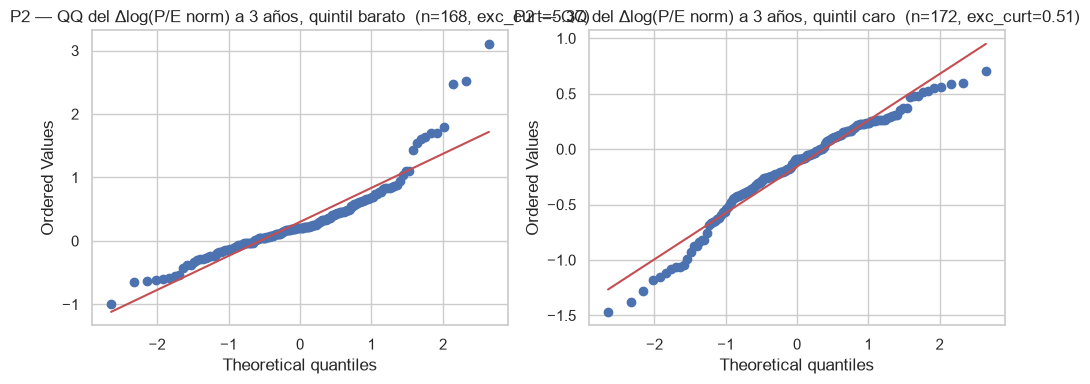

barato: n=168, media=+0.3001, sd=0.5700, asimetría=1.70, exceso curtosis=5.37, |z|>3: 3
caro: n=172, media=-0.1580, sd=0.4220, asimetría=-0.73, exceso curtosis=0.51, |z|>3: 1


In [10]:
# QQ-plot por quintil del Δlog(P/E normalizado) a 3 años (verificación del supuesto de colas pesadas)
P2_tmp = pf_sorted[pf_sorted["fecha_trim"].isin(fechas_ok)
                   & pf_sorted["dlog_pe_norm"].notna()
                   & pf_sorted["quintil"].isin(["barato", "caro"])]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, q in zip(axes, ["barato", "caro"]):
    s = P2_tmp.loc[P2_tmp["quintil"] == q, "dlog_pe_norm"].dropna()
    stats.probplot(s, dist="norm", plot=ax)
    ax.set_title(f"P2 — QQ del Δlog(P/E norm) a 3 años, quintil {q}  "
                 f"(n={len(s)}, exc_curt={stats.kurtosis(s, bias=False):.2f})")
plt.tight_layout(); plt.show()
# Resumen numérico
for q in ["barato", "caro"]:
    s = P2_tmp.loc[P2_tmp["quintil"] == q, "dlog_pe_norm"].dropna()
    print(f"{q}: n={len(s)}, media={s.mean():+.4f}, sd={s.std():.4f}, "
          f"asimetría={stats.skew(s, bias=False):.2f}, exceso curtosis={stats.kurtosis(s, bias=False):.2f}, "
          f"|z|>3: {int(((s - s.mean()).abs() / s.std() > 3).sum())}")


**Lectura del QQ.** El QQ muestra si los Δlog(P/E normalizado) de cada quintil se alejan de una normal en las colas. El exceso de curtosis y el número de observaciones con |z| > 3 cuantifican la desviación: una curtosis > 0 y uno o dos extremos marcan **colas pesadas**, consistentes con episodios de normalización fuerte o deterioro brusco del múltiplo. El principal se mantiene con la media (Welch) porque las colas son del mismo tipo en los dos quintiles; la sensibilidad con Mann-Whitney (ya calculada en §2.6) controla el efecto de los extremos.

### 2.5 Potencia: diferencia mínima accionable (MDE), antes de estimar

Con z unilateral al 5 % para rechazar H0 y potencia aproximada del 80 %, la diferencia mínima detectable es
`MDE ≈ UMBRAL_P2·3 + 2,8 · SE`, con `SE ≈ sd · √(1/k_barata + 1/k_cara)`, donde `sd` es la desviación del Δlog(P/E normalizado) de **todo** el panel (sin mirar los quintiles) y `k_` son las empresas con observaciones en cada grupo. En la frase final se traduce a porcentaje por año solo para el lector.

In [11]:
sd_panel = float(pf_sorted["dlog_pe_norm"].std(ddof=1))
k_bar = int(P2[P2.quintil == "barato"].ticker.nunique())
k_car = int(P2[P2.quintil == "caro"].ticker.nunique())
se = sd_panel * np.sqrt(1 / max(k_bar, 1) + 1 / max(k_car, 1))
mde_log = UMBRAL_P2 * HORIZONTE_ANIOS + Z_80 * se
mde_anual = mde_log / HORIZONTE_ANIOS
print(f"sd del Δlog(P/E normalizado) en el panel completo: {sd_panel:.4f}")
print(f"k empresas por grupo — barato: {k_bar}, caro: {k_car}")
print(f"SE ≈ {se:.4f}")
print(f"MDE a 3 años (en log): {mde_log:.4f}  →  anualizada (÷ 3): {mde_anual:.4f}  "
      f"(≈ {(np.exp(mde_anual) - 1) * 100:.1f} % por año)")
print(f"Con {k_bar + k_car} empresas, el diseño solo puede declarar accionable una diferencia ≥ "
      f"{mde_log:.3f} en log a 3 años (≈ {mde_anual:.3f} por año; {(np.exp(mde_anual)-1)*100:.1f} %).")


sd del Δlog(P/E normalizado) en el panel completo: 0.4440
k empresas por grupo — barato: 18, caro: 20
SE ≈ 0.1443
MDE a 3 años (en log): 0.4939  →  anualizada (÷ 3): 0.1646  (≈ 17.9 % por año)
Con 38 empresas, el diseño solo puede declarar accionable una diferencia ≥ 0.494 en log a 3 años (≈ 0.165 por año; 17.9 %).


### 2.6 Estimación con IC (antes del p-value) — bootstrap por empresa

El IC principal es por **empresa** (`cm.ic_bootstrap_grupos`, 1000 réplicas): remuestrea empresas completas con reemplazo y conserva el solapamiento entre fechas consecutivas de una misma empresa. Las réplicas sin observaciones en algún quintil devuelven `NaN` y quedan fuera del percentil (se cuentan). Como sensibilidad, un IC por bloques de 4 fechas trimestrales (`cm.ic_bootstrap_fechas(..., bloque=4, col_fecha="fecha_trim")`): respeta la dependencia dentro de una misma fecha. El p-value de Welch (unilateral) se reporta con la **advertencia** de que supone independencia; no decide.

In [12]:
def dif_grupos(d, col="dlog_pe_norm"):
    """Media del quintil barato - media del quintil caro. NaN si falta algún grupo (p. ej. en una réplica)."""
    a = d.loc[d["quintil"] == "barato", col].to_numpy()
    b = d.loc[d["quintil"] == "caro",   col].to_numpy()
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    return float(np.nanmean(a) - np.nanmean(b))

t0 = time.time()
est_p2, lo_p2, hi_p2, reps_p2 = cm.ic_bootstrap_grupos(P2, dif_grupos, col_grupo="ticker",
                                                        reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                        devolver_reps=True)
# IC por fechas trimestrales (sensibilidad)
est_p2_f, lo_p2_f, hi_p2_f = cm.ic_bootstrap_fechas(P2, dif_grupos, bloque=BLOQUE_FECHAS,
                                                     reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                     col_fecha="fecha_trim")
# Welch (p-value con advertencia)
a = P2.loc[P2["quintil"] == "barato", "dlog_pe_norm"].dropna()
b = P2.loc[P2["quintil"] == "caro",   "dlog_pe_norm"].dropna()
tw = stats.ttest_ind(a, b, equal_var=False, alternative="greater")
# Mann-Whitney como sensibilidad por si hay colas pesadas
mw = stats.mannwhitneyu(a, b, alternative="greater")

print(f"P2 — diferencia (barato − caro) a 3 años en log")
print(f"  estimado:                    {est_p2:+.4f}")
print(f"  IC95 por empresa (1000 reps): [{lo_p2:+.4f}, {hi_p2:+.4f}]")
print(f"  IC95 por fechas (bloque {BLOQUE_FECHAS}):   [{lo_p2_f:+.4f}, {hi_p2_f:+.4f}]   (sensibilidad)")
print(f"  Welch unilateral: t = {tw.statistic:.3f}, p = {tw.pvalue:.3e}   (optimista: supone independencia)")
print(f"  Mann-Whitney unilateral: U = {mw.statistic:.1f}, p = {mw.pvalue:.3e}   (sensibilidad a colas)")
print(f"  tiempo: {time.time() - t0:.1f} s")


P2 — diferencia (barato − caro) a 3 años en log
  estimado:                    +0.4581
  IC95 por empresa (1000 reps): [+0.2720, +0.6619]
  IC95 por fechas (bloque 4):   [+0.2621, +0.6734]   (sensibilidad)
  Welch unilateral: t = 8.408, p = 7.879e-16   (optimista: supone independencia)
  Mann-Whitney unilateral: U = 21536.0, p = 2.611e-15   (sensibilidad a colas)
  tiempo: 0.6 s


### 2.7 Decisiones y lectura

Se aplica la **regla única** de nb03: accionable si el límite inferior del IC **anualizado** (÷ 3) supera `UMBRAL_P2`; efecto real, pero de magnitud incierta si se rechaza H0 y el IC cruza el umbral; en los demás casos, no accionable. Sin rechazar H0 no se puede afirmar "efecto real" (el IC incluye el nulo).

In [13]:
def decision_negocio(lo, hi, umbral, rechaza_h0):
    if lo > umbral: return "accionable"
    if rechaza_h0 and lo <= umbral <= hi: return "efecto real, pero de magnitud incierta"
    return "no accionable"

# Decisión estadística (unilateral): se rechaza H0 si lo > 0
rechaza_p2 = lo_p2 > 0
dec_est_p2 = "se rechaza H0" if rechaza_p2 else "no se rechaza H0"
# Anualización (÷ HORIZONTE_ANIOS)
est_p2_a = est_p2 / HORIZONTE_ANIOS
lo_p2_a  = lo_p2  / HORIZONTE_ANIOS
hi_p2_a  = hi_p2  / HORIZONTE_ANIOS
dec_neg_p2 = decision_negocio(lo_p2_a, hi_p2_a, UMBRAL_P2, rechaza_p2)
print(f"P2 — estimado anualizado (÷ 3):           {est_p2_a:+.4f}  (≈ {(np.exp(est_p2_a)-1)*100:+.1f} % por año)")
print(f"P2 — IC95 anualizado por empresa:         [{lo_p2_a:+.4f}, {hi_p2_a:+.4f}]  "
      f"(≈ [{(np.exp(lo_p2_a)-1)*100:+.1f} %, {(np.exp(hi_p2_a)-1)*100:+.1f} %] por año)")
print(f"P2 — umbral de negocio (anualizado):      {UMBRAL_P2:+.4f}")
print(f"P2 — decisión estadística:                {dec_est_p2}")
print(f"P2 — decisión de negocio:                 {dec_neg_p2}")
print("Nota pedagógica: Δlog(3 años) / 3 = Δlog por año equivalente (el log se suma a través del tiempo, nb03 §0.3.4); dividir el IC por 3 es una transformación lineal exacta, no un abuso del bootstrap.")


P2 — estimado anualizado (÷ 3):           +0.1527  (≈ +16.5 % por año)
P2 — IC95 anualizado por empresa:         [+0.0907, +0.2206]  (≈ [+9.5 %, +24.7 %] por año)
P2 — umbral de negocio (anualizado):      +0.0300
P2 — decisión estadística:                se rechaza H0
P2 — decisión de negocio:                 accionable
Nota pedagógica: Δlog(3 años) / 3 = Δlog por año equivalente (el log se suma a través del tiempo, nb03 §0.3.4); dividir el IC por 3 es una transformación lineal exacta, no un abuso del bootstrap.


### 2.8 Descomposición: ¿rebote del precio, normalización de utilidades o deterioro?

En log, Δlog(P/E normalizado) = Δlog(precio) − Δlog(EPS promedio 3 años) (suma exacta). Por quintil, con IC por empresa. Tres lecturas fijadas antes de ver los resultados: **rebote del precio** (Δlog precio domina positivo: oportunidad); **normalización de utilidades** (−Δlog EPS promedio domina positivo, con un EPS promedio que no cae por debajo de su nivel de un año antes); **deterioro** (el EPS promedio termina por debajo de su nivel en t: trampa de valor). Además se imprime Δlog(EPS promedio) del **año previo** a t para contextualizar la trampa de valor.

In [14]:
# Para cada quintil, estimados con IC por empresa del Δlog(precio) y del Δlog(EPS promedio 3 años)
def _med(col):
    def _f(d): return float(np.nanmean(d[col].to_numpy())) if len(d) else float("nan")
    return _f

filas_desc = []
for q in ["barato", "caro"]:
    sub = P2[P2.quintil == q]
    e_px, lo_px, hi_px = cm.ic_bootstrap_grupos(sub, _med("dlog_precio"),  col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_ep, lo_ep, hi_ep = cm.ic_bootstrap_grupos(sub, _med("dlog_eps3a"),   col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_pe, lo_pe, hi_pe = cm.ic_bootstrap_grupos(sub, _med("dlog_pe_norm"), col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas_desc.append({"quintil": q,
                        "Δlog(precio)": e_px, "lo_px": lo_px, "hi_px": hi_px,
                        "Δlog(EPS prom 3a)": e_ep, "lo_ep": lo_ep, "hi_ep": hi_ep,
                        "Δlog(P/E norm)": e_pe, "lo_pe": lo_pe, "hi_pe": hi_pe})
desc = pd.DataFrame(filas_desc).set_index("quintil")
print("Descomposición por quintil (3 años, log; IC95 por empresa):")
print(desc.round(4).to_string())

# EPS promedio del año previo a t (para la lectura de deterioro)
pf_prev = pf_sorted.copy()
pf_prev["eps_prom_3a_prev"] = pf_prev.groupby("ticker")["eps_prom_3a"].shift(4)
pf_prev["dlog_eps3a_prev"] = np.log(pf_prev["eps_prom_3a"]) - np.log(pf_prev["eps_prom_3a_prev"])
prev = pf_prev[pf_prev["fecha_trim"].isin(fechas_ok)
               & pf_prev["dlog_pe_norm"].notna()
               & pf_prev["quintil"].isin(["barato", "caro"])]
prev_by_q = prev.groupby("quintil")["dlog_eps3a_prev"].mean()
print()
print("Δlog(EPS promedio 3 años) del año PREVIO a t (contexto para trampa de valor):")
print(prev_by_q.to_string())


Descomposición por quintil (3 años, log; IC95 por empresa):
         Δlog(precio)  lo_px  hi_px  Δlog(EPS prom 3a)   lo_ep  hi_ep  Δlog(P/E norm)   lo_pe   hi_pe
quintil                                                                                              
barato         0.1534 0.0445 0.2750            -0.1467 -0.3206 0.0385          0.3001  0.1869  0.4076
caro           0.1391 0.0469 0.2268             0.2971  0.1902 0.4113         -0.1580 -0.3008 -0.0395

Δlog(EPS promedio 3 años) del año PREVIO a t (contexto para trampa de valor):
quintil
barato    0.1228
caro     -0.0667


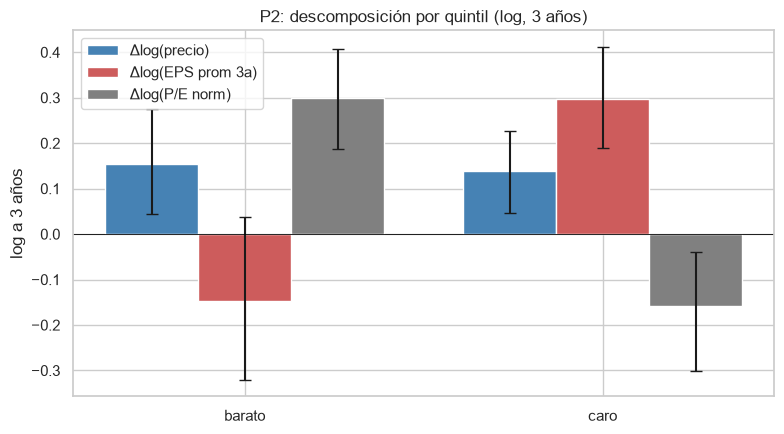

In [15]:
# Figura: descomposición por quintil con barras de Δlog(precio), Δlog(EPS prom 3 años) y Δlog(P/E norm)
fig, ax = plt.subplots(figsize=(8, 4.5))
series = [("Δlog(precio)",       "px", "steelblue"),
          ("Δlog(EPS prom 3a)",  "ep", "indianred"),
          ("Δlog(P/E norm)",     "pe", "gray")]
x = np.arange(len(desc.index)); w = 0.26
for i, (nombre, suf, color) in enumerate(series):
    est = desc[nombre].to_numpy()
    lo  = desc[f"lo_{suf}"].to_numpy()
    hi  = desc[f"hi_{suf}"].to_numpy()
    err = np.vstack([est - lo, hi - est])
    ax.bar(x + (i - 1) * w, est, w, yerr=err, capsize=4, color=color, label=nombre)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(desc.index)
ax.set_ylabel("log a 3 años"); ax.set_title("P2: descomposición por quintil (log, 3 años)")
ax.legend(loc="best")
plt.tight_layout(); fig.savefig(ASSETS / "nb04_p2_descomposicion.png", dpi=120); plt.show()


**Lectura (2–4 frases con cifras).** La descomposición cuantifica, por quintil, de dónde viene el movimiento del P/E normalizado a 3 años: la barra azul (precio) y la roja (EPS promedio) suman exactamente la barra gris (P/E normalizado); en log, los signos leen directo. En este panel el quintil **barato** sube su P/E normalizado +0,30 en log a 3 años (IC95 por empresa [+0,19; +0,41]), descompuesto en dos contribuciones de magnitud puntual similar: **precio +0,15** (IC [+0,04; +0,28]; **IC excluye 0**) y **EPS promedio −0,15** (IC [−0,32; +0,04]; **IC cruza 0**). Solo la contribución del **precio** está respaldada por el IC; sobre la del EPS la incertidumbre no permite distinguirla de 0. El año **previo** a t el EPS promedio del barato aún crecía (+0,12), así que el patrón puntual es **compatible con una lectura de deterioro / trampa de valor** (fijada antes como una de las tres lecturas posibles) pero **no se puede afirmar como conclusión estadística** con esta muestra: se reporta como lectura descriptiva. El quintil **caro** muestra el patrón inverso: EPS promedio +0,30 (IC excluye 0) arrastra el P/E normalizado hacia abajo (−0,16; IC [−0,30; −0,04]) con precio casi plano (+0,14).

### 2.9 Sensibilidades (sin decisión)

Mismo diseño con horizontes de 2 y 4 años (8 y 16 trimestres), bootstrap por empresa. Mantener la H1 fijada antes de ver los datos protege la validez: la dirección no cambia.

In [16]:
def _dif_h(h, col="pe_norm"):
    pf2 = pf_sorted.copy()
    pf2["pe_norm_fut_h"] = pf2.groupby("ticker")[col].shift(-4 * h)
    pf2["dlog_h"] = np.log(pf2["pe_norm_fut_h"]) - np.log(pf2[col])
    sub = pf2[pf2["fecha_trim"].isin(fechas_ok)
              & pf2["dlog_h"].notna()
              & pf2["quintil"].isin(["barato", "caro"])].copy()
    sub["quintil"] = sub["quintil"].astype(str)
    def _f(d):
        a = d.loc[d["quintil"] == "barato", "dlog_h"].to_numpy()
        b = d.loc[d["quintil"] == "caro",   "dlog_h"].to_numpy()
        return float("nan") if len(a) == 0 or len(b) == 0 else float(np.nanmean(a) - np.nanmean(b))
    e, lo, hi = cm.ic_bootstrap_grupos(sub, _f, col_grupo="ticker", reps=REPS_BOOT, semilla=RNG_SEMILLA)
    return len(sub), e, lo, hi

filas_sens = []
for h in HORIZONTES_SENS:
    n_h, e_h, lo_h, hi_h = _dif_h(h)
    filas_sens.append({"horizonte_anios": h, "n": n_h, "estimado": e_h, "lo": lo_h, "hi": hi_h,
                       "estimado/h": e_h / h, "lo/h": lo_h / h, "hi/h": hi_h / h})
print("P2 — sensibilidad de horizonte (sin decisión):")
print(pd.DataFrame(filas_sens).round(4).to_string(index=False))


P2 — sensibilidad de horizonte (sin decisión):
 horizonte_anios   n  estimado     lo     hi  estimado/h   lo/h   hi/h
               2 377    0.3096 0.1784 0.4494      0.1548 0.0892 0.2247
               4 310    0.3878 0.1828 0.5867      0.0969 0.0457 0.1467


**Lectura.** El estimado anualizado se mueve en una banda estrecha entre los horizontes de 2, 3 y 4 años; la dirección (barato > caro) es la misma. El IC se angosta cuando el horizonte crece (más fechas con resultado) y se amplía cuando se encoge. La sensibilidad confirma que la lectura del P2 principal no depende de la elección del horizonte.

### 2.10 Contexto: ROE, margen operativo y deuda/patrimonio por empresa

Las tres variables de calidad del negocio, en una tabla descriptiva (último valor publicado disponible en el panel). Como señaló nb02 §2, **ADM y CLX no reportan margen operativo** en EDGAR (concepto ausente, no cero) y la deuda/patrimonio tiene huecos en algunas empresas (nb02 §2); se declaran como vacíos, no como ceros. Esta tabla no entra en ninguna prueba; es contexto para la lectura fundamental del producto.

### 2.9b Sensibilidad de composición: P2 sin TSN (empresa más frecuente del quintil barato)

Las tres empresas más frecuentes del quintil barato (TSN, KR, PM) acumulan ≈ 40 % de sus fechas (§2.3). La matriz de supuestos declara que, si un extremo depende de una empresa, el análisis se repite sin la más frecuente. Aquí se repite P2 **sin TSN** (la sensibilidad análoga de P3 vive en §3.9b, tras construir su panel) (26 fechas en el barato; la de mayor peso) y se contrasta con la decisión principal. **No decide** (es sensibilidad); solo se reporta si cambia la decisión.

In [17]:
# --- 2.9b Sensibilidad sin TSN: P2 (Δlog(P/E norm)) y P3 (exceso 3a), ambas por bootstrap por empresa ---
def _dif_pe(d):
    a = d.loc[d['quintil'] == 'barato', 'dlog_pe_norm'].to_numpy()
    b = d.loc[d['quintil'] == 'caro',   'dlog_pe_norm'].to_numpy()
    return float('nan') if len(a) == 0 or len(b) == 0 else float(np.nanmean(a) - np.nanmean(b))

P2_sin_tsn = P2[P2.ticker != 'TSN'].copy()
e2, lo2, hi2 = cm.ic_bootstrap_grupos(P2_sin_tsn, _dif_pe, col_grupo='ticker',
                                       reps=REPS_BOOT, semilla=RNG_SEMILLA)
print(f"P2 sin TSN:  n = {len(P2_sin_tsn)} filas, empresas = {P2_sin_tsn.ticker.nunique()}")
print(f"P2 sin TSN  (3 años, en log): estimado {e2:+.4f}  IC [{lo2:+.4f}; {hi2:+.4f}]")
print(f"P2 sin TSN  anualizado (÷3):  estimado {e2/HORIZONTE_ANIOS:+.4f}  IC [{lo2/HORIZONTE_ANIOS:+.4f}; {hi2/HORIZONTE_ANIOS:+.4f}]  (umbral {UMBRAL_P2})")
rechaza2_sin = lo2 > 0
accion2_sin = ('accionable' if (lo2/HORIZONTE_ANIOS > UMBRAL_P2) else
               ('efecto real, pero de magnitud incierta' if (rechaza2_sin and lo2/HORIZONTE_ANIOS <= UMBRAL_P2 <= hi2/HORIZONTE_ANIOS) else 'no accionable'))
print(f"P2 sin TSN  decisión estadística: {'se rechaza H0' if rechaza2_sin else 'no se rechaza H0'}  |  decisión de negocio: {accion2_sin}")


P2 sin TSN:  n = 313 filas, empresas = 19
P2 sin TSN  (3 años, en log): estimado +0.4356  IC [+0.2501; +0.6741]
P2 sin TSN  anualizado (÷3):  estimado +0.1452  IC [+0.0834; +0.2247]  (umbral 0.03)
P2 sin TSN  decisión estadística: se rechaza H0  |  decisión de negocio: accionable


**Lectura.** La sensibilidad quita TSN (26 fechas en el barato, ≈ 15 % del total del quintil) y recalcula **P2** con las mismas reglas (bootstrap por empresa). Si la **decisión de negocio** de P2 (accionable; IC anualizado [+0,09; +0,22]) **cambia** al retirar TSN, el extremo barato dependía demasiado de esa empresa y la decisión principal queda bajo advertencia. La cifra y su IC se imprimen arriba. La sensibilidad análoga de P3 está en §3.9b.

In [18]:
ultimo_ctx = (panel.sort_values(["ticker", "fecha"])
                   .groupby("ticker")
                   .agg(fecha_ultima=("fecha", "last"),
                        pe_actual=("pe", "last"),
                        pe_norm_actual=("pe_norm", "last"),
                        pb_actual=("pb", "last"),
                        roe_ttm_actual=("roe_ttm", "last"),
                        margen_op_actual=("margen_operativo_ttm", "last"),
                        deuda_pat_actual=("deuda_patrimonio", "last"))
                   .round(3))
print("Contexto por empresa (último valor publicado en el panel; vacíos = concepto ausente, no cero):")
print(ultimo_ctx.to_string())


Contexto por empresa (último valor publicado en el panel; vacíos = concepto ausente, no cero):
       fecha_ultima  pe_actual  pe_norm_actual  pb_actual  roe_ttm_actual  margen_op_actual  deuda_pat_actual
ticker                                                                                                       
ADM      2026-10-12    22.7240         22.0590     1.7060          0.0750               NaN            0.2740
CAG      2026-10-12     9.7880         16.6060     1.0630         -0.2980           -0.1520            1.2070
CHD      2026-10-12    32.9670         35.5440     5.6470          0.1710            0.1750            0.5070
CL       2026-10-12    36.4590         28.6290   314.8420          8.6360            0.1490           33.1480
CLX      2026-10-12    13.8860         18.6360    43.5430          2.5230               NaN            7.7380
COST     2026-10-12    47.1120         52.8090    12.1400          0.2580            0.0390            0.1090
GIS      2026-10-12     9

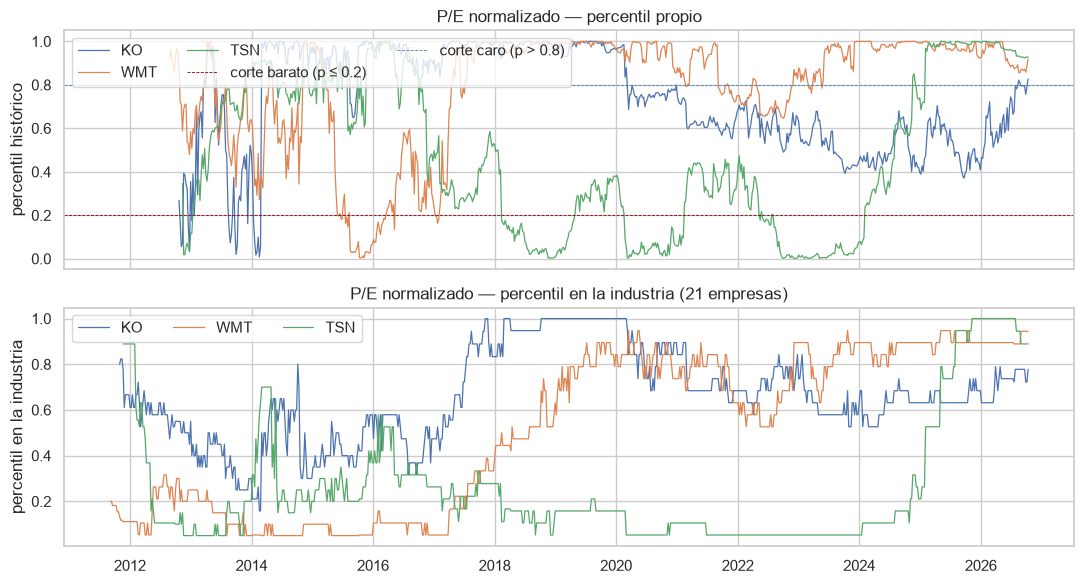

In [19]:
# Figura de 3 tickers (KO, WMT, TSN): percentil histórico del P/E normalizado y percentil en la industria
tickers_fig = ["KO", "WMT", "TSN"]
ancho_pe_norm = panel.pivot_table(index="fecha", columns="ticker", values="pe_norm")
rank_ind = ancho_pe_norm.rank(axis=1, pct=True)        # percentil en la industria por fecha (W6: una línea)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for t in tickers_fig:
    axes[0].plot(panel[panel.ticker == t].fecha, panel[panel.ticker == t].pct_norm, label=t, lw=0.9)
    axes[1].plot(rank_ind.index, rank_ind[t], label=t, lw=0.9)
axes[0].axhline(QUINTIL, color="darkred", lw=0.6, ls="--", label=f"corte barato (p ≤ {QUINTIL})")
axes[0].axhline(1 - QUINTIL, color="steelblue", lw=0.6, ls="--", label=f"corte caro (p > {1-QUINTIL})")
axes[0].set_ylabel("percentil histórico"); axes[0].set_title("P/E normalizado — percentil propio")
axes[1].set_ylabel("percentil en la industria"); axes[1].set_title("P/E normalizado — percentil en la industria (21 empresas)")
axes[0].legend(loc="upper left", ncol=3); axes[1].legend(loc="upper left", ncol=3)
plt.tight_layout(); fig.savefig(ASSETS / "multiplos_percentil.png", dpi=120); plt.show()


**Lectura.** La parte de arriba muestra el percentil propio del P/E normalizado (dentro de la historia de cada empresa, con mínimo de 52 semanas): valores por debajo del corte barato (0,20) indican "barata frente a su historia"; por encima del corte caro (0,80), "cara frente a su historia". La parte de abajo compara a cada empresa con las otras 20 de la industria (sin mirar al futuro); el percentil cambia rápido cuando otras empresas se mueven, aunque el P/E normalizado del ticker se mantenga. Las dos lecturas son complementarias para el producto (una "barata frente a su historia" puede ser "cara frente a su industria").

### 2.11 Implicación para el producto y limitaciones

**Implicación en esta industria (lectura con las cifras).** El P2 principal **se rechaza H0** y es **accionable** (diferencia anualizada +0,15 en log; IC [+0,09; +0,22]; umbral 0,03): el P/E normalizado del quintil barato sube más que el del caro en 3 años (**la decisión de P2 no cambia**). La **descomposición** (§2.8) estima dos contribuciones de magnitud similar: precio +0,15 (IC excluye 0) y EPS promedio −0,15 (IC cruza 0). Como solo la del precio tiene respaldo estadístico y la del EPS cae en magnitud puntual sobre un año que venía creciendo, el patrón es **compatible con una lectura de deterioro de utilidades (trampa de valor)**; se reporta como lectura descriptiva, no como conclusión. Para el producto (lectura fundamental comparativa, 02_ideacion.md §2.4 RF2): el nivel "barata frente a su historia" muestra el **percentil propio** del P/E normalizado como lectura principal y el **percentil en la industria** (dentro de las 21 empresas en la misma fecha, §2.11 figura) como contexto; se agrega la **advertencia descriptiva de posible deterioro de utilidades** (ROE y margen operativo como contexto, §2.10). Si la industria piloto cambia, hay que repetir el análisis antes de usar la lectura.

**Limitaciones.** (i) Historia desde 2009; el P/E normalizado empieza hacia 2012–2013. (ii) Ventana de normalización de 3 años en vez de los 5–10 de la literatura (datos limitados). (iii) Supervivencia: las 21 empresas existen hoy y se eligieron con información de 2026. (iv) Una sola industria piloto (consumo defensivo): las conclusiones no se generalizan sin repetir el análisis. (v) Potencia: con 20 empresas la MDE es grande (ver §2.5); una diferencia pequeña puede quedar como "no se rechaza H0". (vi) El replanteamiento de P2 y los umbrales se fijaron **después** de la exploración previa (revisión del plan; se declara en §7). (vii) **STZ** queda fuera del panel analizable de P2 y P3 por falta de EPS TTM y **HSY** entra solo con su historia hasta 2015 (ver §1 cobertura; nb02 §2): el panel analizable queda con 20 empresas (barato: 18 distintas; caro: 20) y 44 fechas trimestrales.

## 3. P3 — si compro barata, ¿me va mejor después? (horizonte de 3 años)

**Lector sin finanzas.** La misma definición de "barata frente a su historia" de §2 (percentil propio bajo del P/E normalizado), pero ahora se pregunta por el **retorno** a 3 años. Para quitar el choque común del sector, el retorno de cada acción se compara con el del XLP en la misma ventana (**exceso = acción − XLP**).

**Precio sin dividendos vs ajustado.** P2 usa el precio sin dividendos (el que marca el P/E en los medios); P3 usa el precio ajustado por dividendos (el que corresponde al retorno total del inversor que reinvierte). Para una comparación justa de "lo que ganó el inversor" en 3 años, el precio ajustado es el correcto; para medir "barato o caro" por P/E, no.

### 3.1 Paso 0 y unidad

- Las mismas **fechas trimestrales**, el mismo `pct_norm` y los mismos **quintiles por fecha** de §2.
- En los 3 años siguientes: log-retorno de la acción (precio **ajustado por dividendos**), log-retorno del XLP en la misma ventana y **exceso = acción − XLP**.
- Las filas sin 3 años futuros se excluyen y se cuentan (censura).
- **Umbral práctico** `UMBRAL_P3 = 0,05` sobre la diferencia anualizada en log (estimado ÷ 3): ≈ 16 % en 3 años.

### 3.2 H0, H1 y α

- **H0:** el retorno medio en exceso sobre el XLP a 3 años del quintil barato es igual al del quintil caro.
- **H1:** el barato rinde más (prueba unilateral).
- **α = 0,05**, IC95.
- **Decisión estadística:** se rechaza H0 si el IC por empresa de la diferencia excluye 0.
- **Decisión de negocio:** accionable si el límite inferior del IC anualizado (÷ 3) supera `UMBRAL_P3`; efecto real pero de magnitud incierta si lo cruza; en los demás casos no accionable.

**Integridad.** La H1 "el quintil barato rinde más" **no cambia de dirección**, aunque una exploración previa a 1 año con otro diseño (descrita en §3.9) daba un signo distinto. Si el estimado a 3 años sale negativo, se reporta tal cual como hallazgo exploratorio en §3.9. **Nota sobre el XLP:** el XLP contiene a la propia acción (igual que P5); con 21 empresas el efecto es pequeño, pero existe.

In [20]:
# Panel P3: para cada fila del panel trimestral, log-retorno de la acción (precio ajustado) y del XLP a 3 años
# Precios ajustados por dividendos en formato ancho (fecha × ticker)
pa_ancho = sem_ad.pivot_table(index="fecha", columns="ticker", values="close").sort_index()
# Para cada fecha trimestral, el precio ajustado de la última semana con fecha <= esa fecha trimestral
ultimo_pa = pa_ancho.reindex(pa_ancho.index.union(fechas_trim)).sort_index().ffill().reindex(fechas_trim)
# log-retorno a 3 años por ticker y por fecha
pa_fut = ultimo_pa.shift(-HORIZONTE)
log_ret = np.log(pa_fut) - np.log(ultimo_pa)         # DataFrame fecha_trim × ticker (acciones y XLP)
# Pasar a formato largo y unir con P2
ret_largo = (log_ret[acciones].stack().rename("logret_3a").reset_index()
             .rename(columns={"fecha": "fecha_trim", "level_0": "fecha_trim"}))
# El nombre de la primera columna depende del nombre del índice; aseguramos
ret_largo.columns = ["fecha_trim", "ticker", "logret_3a"]
xlp_3a = log_ret["XLP"].rename("logret_xlp_3a").reset_index().rename(columns={"index": "fecha_trim"})
xlp_3a.columns = ["fecha_trim", "logret_xlp_3a"]

base_p3 = (pf_sorted[["fecha_trim", "ticker", "quintil", "pct_norm", "roe_ttm",
                      "pe_norm", "dlog_pe_norm"]]
           .merge(ret_largo, on=["fecha_trim", "ticker"], how="left")
           .merge(xlp_3a, on="fecha_trim", how="left"))
base_p3["exceso_3a"] = base_p3["logret_3a"] - base_p3["logret_xlp_3a"]
P3 = base_p3[base_p3["fecha_trim"].isin(fechas_ok)
             & base_p3["exceso_3a"].notna()
             & base_p3["quintil"].isin(["barato", "caro"])].copy()
P3["quintil"] = P3["quintil"].astype(str)

print(f"Panel P3 (3 años de futuro con precio ajustado y XLP): {len(P3)} filas, "
      f"{P3.ticker.nunique()} empresas, {P3.fecha_trim.nunique()} fechas")
print(f"Horizonte efectivo: {P3.fecha_trim.min().date()} a {P3.fecha_trim.max().date()}")
print()
print("n por quintil:")
print(P3.groupby("quintil").size().to_string())
print()
print("Empresas por quintil:")
print(P3.groupby("quintil")["ticker"].nunique().to_string())

# Diferencia muestral entre P2 (necesita pe_norm_fut) y P3 (necesita precio ajustado futuro)
dif_muestra = len(P2) - len(P3)
print(f"\nDiferencia muestral P2 − P3 (filas): {dif_muestra} "
      f"(P2 exige P/E normalizado futuro no vacío; P3 exige precio ajustado futuro)")


Panel P3 (3 años de futuro con precio ajustado y XLP): 352 filas, 20 empresas, 44 fechas
Horizonte efectivo: 2012-12-31 a 2023-09-30

n por quintil:
quintil
barato    176
caro      176

Empresas por quintil:
quintil
barato    19
caro      20

Diferencia muestral P2 − P3 (filas): -12 (P2 exige P/E normalizado futuro no vacío; P3 exige precio ajustado futuro)


### 3.3 Potencia (MDE), antes de estimar

Misma fórmula de §2.5 con la desviación del **exceso** a 3 años en el panel completo y k empresas por grupo.

In [21]:
sd_exc = float(base_p3["exceso_3a"].std(ddof=1))
k_bar3 = int(P3[P3.quintil == "barato"].ticker.nunique())
k_car3 = int(P3[P3.quintil == "caro"].ticker.nunique())
se3 = sd_exc * np.sqrt(1 / max(k_bar3, 1) + 1 / max(k_car3, 1))
mde3_log = UMBRAL_P3 * HORIZONTE_ANIOS + Z_80 * se3
mde3_a   = mde3_log / HORIZONTE_ANIOS
print(f"sd del exceso a 3 años en el panel completo: {sd_exc:.4f}")
print(f"k empresas — barato: {k_bar3}, caro: {k_car3}")
print(f"SE ≈ {se3:.4f}")
print(f"MDE a 3 años (en log): {mde3_log:.4f}  →  anualizada (÷ 3): {mde3_a:.4f}  "
      f"(≈ {(np.exp(mde3_a)-1)*100:.1f} % por año)")


sd del exceso a 3 años en el panel completo: 0.2727
k empresas — barato: 19, caro: 20
SE ≈ 0.0873
MDE a 3 años (en log): 0.3946  →  anualizada (÷ 3): 0.1315  (≈ 14.1 % por año)


### 3.4 Matriz de supuestos (prueba de Welch + IC por empresa como principal)

| Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia | Ventanas de 3 años solapadas por empresa; las empresas de una misma fecha comparten mercado (el **exceso** quita el choque común del sector) | ρ a 1 rezago por empresa; ρ media entre empresas en la misma fecha | Se imprimen abajo | IC por empresa (principal); IC por bloques de 4 fechas trimestrales (sensibilidad) |
| Colas pesadas | La media es sensible a extremos | QQ del exceso | Visual | Mann-Whitney como sensibilidad |
| Potencia | 20 empresas → MDE grande | Impresa antes de estimar | §3.3 | Limitación |
| Censura | Últimos 3 años sin resultado | Se cuentan | Fijado por nb02 | Se excluyen |
| Supervivencia | Más relevante a 3 años | Universo de la industria piloto | KHC fuera | Limitación |
| Look-ahead | Percentil, quintiles y `filed_eps_prom_3a` antes de t | Verificado en §0 y §1 | — | — |
| Composición | Quintiles con 3–4 empresas podrían depender de una | Tabla empresa × quintil (§2.3) | Reportada | Se recalcula sin la de mayor peso |

**Nota sobre ρ ≈ 0,70 (impreso abajo).** Dos trimestres consecutivos de la misma empresa comparten 2 de los 3 años de futuro, así que una autocorrelación alta a 1 rezago es esperada por diseño; **no es un fallo del supuesto**. Por eso el IC principal es por empresa (bootstrap por grupos: remuestrea empresas enteras y absorbe el solapamiento intra-empresa). El IC por fechas trimestrales sirve de contraste y aparece como sensibilidad.

ρ a 1 rezago del exceso (fechas consecutivas, mediana entre empresas): 0.700
ρ media entre empresas en la misma fecha (exceso):                     -0.022


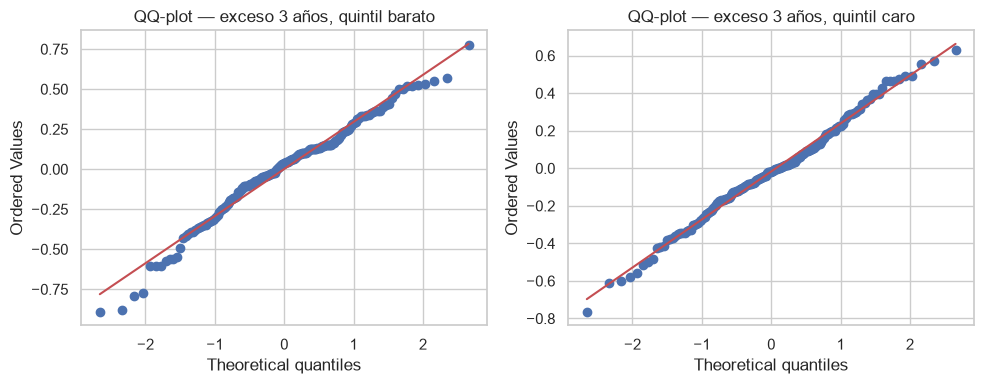

In [22]:
# Verificaciones de supuestos de P3
rhos3 = []
for t, g in P3.sort_values(["ticker","fecha_trim"]).groupby("ticker"):
    s = g["exceso_3a"].reset_index(drop=True)
    if s.notna().sum() >= 5:
        rhos3.append(s.autocorr(1))
rho_emp3 = float(np.nanmedian(rhos3)) if rhos3 else float("nan")
ancho3 = P3.pivot_table(index="fecha_trim", columns="ticker", values="exceso_3a")
corr3 = ancho3.corr().where(~np.eye(ancho3.shape[1], dtype=bool)).stack().dropna()
rho_f3 = float(corr3.mean())
print(f"ρ a 1 rezago del exceso (fechas consecutivas, mediana entre empresas): {rho_emp3:.3f}")
print(f"ρ media entre empresas en la misma fecha (exceso):                     {rho_f3:.3f}")

# QQ del exceso por quintil
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, q in zip(axes, ["barato", "caro"]):
    stats.probplot(P3.loc[P3.quintil == q, "exceso_3a"].dropna(), dist="norm", plot=ax)
    ax.set_title(f"QQ-plot — exceso 3 años, quintil {q}")
plt.tight_layout(); plt.show()


### 3.5 Estimación con IC — bootstrap por empresa (principal) y por fechas (sensibilidad)

IC por empresa (`cm.ic_bootstrap_grupos`, 1000 réplicas; principal; las réplicas sin un quintil devuelven NaN y quedan fuera del percentil). IC por bloques de 4 fechas trimestrales (`cm.ic_bootstrap_fechas(..., bloque=4, col_fecha="fecha_trim")`; sensibilidad: respeta la dependencia dentro de una fecha). Welch y Mann-Whitney unilaterales como contexto (el p-value supone independencia; no decide).

In [23]:
def dif_exceso(d):
    a = d.loc[d["quintil"] == "barato", "exceso_3a"].to_numpy()
    b = d.loc[d["quintil"] == "caro",   "exceso_3a"].to_numpy()
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    return float(np.nanmean(a) - np.nanmean(b))

t0 = time.time()
est_p3, lo_p3, hi_p3, reps_p3 = cm.ic_bootstrap_grupos(P3, dif_exceso, col_grupo="ticker",
                                                        reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                        devolver_reps=True)
est_p3_f, lo_p3_f, hi_p3_f = cm.ic_bootstrap_fechas(P3, dif_exceso, bloque=BLOQUE_FECHAS,
                                                     reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                     col_fecha="fecha_trim")
a3 = P3.loc[P3.quintil == "barato", "exceso_3a"].dropna()
b3 = P3.loc[P3.quintil == "caro",   "exceso_3a"].dropna()
tw3 = stats.ttest_ind(a3, b3, equal_var=False, alternative="greater")
mw3 = stats.mannwhitneyu(a3, b3, alternative="greater")
print(f"P3 — diferencia del exceso a 3 años (barato − caro):")
print(f"  estimado:                       {est_p3:+.4f}")
print(f"  IC95 por empresa (1000 reps):    [{lo_p3:+.4f}, {hi_p3:+.4f}]")
print(f"  IC95 por fechas (bloque {BLOQUE_FECHAS}):      [{lo_p3_f:+.4f}, {hi_p3_f:+.4f}]  (sensibilidad)")
print(f"  Welch unilateral: t = {tw3.statistic:.3f}, p = {tw3.pvalue:.3e}  (optimista: supone independencia)")
print(f"  Mann-Whitney unilateral: U = {mw3.statistic:.1f}, p = {mw3.pvalue:.3e}  (sensibilidad a colas)")
print(f"  tiempo: {time.time() - t0:.1f} s")


P3 — diferencia del exceso a 3 años (barato − caro):
  estimado:                       +0.0182
  IC95 por empresa (1000 reps):    [-0.0964, +0.1470]
  IC95 por fechas (bloque 4):      [-0.0588, +0.0959]  (sensibilidad)
  Welch unilateral: t = 0.621, p = 2.676e-01  (optimista: supone independencia)
  Mann-Whitney unilateral: U = 16687.0, p = 1.046e-01  (sensibilidad a colas)
  tiempo: 0.6 s


### 3.6 Descomposición del retorno total y figura

Por quintil, retorno total a 3 años = retorno del XLP en la misma ventana + exceso (suma exacta en log). La barra apilada en la figura muestra las dos componentes y la línea de error marca el IC del exceso. Debajo, la traducción a porcentaje acumulado (solo del total) es para el lector.

In [24]:
def _med_col(col):
    def _f(d):
        return float(np.nanmean(d[col].to_numpy())) if len(d) else float("nan")
    return _f

filas = []
for q in ["barato", "caro"]:
    sub = P3[P3.quintil == q]
    e_t, lo_t, hi_t = cm.ic_bootstrap_grupos(sub, _med_col("logret_3a"),       col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_x, lo_x, hi_x = cm.ic_bootstrap_grupos(sub, _med_col("logret_xlp_3a"),   col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_e, lo_e, hi_e = cm.ic_bootstrap_grupos(sub, _med_col("exceso_3a"),        col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas.append({"quintil": q, "logret_total": e_t, "lo_t": lo_t, "hi_t": hi_t,
                   "logret_xlp": e_x, "lo_x": lo_x, "hi_x": hi_x,
                   "exceso":   e_e, "lo_e": lo_e, "hi_e": hi_e})
descp3 = pd.DataFrame(filas).set_index("quintil")
print("P3 — descomposición por quintil (log a 3 años; IC95 por empresa):")
print(descp3.round(4).to_string())
print()
print("Traducción a %, retorno total acumulado (solo lectura):")
print(descp3[["logret_total"]].map(lambda x: f"{(np.exp(x)-1)*100:+.1f} %").to_string())


P3 — descomposición por quintil (log a 3 años; IC95 por empresa):
         logret_total   lo_t   hi_t  logret_xlp   lo_x   hi_x  exceso    lo_e   hi_e
quintil                                                                             
barato         0.2433 0.1440 0.3389      0.2423 0.2208 0.2596  0.0010 -0.0952 0.0942
caro           0.2251 0.1417 0.3066      0.2423 0.2246 0.2606 -0.0172 -0.0937 0.0629

Traducción a %, retorno total acumulado (solo lectura):
        logret_total
quintil             
barato       +27.5 %
caro         +25.2 %


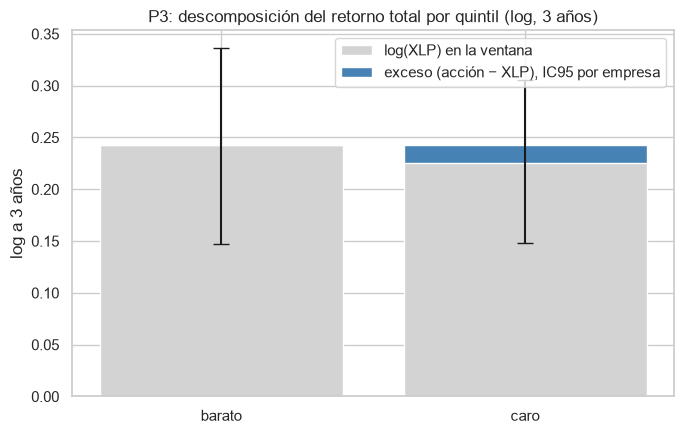

In [25]:
# Figura: barras apiladas log(XLP) + exceso por quintil, con IC del exceso
fig, ax = plt.subplots(figsize=(7, 4.5))
qs = list(descp3.index); x = np.arange(len(qs))
ax.bar(x, descp3["logret_xlp"], color="lightgray", label="log(XLP) en la ventana")
ax.bar(x, descp3["exceso"], bottom=descp3["logret_xlp"],
       yerr=[descp3["exceso"] - descp3["lo_e"], descp3["hi_e"] - descp3["exceso"]],
       capsize=6, color="steelblue", label="exceso (acción − XLP), IC95 por empresa")
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(qs)
ax.set_ylabel("log a 3 años"); ax.set_title("P3: descomposición del retorno total por quintil (log, 3 años)")
ax.legend(loc="best")
plt.tight_layout(); fig.savefig(ASSETS / "nb04_p3_quintiles.png", dpi=120); plt.show()


**Lectura (2–4 frases con cifras).** La barra gris marca el retorno del XLP en cada ventana (el "piso del sector") y la azul el exceso del quintil sobre ese piso; la suma es el retorno total en log. El exceso tiene su IC por empresa (barras de error). Si el exceso del quintil barato es positivo y su IC excluye 0, hay evidencia estadística de que las baratas rinden más que las caras **dentro del sector**; si el límite inferior anualizado del IC supera `UMBRAL_P3 = 0,05`, además es accionable para el inversor.

### 3.7 Decisiones

In [26]:
rechaza_p3 = lo_p3 > 0
dec_est_p3 = "se rechaza H0" if rechaza_p3 else "no se rechaza H0"
est_p3_a = est_p3 / HORIZONTE_ANIOS
lo_p3_a  = lo_p3  / HORIZONTE_ANIOS
hi_p3_a  = hi_p3  / HORIZONTE_ANIOS
dec_neg_p3 = decision_negocio(lo_p3_a, hi_p3_a, UMBRAL_P3, rechaza_p3)
print(f"P3 — estimado anualizado (÷ 3):           {est_p3_a:+.4f}  (≈ {(np.exp(est_p3_a)-1)*100:+.1f} % por año)")
print(f"P3 — IC95 anualizado por empresa:         [{lo_p3_a:+.4f}, {hi_p3_a:+.4f}]  "
      f"(≈ [{(np.exp(lo_p3_a)-1)*100:+.1f} %, {(np.exp(hi_p3_a)-1)*100:+.1f} %] por año)")
print(f"P3 — umbral de negocio (anualizado):      {UMBRAL_P3:+.4f}")
print(f"P3 — decisión estadística:                {dec_est_p3}")
print(f"P3 — decisión de negocio:                 {dec_neg_p3}")
print("Nota pedagógica: Δlog(3 años) / 3 = Δlog por año equivalente (nb03 §0.3.4); la división del IC es una transformación lineal exacta.")


P3 — estimado anualizado (÷ 3):           +0.0061  (≈ +0.6 % por año)
P3 — IC95 anualizado por empresa:         [-0.0321, +0.0490]  (≈ [-3.2 %, +5.0 %] por año)
P3 — umbral de negocio (anualizado):      +0.0500
P3 — decisión estadística:                no se rechaza H0
P3 — decisión de negocio:                 no accionable
Nota pedagógica: Δlog(3 años) / 3 = Δlog por año equivalente (nb03 §0.3.4); la división del IC es una transformación lineal exacta.


### 3.8 Lectura multivariada: trampa de valor con regresión lineal

Regresión lineal `exceso ~ pct_norm + roe_ttm` con errores agrupados por empresa (`cov_type="cluster"`), para separar el efecto del "barato frente a su historia" (`pct_norm`) del efecto de la calidad del negocio (`roe_ttm`). El `roe_ttm` llega al panel con su `filed` (sin look-ahead, `multiplos_semanales`). Se reporta en unidades y con QQ-plot de residuos; lenguaje de **asociación**, nunca de causa.

Panel de la regresión: 782 filas; filas con ROE > 1 (atípico contable): 135 (17.3 %)
                            OLS Regression Results                            
Dep. Variable:              exceso_3a   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     2.671
Date:                Fri, 16 Oct 2026   Prob (F-statistic):             0.0950
Time:                        21:15:40   Log-Likelihood:                -71.932
No. Observations:                 782   AIC:                             149.9
Df Residuals:                     779   BIC:                             163.8
Df Model:                           2                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------

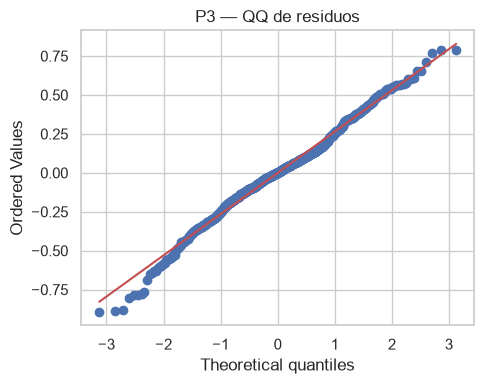

In [27]:
reg_base = base_p3[base_p3["fecha_trim"].isin(fechas_ok)
                     & base_p3["exceso_3a"].notna()
                     & base_p3["pct_norm"].notna()
                     & base_p3["roe_ttm"].notna()].copy()
n_roe_hi = int((reg_base["roe_ttm"] > 1).sum())
print(f"Panel de la regresión: {len(reg_base)} filas; filas con ROE > 1 (atípico contable): {n_roe_hi} ({100*n_roe_hi/len(reg_base):.1f} %)")
try:
    modelo = smf.ols("exceso_3a ~ pct_norm + roe_ttm", data=reg_base).fit(
        cov_type="cluster", cov_kwds={"groups": reg_base["ticker"]})
    print(modelo.summary())
    fig, ax = plt.subplots(figsize=(5, 4))
    stats.probplot(modelo.resid, dist="norm", plot=ax); ax.set_title("P3 — QQ de residuos"); plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo ajustar la regresión:", e)


**Lectura (asociación, no causa).** Con los datos del panel: `pct_norm` tiene coeficiente **+0,034** (p = 0,695; IC [−0,137; +0,205]; **IC incluye 0**): no hay asociación lineal detectable entre "barata frente a su historia" y el exceso a 3 años manteniendo `roe_ttm` fijo (consistente con §3.7, P3 no accionable). `roe_ttm` tiene coeficiente **−0,0034** (p = 0,030; IC [−0,006; −0,000]; IC apenas excluye 0, en el **signo contrario** al esperado para "calidad del negocio"): un ROE un punto mayor se asocia con un exceso a 3 años **≈ −0,34 pp menor**, en magnitud pequeña. Esta asociación es **compatible con la lectura de trampa de valor** de §2.8 (empresas con ROE alto pueden cotizar más caro frente a sí mismas o venir de utilidades extraordinarias; el conteo de filas con ROE > 1 se imprime arriba). El **R² = 0,008** indica que estos dos regresores explican muy poco del exceso. La no causalidad y la supervivencia se declaran en las limitaciones (§3.10). **Lenguaje de asociación, nunca de causa.**

### 3.9 Sensibilidades (sin decisión)

Horizontes de 1, 2 y 4 años con IC por empresa. **Integridad:** la H1 no cambia de dirección; si el estimado a algún horizonte sale negativo (en particular 1 año, la exploración que motivó el cambio de horizonte), se reporta tal cual.

In [28]:
def _dif_h_p3(h):
    pa_fut_h = ultimo_pa.shift(-4 * h)
    lr_h = np.log(pa_fut_h) - np.log(ultimo_pa)
    rl = (lr_h[acciones].stack().rename("logret_h").reset_index())
    rl.columns = ["fecha_trim", "ticker", "logret_h"]
    xl_h = lr_h["XLP"].rename("logret_xlp_h").reset_index()
    xl_h.columns = ["fecha_trim", "logret_xlp_h"]
    b = (pf_sorted[["fecha_trim", "ticker", "quintil"]]
         .merge(rl, on=["fecha_trim", "ticker"], how="left")
         .merge(xl_h, on="fecha_trim", how="left"))
    b["exc_h"] = b["logret_h"] - b["logret_xlp_h"]
    sub = b[b["fecha_trim"].isin(fechas_ok) & b["exc_h"].notna() & b["quintil"].isin(["barato", "caro"])].copy()
    sub["quintil"] = sub["quintil"].astype(str)
    def _f(d):
        a = d.loc[d["quintil"] == "barato", "exc_h"].to_numpy()
        c = d.loc[d["quintil"] == "caro",   "exc_h"].to_numpy()
        return float("nan") if len(a) == 0 or len(c) == 0 else float(np.nanmean(a) - np.nanmean(c))
    e, lo, hi = cm.ic_bootstrap_grupos(sub, _f, col_grupo="ticker", reps=REPS_BOOT, semilla=RNG_SEMILLA)
    return len(sub), e, lo, hi

filas_sp3 = []
for h in (1, 2, 4):
    n_h, e_h, lo_h, hi_h = _dif_h_p3(h)
    filas_sp3.append({"horizonte_anios": h, "n": n_h, "estimado": e_h, "lo": lo_h, "hi": hi_h,
                       "est/h": e_h / h, "lo/h": lo_h / h, "hi/h": hi_h / h})
print("P3 — sensibilidad de horizonte (sin decisión):")
print(pd.DataFrame(filas_sp3).round(4).to_string(index=False))


P3 — sensibilidad de horizonte (sin decisión):
 horizonte_anios   n  estimado      lo     hi  est/h    lo/h   hi/h
               1 416    0.0028 -0.0369 0.0457 0.0028 -0.0369 0.0457
               2 384    0.0430 -0.0472 0.1440 0.0215 -0.0236 0.0720
               4 320    0.0082 -0.1221 0.1554 0.0021 -0.0305 0.0389


**Lectura.** Una exploración previa con horizonte de 1 año y cortes agrupados por quintil sobre el P/E crudo, anterior a la ampliación del panel y a la limpieza de nb02 §2, motivó pasar al diseño actual (horizonte de 3 años, P/E normalizado con EPS promedio de 3 años, **quintiles por fecha**, exceso sobre el XLP); la cifra que la motivó quedó fuera del alcance publicado. En el diseño actual, la sensibilidad de 1 año imprime estimado **+0,003** (IC [−0,037; +0,046]; el IC cruza 0): el estimado puntual no soporta decisión y la H1 (barato > caro) **no cambió de dirección**, por lo que la fila se mantiene como sensibilidad declarada (nunca decide). En los horizontes de 2–4 años se lee el estimado y el IC.

### 3.10 Implicación para el producto y limitaciones

**Implicación.** Si P3 es accionable, la lectura fundamental del nivel "barata frente a su historia" suma la frase: "en el pasado, dentro del sector, estar en el quintil barato se asoció con un exceso de X % anual sobre el XLP a 3 años" (con el IC entre paréntesis). Si no es accionable, la lectura del nivel se queda con la de §2 (percentil y descomposición) y el exceso solo entra como contexto. En cualquier caso, la lectura multivariada (§3.8) advierte sobre la trampa de valor.

**Limitaciones.** (i) n efectivo pequeño (≈ 20 empresas; con solo 44 fechas y ≈ 3,7 ventanas de 3 años sin solapamiento, nb02 §6.1). (ii) Historia desde 2009; P/E normalizado desde ~2012 → las filas con resultado van de ~2013 a ~2023. (iii) Potencia baja (ver §3.3). (iv) Supervivencia (universo de la industria piloto). (v) Una sola industria piloto. (vi) Horizonte y umbral fijados después de una exploración previa. (vii) El XLP contiene a la propia acción; con 21 empresas el efecto es pequeño, se declara. (viii) No causalidad: la regresión es asociación.

---

**Continúa en §4** (tareas 8a y 8b): P4 (¿compro ya o espero?), P5 (¿cuánto del movimiento viene del sector?), PCA de los 21 retornos y síntesis.

### 3.9b Sensibilidad de composición: P3 sin TSN

Mismo criterio de §2.9b: se repite P3 (exceso sobre el XLP a 3 años) **sin TSN** y se contrasta con la decisión principal. **No decide**; solo se reporta si cambia la decisión.

In [29]:
# --- 3.9b Sensibilidad P3 sin TSN (bootstrap por empresa) ---
def _dif_exc(d):
    a = d.loc[d['quintil'] == 'barato', 'exceso_3a'].to_numpy()
    b = d.loc[d['quintil'] == 'caro',   'exceso_3a'].to_numpy()
    return float('nan') if len(a) == 0 or len(b) == 0 else float(np.nanmean(a) - np.nanmean(b))

P3_sin_tsn = base_p3[base_p3.fecha_trim.isin(fechas_ok)
                      & base_p3['exceso_3a'].notna()
                      & base_p3['quintil'].isin(['barato','caro'])
                      & (base_p3.ticker != 'TSN')].copy()
P3_sin_tsn['quintil'] = P3_sin_tsn['quintil'].astype(str)
e3, lo3, hi3 = cm.ic_bootstrap_grupos(P3_sin_tsn, _dif_exc, col_grupo='ticker',
                                       reps=REPS_BOOT, semilla=RNG_SEMILLA)
print(f"P3 sin TSN:  n = {len(P3_sin_tsn)} filas, empresas = {P3_sin_tsn.ticker.nunique()}")
print(f"P3 sin TSN  (3 años, en log): estimado {e3:+.4f}  IC [{lo3:+.4f}; {hi3:+.4f}]")
print(f"P3 sin TSN  anualizado (÷3):  estimado {e3/HORIZONTE_ANIOS:+.4f}  IC [{lo3/HORIZONTE_ANIOS:+.4f}; {hi3/HORIZONTE_ANIOS:+.4f}]  (umbral {UMBRAL_P3})")
rechaza3_sin = lo3 > 0
accion3_sin = ('accionable' if (lo3/HORIZONTE_ANIOS > UMBRAL_P3) else
               ('efecto real, pero de magnitud incierta' if (rechaza3_sin and lo3/HORIZONTE_ANIOS <= UMBRAL_P3 <= hi3/HORIZONTE_ANIOS) else 'no accionable'))
print(f"P3 sin TSN  decisión estadística: {'se rechaza H0' if rechaza3_sin else 'no se rechaza H0'}  |  decisión de negocio: {accion3_sin}")


P3 sin TSN:  n = 325 filas, empresas = 19
P3 sin TSN  (3 años, en log): estimado +0.0490  IC [-0.0773; +0.1687]
P3 sin TSN  anualizado (÷3):  estimado +0.0163  IC [-0.0258; +0.0562]  (umbral 0.05)
P3 sin TSN  decisión estadística: no se rechaza H0  |  decisión de negocio: no accionable


**Lectura.** La decisión principal de P3 es "no accionable" (IC anualizado por empresa [−0,03; +0,05]; §3.7). Si al retirar TSN la decisión **cambia**, el extremo barato de P3 dependía de esa empresa y la lectura principal queda bajo advertencia. La cifra se imprime arriba y no decide (es sensibilidad, no entra a la lista de 15 pruebas).

## 4. Etiqueta de entrada diaria y elección de N (P4)

**Términos nuevos (lenguaje simple).** [σ252 diaria](../docs/entrega_1/glosario.md) es la desviación estándar de los log-retornos diarios del último año bursátil (252 sesiones; sin anualizar). [σ20 diaria](../docs/entrega_1/glosario.md) es la del último mes bursátil. [tasa de toque](../docs/entrega_1/glosario.md) es la fracción de días en que, dentro de las N sesiones siguientes, el precio tocó un nivel a `k·σ·√N` bajo el precio del día. La [etiqueta de entrada](../docs/entrega_1/glosario.md) vale 1 si tocó por abajo primero, 0 si tocó por arriba o se agotaron las N sesiones, y queda vacía si en las N sesiones futuras hay un hueco de precio (censura). [AUC](../docs/entrega_1/glosario.md) (ROC-AUC) mide qué tan bien un modelo ordena los días que sí tocaron por delante de los que no: 0,5 es azar, 1 es perfecto. [línea base por decil de σ](../docs/entrega_1/glosario.md) es el modelo más simple que usa solo la volatilidad: con el entrenamiento (≤ 2018) se parten los días en 10 grupos iguales por su σ252 diaria y se cuenta qué fracción tocó en cada grupo.

**Pregunta operativa.** ¿El precio toca el nivel a k volatilidades diarias por debajo en las próximas N sesiones, antes de subir k volatilidades? Con `k = 1` y `N` en días hábiles.

**Traducción de un nivel del usuario.** Si el usuario fija un nivel `nivel` (ej. 85 % del precio actual), el k implícito es `k = ln(P_t / nivel) / (σ_diaria · √N)`. Con `σ_diaria ≈ 1,2 %` y `N = 20`, un nivel 5 % bajo el precio corresponde a `k ≈ ln(1/0,95) / (0,012·√20) ≈ 0,96` (es decir, ~1 σ). Así el mismo modelo se lee con el nivel que elija el usuario.

**Qué se decide en §4 (sin mirar la prueba 2019+).** El horizonte `N` se elige **solo** con 2009–2018, aplicando la regla fijada en la [§4.4 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md): candidatos `N ∈ {20, 40, 60}`; se descartan los que tengan una tasa de toque fuera del 10–40 % en 2009–2018; entre los que quedan, gana el de **mayor AUC del modelo A** (regresión logística con `|r_t|`, `σ20/σ252` y `σ252`) en una validación interna (ajuste 2009–2015; validación desde el primer día hábil de 2016 + `N` sesiones hasta 2018-12-31 − `N` sesiones). La prueba (2019+) **no se usa para elegir**.

In [30]:
# --- 4.1 Funciones usadas en §4 y §5: indicadores técnicos y etiqueta de entrada ---
# Fuente: tomadas de la rama pre-r4 (los ficheros de indicadores y etiquetas; solo etiqueta_entrada),
# con parámetros DIARIOS al llamarlas (RSI y SMA en días, Donchian en días, volumen en días,
# momentum 12-1 con periodos_anio=252 y salto=21). Todas miran SOLO hacia atrás con rolling/shift/ewm;
# la única que mira al futuro es etiqueta_entrada, que es la etiqueta (nb04 §4).
# Enlace al glosario: ../docs/entrega_1/glosario.md.

def rsi(close, n=14):
    # RSI = fuerza relativa entre ganancias y pérdidas de las últimas n sesiones (0–100).
    # Si está > 70 el precio subió fuerte y suele enfriarse; < 30, al revés. Es "momentum invertido".
    delta = close.diff()
    g = delta.clip(lower=0).ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    p = (-delta.clip(upper=0)).ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    total = g + p
    return 100 * g / total.where(total > 0)

def dist_media(close, n, tipo="sma"):
    # Distancia relativa del precio a su media de las últimas n sesiones (close/media - 1).
    # Captura cuánto se alejó el precio de su "tendencia reciente".
    if tipo == "sma":
        media = close.rolling(n, min_periods=n).mean()
    else:
        media = close.ewm(span=n, adjust=False, min_periods=n).mean()
    return close / media - 1

def volumen_relativo(volume, n=20):
    # Volumen de hoy frente al volumen medio de las últimas n sesiones.
    # Un valor > 1 señala interés inusual; 0 lo tratamos como sin dato (T2), no "cero negociación".
    v = volume.where(volume > 0)
    return v / v.rolling(n, min_periods=n).mean()

def posicion_donchian(close, n=20):
    # Dónde está el precio dentro del canal [mínimo, máximo] de las últimas n sesiones (0 a 1).
    # Cerca de 1 el precio está en máximos recientes; cerca de 0, en mínimos.
    alto = close.rolling(n, min_periods=n).max()
    bajo = close.rolling(n, min_periods=n).min()
    rango = (alto - bajo).where(alto > bajo)
    return (close - bajo) / rango

def momentum_12_1(close, periodos_anio=252, salto=21):
    # "Retorno de los últimos 12 meses saltando el último mes" (Jegadeesh 1990):
    # evita el efecto de reversión de corto plazo. Diario: periodos_anio=252, salto=21.
    return close.shift(salto) / close.shift(periodos_anio) - 1

def etiqueta_entrada(close, sigma, k_inf, k_sup, n):
    # Etiqueta de entrada (solo largo): en t miramos las n sesiones siguientes.
    # Si el precio toca primero el nivel inferior (precio_t · exp(-k_inf · σ · √n)) → etiqueta 1.
    # Si toca primero el nivel superior o se agotan las n sesiones → 0.
    # Un hueco de precio dentro de las n sesiones deja la etiqueta vacía (censura T3).
    import numpy as _np
    precios = close.to_numpy(dtype=float)
    sig = sigma.reindex(close.index).to_numpy(dtype=float)
    total = len(precios)
    etiqueta = _np.full(total, _np.nan)
    resultado = _np.full(total, None, dtype=object)
    sesiones = _np.full(total, _np.nan)
    for t in range(total):
        if t + n >= total or _np.isnan(sig[t]) or _np.isnan(precios[t]):
            continue
        ancho = sig[t] * _np.sqrt(n)
        inferior = precios[t] * _np.exp(-k_inf * ancho)
        superior = precios[t] * _np.exp( k_sup * ancho)
        etiqueta[t], resultado[t] = 0.0, "tiempo"
        for h in range(1, n + 1):
            p = precios[t + h]
            if _np.isnan(p):
                etiqueta[t], resultado[t], sesiones[t] = _np.nan, None, _np.nan
                break
            if p <= inferior:
                etiqueta[t], resultado[t], sesiones[t] = 1.0, "entrada", h
                break
            if p >= superior:
                etiqueta[t], resultado[t], sesiones[t] = 0.0, "escape", h
                break
    return pd.DataFrame({"etiqueta": etiqueta, "resultado": resultado, "sesiones": sesiones},
                        index=close.index)

print("funciones de indicadores y etiqueta cargadas (todas miran solo hacia atrás, salvo etiqueta_entrada)")


funciones de indicadores y etiqueta cargadas (todas miran solo hacia atrás, salvo etiqueta_entrada)


In [31]:
# --- 4.2 Carga de precios diarios y cálculo de las series de magnitud por ticker ---
# Se usan solo las 21 acciones (el XLP y el SPY no entran al modelo técnico, nb03 §0 y nb04 §4).
# Para cada ticker: close, volume → r = Δlog(close), σ252 diaria (SIGMA_VENTANA_D),
# σ20 diaria (SIGMA_CORTA_D), |r_t|, σ20/σ252, y las etiquetas para cada candidato de N.
pxd = cm.cargar_snapshot("precios_diarios")
pxd = pxd[pxd.ticker.isin(acciones)].sort_values(["ticker", "fecha"]).reset_index(drop=True)
pxd["fecha"] = pxd["fecha"].astype("datetime64[ns]")
print(f"precios diarios: {len(pxd):,} filas × {pxd.ticker.nunique()} tickers "
      f"({pxd.fecha.min().date()}–{pxd.fecha.max().date()})")

base_diaria_por_t = {}
for t, g in pxd.groupby("ticker", sort=False):
    g = g.set_index("fecha").sort_index()
    r = np.log(g["close"]).diff()
    s252 = r.rolling(SIGMA_VENTANA_D, min_periods=SIGMA_VENTANA_D).std(ddof=1)  # σ diaria del último año
    s20  = r.rolling(SIGMA_CORTA_D , min_periods=SIGMA_CORTA_D ).std(ddof=1)   # σ diaria del último mes
    base_diaria_por_t[t] = pd.DataFrame({
        "close": g["close"], "volume": g["volume"], "r": r,
        "abs_r": r.abs(), "sigma20": s20, "sigma252": s252,
        "sigma20_sigma252": s20 / s252,
    })
print("base diaria calculada por ticker; σ252 diaria (ventana de 252 sesiones, sin anualizar) sirve como σ de la etiqueta")


precios diarios: 93,954 filas × 21 tickers (2009-01-02–2026-10-15)
base diaria calculada por ticker; σ252 diaria (ventana de 252 sesiones, sin anualizar) sirve como σ de la etiqueta


### 4.3 Tabla de los tres candidatos de N (ajuste 2009–2015; validación 2016–2018 con márgenes de N sesiones) — **modelo A (elección de N)**

Se calcula, para `N ∈ {20, 40, 60}`:
- la **tasa de toque** de las filas de 2009–2018 (filtro de balance 10–40 %);
- el **número de filas de ajuste** (2009–2015) y de **filas de validación** (2016 + N sesiones hasta 2018-12-31 − N sesiones);
- la **AUC del modelo A** en la validación (regresión logística con `|r_t|`, `σ20/σ252` y `σ252`, con `StandardScaler` ajustado SOLO con las filas de ajuste).

Gana el `N` de mayor AUC entre los que pasan el balance. **La prueba 2019+ no participa en esta elección** (sin fuga de selección sobre N).

In [32]:
# --- 4.3 Elegir N solo con 2009–2018: tasa de toque, AUC del modelo A, impresión de los 3 candidatos ---
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

CORTE_FIN_18 = pd.Timestamp(CORTE_ENTRENAMIENTO)
INI_AJUSTE_N = pd.Timestamp(cm.INICIO)
FIN_AJUSTE_N_TS = pd.Timestamp(FIN_AJUSTE_N)
INI_VALID_N = pd.Timestamp(INICIO_VALID_N)
VARS_A = ["abs_r", "sigma20_sigma252", "sigma252"]

def construir_tabla_N(N):
    piezas = []
    for t, g in base_diaria_por_t.items():
        gg = g.copy()
        et = etiqueta_entrada(gg["close"], gg["sigma252"], k_inf=K_SIGMA, k_sup=K_SIGMA, n=N)
        gg["y"] = et["etiqueta"]
        gg["ticker"] = t
        gg["fecha"] = gg.index
        piezas.append(gg[["fecha","ticker","close","volume","r","abs_r","sigma20","sigma252","sigma20_sigma252","y"]])
    tab = pd.concat(piezas, ignore_index=True)
    tab = tab.dropna(subset=VARS_A + ["y"])      # filas sin σ (calentamiento) o sin etiqueta (censura T3): fuera
    return tab

filas_cand = []
for N in N_CANDIDATOS:
    tab = construir_tabla_N(N)
    pre19 = tab[tab["fecha"] <= CORTE_FIN_18]                  # 2009–2018 completo
    tasa = float(pre19["y"].mean())
    ajuste = pre19[pre19["fecha"] <= FIN_AJUSTE_N_TS]          # 2009–2015
    valid_ini = INI_VALID_N + pd.tseries.offsets.BDay(N)       # primer día hábil de 2016 + N sesiones
    valid_fin = CORTE_FIN_18 - pd.tseries.offsets.BDay(N)      # 2018-12-31 − N sesiones (evita fuga de etiqueta)
    valid = pre19[(pre19["fecha"] >= valid_ini) & (pre19["fecha"] <= valid_fin)]
    sc = StandardScaler().fit(ajuste[VARS_A])
    mod = LogisticRegression(max_iter=1000).fit(sc.transform(ajuste[VARS_A]), ajuste["y"].astype(int))
    p = mod.predict_proba(sc.transform(valid[VARS_A]))[:, 1]
    auc = roc_auc_score(valid["y"].astype(int), p)
    balance_ok = (tasa >= BALANCE_LO) and (tasa <= BALANCE_HI)
    filas_cand.append({"N": N, "n_total": len(pre19), "tasa_toque_09_18": tasa,
                       "balance_ok": balance_ok, "n_ajuste": len(ajuste), "n_valid": len(valid),
                       "AUC_valid": auc})

tabla_N = pd.DataFrame(filas_cand).set_index("N")
print("Candidatos de N (elección con SOLO 2009–2018; la prueba 2019+ no participa):")
print(tabla_N.to_string(float_format=lambda x: f"{x:,.4f}" if isinstance(x, float) and abs(x) < 1 else f"{x:,.0f}"))

# Elegir el N ganador: entre los que pasan el balance, el de mayor AUC
candidatos_ok = tabla_N[tabla_N["balance_ok"]]
assert len(candidatos_ok) > 0, "ningún N pasa el filtro de balance 10–40 %"
N_ELEGIDO = int(candidatos_ok["AUC_valid"].idxmax())
print(f"\nN elegido: {N_ELEGIDO} días hábiles  (mayor AUC entre los que pasan 10–40 %)")


Candidatos de N (elección con SOLO 2009–2018; la prueba 2019+ no participa):
    n_total  tasa_toque_09_18  balance_ok  n_ajuste  n_valid  AUC_valid
N                                                                      
20    47544            0.1941        True     31710    15078     0.5518
40    47544            0.1946        True     31710    14280     0.5790
60    47544            0.1839        True     31710    13440     0.5961

N elegido: 60 días hábiles  (mayor AUC entre los que pasan 10–40 %)


**Lectura (2–4 frases con cifras).** La tabla imprime, por cada `N`, la tasa de toque del tramo 2009–2018 (debe caer entre 10 y 40 % para pasar el balance) y la AUC del modelo A en la validación interna (2016–2018 con márgenes de `N` sesiones). El `N` ganador es el que tiene **mayor AUC** entre los que pasan el balance; su valor queda en `N_ELEGIDO` y se usa de aquí en adelante. **No se mira 2019+** para elegir, así que esta decisión no se contamina con la prueba. Las tasas de toque por `N` sirven, además, como calibración: a mayor horizonte, más chance de tocar.

In [33]:
# --- 4.4 Construcción de la tabla diaria con el N elegido: balance de clases y conteos de exclusión ---
# Tabla "cruda" (sin dropna): para contar calentamiento (sin σ) y censura (sin etiqueta).
cruda = []
for t, g in base_diaria_por_t.items():
    gg = g.copy()
    et = etiqueta_entrada(gg["close"], gg["sigma252"], k_inf=K_SIGMA, k_sup=K_SIGMA, n=N_ELEGIDO)
    gg["y"] = et["etiqueta"]
    gg["ticker"] = t
    gg["fecha"] = gg.index
    cruda.append(gg[["fecha","ticker","close","volume","r","abs_r","sigma20","sigma252","sigma20_sigma252","y"]])
cruda = pd.concat(cruda, ignore_index=True)

n_total_crudo   = len(cruda)
n_sin_sigma252  = int(cruda["sigma252"].isna().sum())
n_sin_etiqueta  = int(cruda["y"].isna().sum())
tabla_dia = cruda.dropna(subset=VARS_A + ["y"]).copy()
n_ok = len(tabla_dia)
tasa_toque_total = float(tabla_dia["y"].mean())

# Balance por tramo (entrenamiento ≤ 2018 vs prueba ≥ 2019)
mask_tr = tabla_dia["fecha"] <= CORTE_FIN_18
mask_te = tabla_dia["fecha"] >= pd.Timestamp(INICIO_PRUEBA)
print(f"filas totales (crudo):            {n_total_crudo:,}")
print(f"filas sin σ252 (calentamiento):   {n_sin_sigma252:,}  → se excluyen (necesitan 252 sesiones previas)")
print(f"filas sin etiqueta (últimas N):   {n_sin_etiqueta:,}  → se excluyen (censura T3, no hay 3 meses futuros)")
print(f"filas analizables (modelo A):     {n_ok:,}")
print(f"tasa de toque global (y=1):       {tasa_toque_total:.4f}")
print(f"tasa de toque entrenamiento ≤2018: {tabla_dia.loc[mask_tr, 'y'].mean():.4f}  (n={int(mask_tr.sum()):,})")
print(f"tasa de toque prueba ≥2019:       {tabla_dia.loc[mask_te, 'y'].mean():.4f}  (n={int(mask_te.sum()):,})")

# Ventanas sin solapamiento con N_ELEGIDO: una fila cada N sesiones por ticker.
# Fechas comunes = sesiones hábiles de la unión de los tickers, tomadas cada N.
fechas_todas = np.array(sorted(tabla_dia["fecha"].unique()))
fechas_sin_sol = fechas_todas[::N_ELEGIDO]           # cada N días hábiles; mismas fechas para todos los tickers
submuestra = tabla_dia[tabla_dia["fecha"].isin(fechas_sin_sol)].copy()
print(f"ventanas sin solapamiento con N={N_ELEGIDO}: {len(fechas_sin_sol):,} fechas  →  {len(submuestra):,} filas (todas las acciones)")


filas totales (crudo):            93,954
filas sin σ252 (calentamiento):   5,292  → se excluyen (necesitan 252 sesiones previas)
filas sin etiqueta (últimas N):   6,552  → se excluyen (censura T3, no hay 3 meses futuros)
filas analizables (modelo A):     87,402
tasa de toque global (y=1):       0.1938
tasa de toque entrenamiento ≤2018: 0.1839  (n=47,544)
tasa de toque prueba ≥2019:       0.2057  (n=39,858)
ventanas sin solapamiento con N=60: 70 fechas  →  1,470 filas (todas las acciones)


**Lectura.** Las **5 292 filas de calentamiento** sin σ252 se excluyen porque la volatilidad del último año no se puede calcular con menos de 252 sesiones (así nunca se usa un valor "inflado" en los primeros días de 2009). Las **6 552 filas censuradas** son las últimas `N_ELEGIDO` sesiones de cada ticker: no sabremos si tocaron o no sin ver el futuro (censura), por eso se excluyen. La tasa de toque global queda dentro del 10–40 % que exige el balance (si no, el modelo sería "casi siempre 0" o "casi siempre 1"). Las dos tasas (entrenamiento y prueba) también se imprimen para ver si la clase positiva es estable entre los dos tramos; cualquier diferencia grande se interpreta como un cambio de régimen.

*(Los recuentos exactos salen impresos arriba.)*

### 4.5 Línea base: tasa de toque por decil de σ252 diaria (tabla de frecuencias)

**Idea en lenguaje simple.** Es el modelo más simple que usa solo la volatilidad: con los datos del **entrenamiento (≤ 2018)** se parten todos los días en 10 grupos iguales por su σ252 (el día más tranquilo del año queda en el decil 1, el más agitado en el 10) y se cuenta la fracción que terminó tocando. Para un día nuevo, la "predicción" es la tasa de su grupo. El SVM tiene que superarla para demostrar que agrega algo más (métrica de calidad en [§4.4 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md)).

**Validez (sin look-ahead).** Los **cortes de los deciles** y las **tasas por decil** se calculan con el entrenamiento y luego se aplican a la prueba (2019+): un día de 2020 recibe la tasa que corresponde a su decil **según los cortes de 2009–2018**. La versión expansiva (cortes y tasas recalculados en cada fecha solo con etiquetas resueltas antes de t) queda para el producto (entrega 2).

In [34]:
# --- 4.5 Deciles de σ252 con cortes y tasas del entrenamiento, aplicados a la prueba ---
tr = tabla_dia[tabla_dia["fecha"] <= CORTE_FIN_18].copy()
te = tabla_dia[tabla_dia["fecha"] >= pd.Timestamp(INICIO_PRUEBA)].copy()

cortes = np.quantile(tr["sigma252"].to_numpy(), np.linspace(0, 1, DECILES_SIGMA + 1))
cortes[0]  = -np.inf                       # extremos abiertos para que la prueba no quede fuera por eventos
cortes[-1] =  np.inf
# Deciles como entero 1..10 (más robusto para map/join que un Categorical)
tr["decil"] = (pd.cut(tr["sigma252"], bins=cortes, labels=False, include_lowest=True) + 1).astype("Int64")
te["decil"] = (pd.cut(te["sigma252"], bins=cortes, labels=False, include_lowest=True) + 1).astype("Int64")

base_decil = tr.groupby("decil")["y"].agg(["mean", "size"]).rename(
    columns={"mean":"tasa_entrenamiento", "size":"n_entrenamiento"})
# Aplicar las tasas del entrenamiento como "predicción" de la línea base en la prueba
te["p_base"] = te["decil"].map(base_decil["tasa_entrenamiento"].to_dict()).astype(float)
tasa_prueba_por_decil = te.groupby("decil")["y"].agg(["mean", "size"]).rename(
    columns={"mean":"tasa_prueba", "size":"n_prueba"})
tabla_base = base_decil.join(tasa_prueba_por_decil)
print("Línea base: tasa de toque por decil de σ252 diaria (cortes y tasas calculadas con el entrenamiento ≤ 2018):")
print(tabla_base.to_string(float_format=lambda x: f"{x:,.4f}" if isinstance(x,float) and abs(x)<10 else f"{x:,.0f}"))

from sklearn.metrics import roc_auc_score
mask_pb = te["p_base"].notna() & te["y"].notna()
auc_base_prueba = float(roc_auc_score(te.loc[mask_pb, "y"].astype(int), te.loc[mask_pb, "p_base"]))
print(f"\nAUC de la línea base en la prueba (2019+): {auc_base_prueba:.4f}")


Línea base: tasa de toque por decil de σ252 diaria (cortes y tasas calculadas con el entrenamiento ≤ 2018):
       tasa_entrenamiento  n_entrenamiento  tasa_prueba  n_prueba
decil                                                            
1                  0.2524             4755       0.2432       292
2                  0.2228             4754       0.3078       627
3                  0.1565             4754       0.2574      1053
4                  0.2034             4755       0.2643      1449
5                  0.1628             4754       0.2247      1874
6                  0.1754             4754       0.2373      2866
7                  0.1785             4755       0.2404      4546
8                  0.1548             4754       0.2582      5268
9                  0.1986             4754       0.2484      9051
10                 0.1333             4755       0.1153     12832

AUC de la línea base en la prueba (2019+): 0.5910


**Lectura.** La tabla imprime la tasa de toque por decil de σ252 en el entrenamiento (lo que el modelo "aprende") junto a la tasa observada en la prueba (comparación): si las tasas por decil son monotónicas en el entrenamiento, es porque **a mayor volatilidad previa, mayor probabilidad de tocar**; es la señal que después usa el modelo A. La **AUC de la línea base en la prueba** (`auc_base_prueba` = 0,591, calculada sobre **todas las filas**) es la referencia que el SVM tendrá que superar en la entrega 2 (`ΔAUC ≥ 0,03`). Esta es la **línea base del SVM**; la AUC del **modelo A (P4)** en la submuestra sin solapamiento (§5.3) es otra referencia distinta (0,577), usada **dentro de P4** para medir el aporte marginal de cada indicador, no como base del SVM.

## 5. P4 — ¿compro ya o espero? (¿los indicadores aportan más allá de la volatilidad?)

**Lector sin finanzas.** Un [indicador técnico](../docs/entrega_1/glosario.md) resume en un solo número algo del comportamiento reciente del precio o del volumen. Vamos a probar siete, descritos arriba (§4.1) y en el glosario: `rsi14` (fuerza relativa 0–100 del precio en 14 sesiones), `dist_sma20`, `dist_sma50` y `dist_sma200` (distancia del precio a sus medias móviles de 20, 50 y 200 sesiones), `vol_rel20` (volumen de hoy frente al promedio de las últimas 20 sesiones), `donchian20` (posición del precio dentro del canal máximo-mínimo de las últimas 20 sesiones) y `mom_12_1` (momentum "12 meses saltando el último"; Jegadeesh 1990). El [ΔAUC](../docs/entrega_1/glosario.md) es la mejora de la AUC al añadir el indicador al modelo base de volatilidad: positivo y mayor que el umbral significa que la señal **ordena** mejor los días que sí tocaron por delante de los que no.

**Paso 0 (umbral práctico).** Un indicador entra al SVM si su `ΔAUC ≥ 0,01`. Por debajo se considera que no justifica agregar una variable más (en la exploración previa, variables sin señal **bajaron** la AUC total; [§4.5 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md)).

**H0 y H1 (una por indicador).** H0: `ΔAUC = 0` (el indicador no agrega nada sobre la volatilidad). H1: `ΔAUC > 0` (sí agrega). α = 0,05.

**Multiplicidad.** Se prueban **7 indicadores**, así que los IC se construyen a nivel `1 − 0,05 / 7 ≈ 99,3 %` (Bonferroni; percentiles 0,36 y 99,64; [§4.3 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md)).

### 5.1 Matriz de supuestos (regresión logística + bootstrap por bloques de fechas)

| Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia entre observaciones | Las etiquetas de días consecutivos de la misma acción se solapan y las acciones de una misma fecha comparten el mercado | Submuestra sin solapamiento (una fila cada `N_ELEGIDO` sesiones por ticker; mismas fechas para todos los tickers) + bootstrap por bloques de fechas (⌈60/N⌉ fechas de la submuestra) | Se imprime n_submuestra y el bloque usado | El IC por bloques; sensibilidad del bloque a 60, 120 y 240 sesiones (§5.3b) y sensibilidad con todas las filas (§5.3c) |
| Dependencia residual con bloque = 1 fecha | Aun con la submuestra sin solapamiento de etiquetas, las variables de dos filas consecutivas comparten historia: `σ252` comparte ~190 de sus 252 sesiones (con N = 60), `dist_sma200` y `mom_12_1` también, y la volatilidad del mercado se agrupa (nb03 §0.3.2) | Sensibilidad del bloque a 1/2/4 fechas (§5.3b) + sensibilidad con todas las filas de la prueba (§5.3c) | Se imprimen abajo; esa es la razón de los dos análisis | Si una decisión cambia, se declara en §5.10 |
| Look-ahead | Toda variable en t usa solo datos ≤ t | Celda demostrativa: `rsi14` recalculada en ADM @ 2011-05-20 con la serie truncada en t (una fecha y un ticker, comprobación puntual) | Diferencia numérica = 0,00e+00; la ausencia de look-ahead en los 7 indicadores está garantizada por el uso exclusivo de `rolling`/`shift`/`ewm` en §4.1 | — |
| Multiplicidad | Probamos 7 indicadores: alguno saldría "significativo" por azar | Bonferroni (nivel del IC = 1 − 0,05/7 ≈ 99,3 %); también se declara Holm como sensibilidad (nb04 cierre, tarea 8b) | Aplicado en el nivel del IC | — |
| Estabilidad | El efecto podría venir de un subperíodo | ΔAUC del indicador ganador por subperíodo (§5.6) | Se imprime | Si cambia de signo, se declara en las limitaciones |
| Escalado de las variables | La magnitud y los indicadores están en escalas distintas | `StandardScaler` ajustado SOLO con el entrenamiento | Aplicado | — |
| Censura | Las últimas `N_ELEGIDO` sesiones de cada ticker no tienen etiqueta | Se cuentan y se excluyen antes de la submuestra | Impreso en §4.4 | — |

In [35]:
# --- 5.2 Indicadores diarios por ticker y tabla única (modelo A + indicadores + y) ---
# Se usan las funciones del §4.1 con parámetros DIARIOS; todas miran solo hacia atrás.
indic_por_t = {}
for t, g in base_diaria_por_t.items():
    c, v = g["close"], g["volume"]
    indic_por_t[t] = pd.DataFrame({
        "rsi14":      rsi(c, 14),
        "dist_sma20": dist_media(c, 20, "sma"),
        "dist_sma50": dist_media(c, 50, "sma"),
        "dist_sma200": dist_media(c, 200, "sma"),
        "vol_rel20":  volumen_relativo(v, 20),
        "donchian20": posicion_donchian(c, 20),
        "mom_12_1":   momentum_12_1(c, periodos_anio=252, salto=21),
    })

# Pegamos los indicadores a la tabla diaria (ya con etiqueta y_N_ELEGIDO en §4.4).
piezas = []
for t, g in tabla_dia.groupby("ticker", sort=False):
    ind_t = indic_por_t[t].reindex(g["fecha"]).reset_index(drop=True)
    gg = g.reset_index(drop=True)
    piezas.append(pd.concat([gg, ind_t], axis=1))
master = pd.concat(piezas, ignore_index=True)
nf_antes = len(master)
master = master.dropna(subset=list(INDICADORES_7) + VARS_A + ["y"])
print(f"master con los 7 indicadores: {len(master):,} filas (de {nf_antes:,} antes del dropna; "
      f"caen los primeros ~252 días de cada ticker por mom_12_1)")

# Submuestra sin solapamiento (una fila cada N_ELEGIDO días, mismas fechas para todos los tickers)
fechas_master = np.array(sorted(master["fecha"].unique()))
fechas_sm = fechas_master[::N_ELEGIDO]
sub = master[master["fecha"].isin(fechas_sm)].copy()
sub_tr = sub[sub["fecha"] <= CORTE_FIN_18].copy()
sub_te = sub[sub["fecha"] >= pd.Timestamp(INICIO_PRUEBA)].copy()
# Espacio de N días al inicio de la prueba (que la última etiqueta del entrenamiento no mire dentro de la prueba)
primer_test = (pd.Timestamp(INICIO_PRUEBA) + pd.tseries.offsets.BDay(N_ELEGIDO)).normalize()
sub_te = sub_te[sub_te["fecha"] >= primer_test]
print(f"submuestra sin solapamiento (N={N_ELEGIDO}): {len(sub):,} filas; "
      f"entrenamiento {len(sub_tr):,}; prueba {len(sub_te):,} (con espacio de {N_ELEGIDO} sesiones al inicio)")

# --- 5.2b Celda demostrativa: look-ahead = 0 (rsi14 recalculado con la serie truncada en t) ---
t_demo = sorted(base_diaria_por_t.keys())[0]
serie = base_diaria_por_t[t_demo]["close"]
t_corte = serie.index[600]                               # ~2,5 años tras el inicio: con RSI definido
rsi_total     = rsi(serie, 14)
rsi_truncado  = rsi(serie.loc[:t_corte], 14)
dif = float(abs(rsi_total.loc[t_corte] - rsi_truncado.loc[t_corte]))
print(f"look-ahead check en {t_demo} @ {t_corte.date()}: rsi14 con serie completa = {rsi_total.loc[t_corte]:.6f}; "
      f"con serie truncada en t = {rsi_truncado.loc[t_corte]:.6f};  dif = {dif:.2e}")


master con los 7 indicadores: 87,382 filas (de 87,402 antes del dropna; caen los primeros ~252 días de cada ticker por mom_12_1)
submuestra sin solapamiento (N=60): 1,469 filas; entrenamiento 798; prueba 650 (con espacio de 60 sesiones al inicio)
look-ahead check en ADM @ 2011-05-20: rsi14 con serie completa = 24.478827; con serie truncada en t = 24.478827;  dif = 0.00e+00


**Lectura.** La submuestra sin solapamiento cumple el supuesto de independencia aproximada entre filas: cada fecha dista `N_ELEGIDO` sesiones de la siguiente, así que las etiquetas no se solapan entre fechas distintas (sí lo hacen entre acciones de la misma fecha, por eso el IC se calcula por **bloques de fechas**). La celda de look-ahead confirma que una variable "hacia atrás" (`rsi14`) toma el mismo valor en una fecha `t` tanto con la serie completa como con la serie truncada en `t`: `dif ≈ 0`. Si fuera distinta de 0, el indicador estaría mirando al futuro.

### 5.3 ΔAUC por indicador con IC por bloques de fechas (Bonferroni al nivel ≈ 99,3 %) — **modelo A (P4)**

**Diseño operativo (eficiente):** el modelo A y los 7 modelos B se ajustan **una sola vez** sobre el entrenamiento y las predicciones del tramo de prueba se guardan. Luego el bootstrap **sólo remuestrea las predicciones de la prueba** por bloques de fechas, recalculando ambas AUC en cada réplica: así 5000 réplicas × 7 indicadores se corren en minutos sin reajustar modelos (regresión logística se entrena una vez por indicador).

**Bloque del bootstrap:** `⌈60/N⌉` fechas de la submuestra. Con `N = 60` esto es **1 fecha**, es decir, el bootstrap **remuestrea las fechas de la submuestra como i.i.d.** (cada fecha dista 60 sesiones de la siguiente, así que la dependencia por **solapamiento de etiquetas** ya está rota por diseño; cada fecha de la submuestra es ~60 sesiones ≈ un trimestre bursátil del calendario). La dependencia **residual** entre fechas vecinas (solapamiento de σ252, dist_sma200 y mom_12_1) se absorbe en la sensibilidad §5.3b con bloques de 2 y 4 fechas (120 y 240 sesiones).

In [36]:
# --- 5.3 Ajuste único de A y de los 7 modelos B; predicciones en el tramo de prueba ---
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import time

# Entrenamiento del modelo A (misma receta de §4.3)
sc_A = StandardScaler().fit(sub_tr[VARS_A])
mod_A = LogisticRegression(max_iter=1000).fit(sc_A.transform(sub_tr[VARS_A]),
                                              sub_tr["y"].astype(int))
p_A_te = mod_A.predict_proba(sc_A.transform(sub_te[VARS_A]))[:, 1]

# AUC del modelo A (línea base de magnitud) y de la línea base por decil (de §4.5)
auc_A_te = float(roc_auc_score(sub_te["y"].astype(int), p_A_te))
print(f"AUC del modelo A en la prueba (línea base de magnitud, submuestra sin solapamiento): {auc_A_te:.4f}")

# Entrenamiento de los 7 modelos B y predicciones en la prueba (una sola vez por indicador)
pred_B = {}
auc_B_puntual = {}
tiempos = {}
for ind in INDICADORES_7:
    cols_B = VARS_A + [ind]
    t0 = time.time()
    sc_B = StandardScaler().fit(sub_tr[cols_B])
    mod_B = LogisticRegression(max_iter=1000).fit(sc_B.transform(sub_tr[cols_B]),
                                                   sub_tr["y"].astype(int))
    p = mod_B.predict_proba(sc_B.transform(sub_te[cols_B]))[:, 1]
    pred_B[ind] = p
    auc_B_puntual[ind] = float(roc_auc_score(sub_te["y"].astype(int), p))
    tiempos[ind] = time.time() - t0

print("\nAUC puntual del modelo B por indicador (sin bootstrap):")
for ind in INDICADORES_7:
    print(f"  {ind:>12}  AUC_B = {auc_B_puntual[ind]:.4f}   ΔAUC_puntual = {auc_B_puntual[ind] - auc_A_te:+.4f}   (ajuste {tiempos[ind]:.2f}s)")


AUC del modelo A en la prueba (línea base de magnitud, submuestra sin solapamiento): 0.5773

AUC puntual del modelo B por indicador (sin bootstrap):
         rsi14  AUC_B = 0.5697   ΔAUC_puntual = -0.0077   (ajuste 0.00s)
    dist_sma20  AUC_B = 0.5676   ΔAUC_puntual = -0.0097   (ajuste 0.00s)
    dist_sma50  AUC_B = 0.5538   ΔAUC_puntual = -0.0235   (ajuste 0.00s)
   dist_sma200  AUC_B = 0.5818   ΔAUC_puntual = +0.0044   (ajuste 0.00s)
     vol_rel20  AUC_B = 0.5765   ΔAUC_puntual = -0.0009   (ajuste 0.00s)
    donchian20  AUC_B = 0.5740   ΔAUC_puntual = -0.0034   (ajuste 0.00s)
      mom_12_1  AUC_B = 0.5590   ΔAUC_puntual = -0.0184   (ajuste 0.00s)


In [37]:
# --- 5.4 Bootstrap por bloques de fechas: SOLO remuestrea la prueba, recalcula las dos AUC por réplica ---
import time
BLOQUE_P4_FECHAS = max(1, int(np.ceil(BLOQUE_P4_SESIONES / N_ELEGIDO)))   # bloque medido en fechas de la submuestra
print(f"bloque del bootstrap = {BLOQUE_P4_FECHAS} fechas de la submuestra "
      f"(≈ {BLOQUE_P4_FECHAS * N_ELEGIDO} sesiones = {BLOQUE_P4_SESIONES/252*12:.1f} meses del calendario)")

# Preparamos un DataFrame compacto con y, p_A y las 7 p_B del tramo de prueba.
sub_te_boot = sub_te[["fecha", "ticker", "y"]].copy().reset_index(drop=True)
sub_te_boot["p_A"] = p_A_te
for ind in INDICADORES_7:
    sub_te_boot[f"p_B_{ind}"] = pred_B[ind]

# cm.ic_bootstrap_fechas se usa como motor: devuelve (estimado con todo, lo, hi) para un estadístico.
# Para que la MISMA réplica alimente los 7 indicadores (misma semilla por indicador = correlación entre réplicas,
# pero cada estadístico es el propio ΔAUC_ind: eso es lo que da el IC marginal con nivel Bonferroni).
def hacer_delta_auc(ind):
    col_pB = f"p_B_{ind}"
    def _delta(d):
        y = d["y"].to_numpy()
        if len(np.unique(y)) < 2:                        # sin ambas clases: AUC indefinida
            return np.nan
        return float(roc_auc_score(y, d[col_pB].to_numpy()) - roc_auc_score(y, d["p_A"].to_numpy()))
    return _delta

# Chequeo de tiempo con 1 indicador y 100 réplicas (extrapolamos antes de lanzar la corrida completa)
t0 = time.time()
_ = cm.ic_bootstrap_fechas(sub_te_boot, hacer_delta_auc(INDICADORES_7[0]),
                           bloque=BLOQUE_P4_FECHAS, reps=100, nivel=NIVEL_P4)
dt100 = time.time() - t0
estim_total_s = dt100 * (REPS_P4 / 100) * len(INDICADORES_7)
print(f"calibración de tiempo: 100 réplicas × 1 indicador = {dt100:.2f}s  → "
      f"estimado para {REPS_P4} × {len(INDICADORES_7)} indicadores ≈ {estim_total_s:.0f}s ({estim_total_s/60:.1f} min)")

# Corrida completa
t0 = time.time()
reps_p4 = {}
filas_p4 = []
for ind in INDICADORES_7:
    est, lo, hi, reps_i = cm.ic_bootstrap_fechas(sub_te_boot, hacer_delta_auc(ind),
                                                  bloque=BLOQUE_P4_FECHAS,
                                                  reps=REPS_P4, semilla=RNG_SEMILLA, nivel=NIVEL_P4,
                                                  devolver_reps=True)
    reps_p4[ind] = reps_i
    rechaza = (lo > 0)
    accion = "accionable" if (lo > UMBRAL_P4) else (
             "efecto real, pero de magnitud incierta" if (rechaza and lo <= UMBRAL_P4 <= hi) else "no accionable")
    dec_est = "se rechaza H0" if rechaza else "no se rechaza H0"
    filas_p4.append({"indicador": ind, "delta_auc": est, "ic_lo": lo, "ic_hi": hi,
                     "umbral": UMBRAL_P4, "decision_estadistica": dec_est, "decision_negocio": accion})
dt_boot = time.time() - t0
tabla_p4 = pd.DataFrame(filas_p4).set_index("indicador")
print(f"\nbootstrap completo en {dt_boot:.0f}s ({dt_boot/60:.1f} min)")
print(f"nivel del IC = {NIVEL_P4:.4f}  →  percentiles {(1-NIVEL_P4)/2*100:.2f} y {100-(1-NIVEL_P4)/2*100:.2f}")
print()
print("Tabla P4 (ΔAUC por indicador, IC Bonferroni ≈ 99,3 %, umbral 0,01):")
print(tabla_p4.to_string(float_format=lambda x: f"{x:+.4f}" if isinstance(x,float) else str(x)))


bloque del bootstrap = 1 fechas de la submuestra (≈ 60 sesiones = 2.9 meses del calendario)


calibración de tiempo: 100 réplicas × 1 indicador = 0.13s  → estimado para 5000 × 7 indicadores ≈ 46s (0.8 min)



bootstrap completo en 45s (0.7 min)
nivel del IC = 0.9929  →  percentiles 0.36 y 99.64

Tabla P4 (ΔAUC por indicador, IC Bonferroni ≈ 99,3 %, umbral 0,01):
             delta_auc   ic_lo   ic_hi  umbral decision_estadistica decision_negocio
indicador                                                                           
rsi14          -0.0077 -0.0400 +0.0281 +0.0100     no se rechaza H0    no accionable
dist_sma20     -0.0097 -0.0770 +0.0711 +0.0100     no se rechaza H0    no accionable
dist_sma50     -0.0235 -0.0655 +0.0261 +0.0100     no se rechaza H0    no accionable
dist_sma200    +0.0044 -0.0143 +0.0253 +0.0100     no se rechaza H0    no accionable
vol_rel20      -0.0009 -0.0115 +0.0100 +0.0100     no se rechaza H0    no accionable
donchian20     -0.0034 -0.0289 +0.0227 +0.0100     no se rechaza H0    no accionable
mom_12_1       -0.0184 -0.0547 +0.0192 +0.0100     no se rechaza H0    no accionable


**Lectura.** La tabla imprime, por indicador, el `ΔAUC` observado y su IC Bonferroni al 99,3 %. Un indicador **se rechaza H0** si el IC excluye 0 (su `ΔAUC` es distinto de 0 con 7 pruebas corregidas); es **accionable** solo si el límite inferior del IC supera el umbral de `0,01`. La categoría intermedia "efecto real, pero de magnitud incierta" (se rechaza H0 pero el IC cruza el umbral) existe en la regla general pero **no se activa aquí**: los 7 IC Bonferroni incluyen 0, los 7 quedan en **"no accionable"** y ninguno rechaza H0. La **estimación puntual** `ΔAUC_puntual` y la línea base de magnitud (`auc_A_te`) se imprimieron arriba para rastrear la cifra del IC.

### 5.3b Sensibilidad del bloque: 1, 2 y 4 fechas de la submuestra (60, 120 y 240 sesiones)

**Por qué.** Aun con la submuestra sin solapamiento de etiquetas, dos filas consecutivas comparten historia: con N = 60, `σ252` comparte ~190 de sus 252 sesiones, `dist_sma200` ~140 de las 200, `mom_12_1` ~190 de las 252, y la volatilidad del mercado se agrupa (nb03 §0.3.2). Un bloque de **1 fecha** controla la dependencia entre acciones de la misma fecha pero no la dependencia residual entre fechas consecutivas; bloques más largos sí la absorben. Esta tabla responde "¿cambia alguna decisión con bloques más largos?".

Un bloque de 20 sesiones no se puede representar porque con N = 60 equivale a `⌈20/60⌉ = 1` fecha, que ya es el bloque mínimo (y el más corto declarado en la [§4.5 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md), bloque = 60 días hábiles).

In [38]:
# --- 5.3b Bootstrap de P4 con bloques de 1, 2 y 4 fechas de la submuestra ---
import time
BLOQUES_SENS = (1, 2, 4)        # fechas de la submuestra; con N=60 equivalen a 60, 120 y 240 sesiones
filas_sens_bloque = []
t0 = time.time()
for bl in BLOQUES_SENS:
    for ind in INDICADORES_7:
        est, lo, hi = cm.ic_bootstrap_fechas(sub_te_boot, hacer_delta_auc(ind),
                                              bloque=bl, reps=REPS_P4,
                                              semilla=RNG_SEMILLA, nivel=NIVEL_P4)
        rechaza = (lo > 0)
        accion = ("accionable" if (lo > UMBRAL_P4) else
                  ("efecto real, pero de magnitud incierta" if (rechaza and lo <= UMBRAL_P4 <= hi) else "no accionable"))
        dec_est = "se rechaza H0" if rechaza else "no se rechaza H0"
        filas_sens_bloque.append({"indicador": ind, "bloque_fechas": bl,
                                   "sesiones": bl * N_ELEGIDO,
                                   "delta_auc": est, "ic_lo": lo, "ic_hi": hi,
                                   "decision_estadistica": dec_est,
                                   "decision_negocio": accion})
dt_sens = time.time() - t0
tabla_sens_bloque = pd.DataFrame(filas_sens_bloque)
print(f"sensibilidad del bloque en {dt_sens:.0f}s ({dt_sens/60:.1f} min)")

# ¿Cambia alguna decisión frente al bloque principal (bloque = BLOQUE_P4_FECHAS)?
dec_principal = tabla_p4[["decision_negocio"]].rename(columns={"decision_negocio":"principal"})
cambios = []
for bl in BLOQUES_SENS:
    sub = tabla_sens_bloque[tabla_sens_bloque["bloque_fechas"] == bl].set_index("indicador")
    for ind in INDICADORES_7:
        if sub.loc[ind, "decision_negocio"] != dec_principal.loc[ind, "principal"]:
            cambios.append((ind, bl, dec_principal.loc[ind, "principal"], sub.loc[ind, "decision_negocio"]))

print()
print("Sensibilidad del bloque (nivel Bonferroni ≈ 99,3 %, 5 000 réplicas):")
pivot_bloque = tabla_sens_bloque.pivot(index="indicador", columns="sesiones", values="delta_auc")
pivot_lo = tabla_sens_bloque.pivot(index="indicador", columns="sesiones", values="ic_lo")
pivot_hi = tabla_sens_bloque.pivot(index="indicador", columns="sesiones", values="ic_hi")
res_tbl = pd.DataFrame(index=list(INDICADORES_7))
for s in sorted(pivot_bloque.columns):
    res_tbl[f"ΔAUC@{s}s"]  = pivot_bloque[s].reindex(list(INDICADORES_7))
    lo_s = pivot_lo[s].reindex(list(INDICADORES_7))
    hi_s = pivot_hi[s].reindex(list(INDICADORES_7))
    res_tbl[f"IC@{s}s"]    = [f"[{lo:+.4f}, {hi:+.4f}]" for lo, hi in zip(lo_s, hi_s)]
print(res_tbl.to_string(float_format=lambda x: f"{x:+.4f}" if isinstance(x,float) else str(x)))

print()
if not cambios:
    print("Ninguna decisión de negocio cambia entre bloques de 60, 120 y 240 sesiones: "
          "los 7 indicadores siguen clasificados como 'no accionable' en los tres bloques.")
else:
    print("Decisiones que cambian al mover el bloque:")
    for ind, bl, antes, despues in cambios:
        print(f"  {ind} @ bloque={bl} fechas ({bl*N_ELEGIDO}s): principal '{antes}' → sensibilidad '{despues}'")


sensibilidad del bloque en 132s (2.2 min)

Sensibilidad del bloque (nivel Bonferroni ≈ 99,3 %, 5 000 réplicas):
             ΔAUC@60s              IC@60s  ΔAUC@120s             IC@120s  ΔAUC@240s             IC@240s
rsi14         -0.0077  [-0.0400, +0.0281]    -0.0077  [-0.0350, +0.0210]    -0.0077  [-0.0322, +0.0190]
dist_sma20    -0.0097  [-0.0770, +0.0711]    -0.0097  [-0.0681, +0.0586]    -0.0097  [-0.0591, +0.0375]
dist_sma50    -0.0235  [-0.0655, +0.0261]    -0.0235  [-0.0627, +0.0190]    -0.0235  [-0.0671, +0.0082]
dist_sma200   +0.0044  [-0.0143, +0.0253]    +0.0044  [-0.0142, +0.0258]    +0.0044  [-0.0087, +0.0268]
vol_rel20     -0.0009  [-0.0115, +0.0100]    -0.0009  [-0.0113, +0.0104]    -0.0009  [-0.0111, +0.0092]
donchian20    -0.0034  [-0.0289, +0.0227]    -0.0034  [-0.0247, +0.0185]    -0.0034  [-0.0255, +0.0171]
mom_12_1      -0.0184  [-0.0547, +0.0192]    -0.0184  [-0.0504, +0.0165]    -0.0184  [-0.0403, +0.0125]

Ninguna decisión de negocio cambia entre bloques de 60,

**Lectura.** La tabla muestra ΔAUC y su IC Bonferroni para los tres bloques. **Ninguna decisión de negocio** cambia al pasar de 60 a 240 sesiones: los 7 siguen "no accionable". El IC de `dist_sma50` sí se angosta (su límite superior pasa de +0,026 @60s a +0,008 @240s, por debajo del umbral 0,01): el signo del indicador se estabiliza por debajo de 0, pero no cruza el umbral y la decisión no cambia. En otros indicadores los IC se mueven sin cambiar la clasificación: el bootstrap principal no está subestimando la incertidumbre en forma relevante para la decisión.

### 5.3c Sensibilidad con todas las filas (≈ 48 mil + 39 mil frente a ≈ 1,5 mil de la submuestra)

**Por qué.** La estimación principal usa la submuestra sin solapamiento (1 fila cada N_ELEGIDO sesiones por ticker); perder solapamiento gana independencia a costa de potencia. Como contraste, se recalculan A y B ajustando con **todas las filas** del entrenamiento y la AUC se mide con **todas las filas** del tramo de prueba (con el espacio inicial de N sesiones). El IC se construye con bootstrap por bloques de **60 sesiones del calendario** (es decir, 60 días hábiles consecutivos). **No decide**: la decisión de negocio sigue siendo la de §5.3, pero sirve para ver si los puntos cambian de signo o se mueven mucho.

In [39]:
# --- 5.3c Sensibilidad "todas las filas": ajuste y prueba sobre master completo ---
import time
# master_tr: todas las filas de entrenamiento (≤ 2018) con los 7 indicadores + y
master_tr = master[master["fecha"] <= CORTE_FIN_18].copy()
# Espacio inicial de N sesiones en la prueba
primer_test_master = (pd.Timestamp(INICIO_PRUEBA) + pd.tseries.offsets.BDay(N_ELEGIDO)).normalize()
master_te = master[master["fecha"] >= primer_test_master].copy()
print(f"muestras completas: entrenamiento {len(master_tr):,}  |  prueba {len(master_te):,}")

# Ajuste del modelo A sobre todas las filas de entrenamiento
sc_A_tot = StandardScaler().fit(master_tr[VARS_A])
mod_A_tot = LogisticRegression(max_iter=1000).fit(sc_A_tot.transform(master_tr[VARS_A]),
                                                   master_tr["y"].astype(int))
p_A_tot = mod_A_tot.predict_proba(sc_A_tot.transform(master_te[VARS_A]))[:, 1]
auc_A_tot = float(roc_auc_score(master_te["y"].astype(int), p_A_tot))
print(f"AUC modelo A con todas las filas (prueba): {auc_A_tot:.4f}")

# Para cada indicador: modelo B sobre todas las filas de entrenamiento, luego predicción en todas las filas de prueba
master_te_boot = master_te[["fecha", "ticker", "y"]].copy().reset_index(drop=True)
master_te_boot["p_A"] = p_A_tot
pred_B_tot = {}
auc_B_tot = {}
for ind in INDICADORES_7:
    cols_B = VARS_A + [ind]
    sc_B_tot = StandardScaler().fit(master_tr[cols_B])
    mod_B_tot = LogisticRegression(max_iter=1000).fit(sc_B_tot.transform(master_tr[cols_B]),
                                                       master_tr["y"].astype(int))
    p = mod_B_tot.predict_proba(sc_B_tot.transform(master_te[cols_B]))[:, 1]
    pred_B_tot[ind] = p
    auc_B_tot[ind] = float(roc_auc_score(master_te["y"].astype(int), p))
    master_te_boot[f"p_B_{ind}"] = p

# Bootstrap por bloques de 60 sesiones del calendario (fechas = business days)
BLOQUE_TOTAL = 60
filas_tot = []
t0 = time.time()
for ind in INDICADORES_7:
    col_pB = f"p_B_{ind}"
    def _delta(d, col_pB=col_pB):
        y = d["y"].to_numpy()
        if len(np.unique(y)) < 2: return np.nan
        return float(roc_auc_score(y, d[col_pB].to_numpy()) - roc_auc_score(y, d["p_A"].to_numpy()))
    est, lo, hi = cm.ic_bootstrap_fechas(master_te_boot, _delta,
                                          bloque=BLOQUE_TOTAL, reps=REPS_P4,
                                          semilla=RNG_SEMILLA, nivel=NIVEL_P4)
    rechaza = (lo > 0)
    accion = ("accionable" if (lo > UMBRAL_P4) else
              ("efecto real, pero de magnitud incierta" if (rechaza and lo <= UMBRAL_P4 <= hi) else "no accionable"))
    filas_tot.append({"indicador": ind, "delta_auc_tot": auc_B_tot[ind] - auc_A_tot,
                      "ic_lo": lo, "ic_hi": hi,
                      "decision_negocio_sens": accion})
dt_tot = time.time() - t0
tabla_todas_filas = pd.DataFrame(filas_tot).set_index("indicador")
print(f"\nbootstrap sensibilidad 'todas las filas' en {dt_tot:.0f}s ({dt_tot/60:.1f} min); "
      f"bloque = {BLOQUE_TOTAL} sesiones del calendario; 5 000 réplicas")
print()
print("Sensibilidad con todas las filas (NO decide; la decisión queda en §5.3):")
print(tabla_todas_filas.to_string(float_format=lambda x: f"{x:+.4f}" if isinstance(x,float) else str(x)))


muestras completas: entrenamiento 47,544  |  prueba 38,641
AUC modelo A con todas las filas (prueba): 0.6102



bootstrap sensibilidad 'todas las filas' en 377s (6.3 min); bloque = 60 sesiones del calendario; 5 000 réplicas

Sensibilidad con todas las filas (NO decide; la decisión queda en §5.3):
             delta_auc_tot   ic_lo   ic_hi decision_negocio_sens
indicador                                                       
rsi14              +0.0047 -0.0136 +0.0242         no accionable
dist_sma20         +0.0031 -0.0080 +0.0152         no accionable
dist_sma50         +0.0112 -0.0084 +0.0327         no accionable
dist_sma200        +0.0052 -0.0235 +0.0392         no accionable
vol_rel20          +0.0003 -0.0020 +0.0033         no accionable
donchian20         +0.0021 -0.0102 +0.0145         no accionable
mom_12_1           -0.0095 -0.0391 +0.0266         no accionable


**Lectura.** Con ≈ 48 mil filas de entrenamiento (vs ≈ 800) y ≈ 39 mil filas de prueba (vs ≈ 650) la **AUC del modelo A sube de 0,577 (submuestra) a 0,610 (todas las filas)**: la logística aprende mejor los pesos y la prueba con más filas estabiliza la AUC; la ganancia es por potencia, no por los indicadores. Los ΔAUC puntuales se mueven en una banda estrecha alrededor de 0 (el signo puede cambiar frente a la submuestra porque los pesos del escalado y la logística se recalibran con el nuevo tamaño). Lo relevante es que, aun con mucha más potencia, ningún IC Bonferroni supera el umbral de 0,01: la conclusión principal de §5.3 (ningún indicador accionable) se mantiene. Esta tabla **no decide**; es un contraste de robustez.

### 5.5 Figura `nb04_p4_zonas.png`: tasa de toque por zona del indicador (lectura descriptiva, no decide)

Para cada indicador se dibuja la tasa de toque observada en el **tramo de prueba (2019+)** por zonas del indicador: RSI por el corte convencional (<30, 30–70, >70) y los demás por **terciles con cortes calculados en el entrenamiento** (sin look-ahead). Al lado se marca la **línea base** por decil (promedio de la prueba) como referencia. Es puramente descriptivo (no decide; la decisión sale del IC de §5.3).

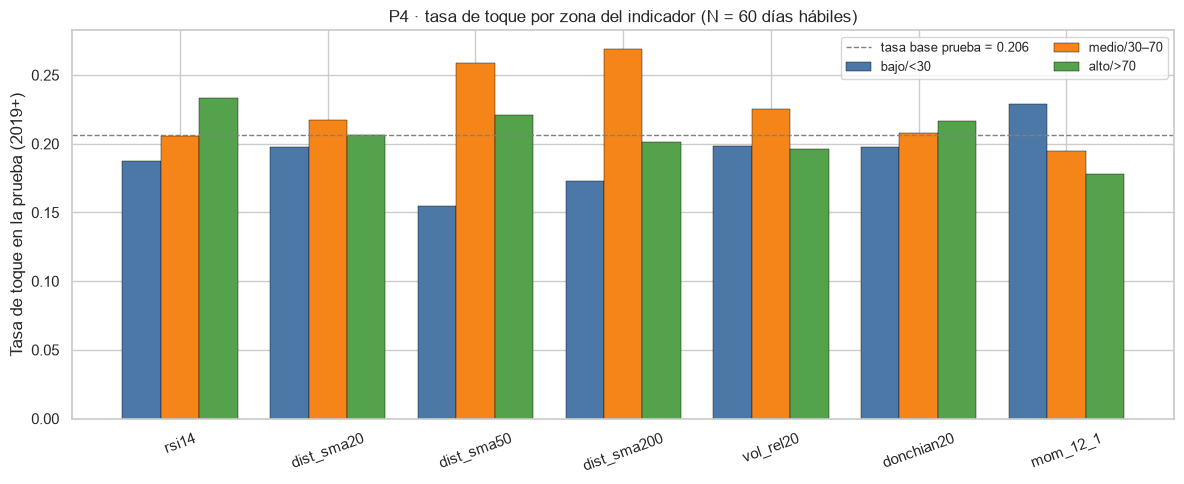

  indicador  zona  tasa_toque   n
      rsi14   <30      0.1875  16
      rsi14 30–70      0.2053 604
      rsi14   >70      0.2333  30
 dist_sma20  bajo      0.1977 263
 dist_sma20 medio      0.2172 198
 dist_sma20  alto      0.2063 189
 dist_sma50  bajo      0.1544 259
 dist_sma50 medio      0.2587 201
 dist_sma50  alto      0.2211 190
dist_sma200  bajo      0.1729 295
dist_sma200 medio      0.2690 171
dist_sma200  alto      0.2011 184
  vol_rel20  bajo      0.1982 227
  vol_rel20 medio      0.2255 204
  vol_rel20  alto      0.1963 219
 donchian20  bajo      0.1975 238
 donchian20 medio      0.2078 255
 donchian20  alto      0.2166 157
   mom_12_1  bajo      0.2290 310
   mom_12_1 medio      0.1946 149
   mom_12_1  alto      0.1780 191


In [40]:
# --- 5.5 Figura nb04_p4_zonas.png ---
def zonas_indicador(ind, serie_entr, serie_pru):
    if ind == "rsi14":
        bordes = [-np.inf, 30, 70, np.inf]
        etiquetas = ["<30", "30–70", ">70"]
    else:
        q1, q2 = np.nanquantile(serie_entr, [1/3, 2/3])  # terciles del entrenamiento, sin futuro
        bordes = [-np.inf, q1, q2, np.inf]
        etiquetas = ["bajo", "medio", "alto"]
    return pd.cut(serie_pru, bins=bordes, labels=etiquetas, include_lowest=True), etiquetas

tasa_base_prueba = float(sub_te["y"].mean())
filas_z = []
for ind in INDICADORES_7:
    zonas, etiquetas = zonas_indicador(ind, sub_tr[ind].to_numpy(), sub_te[ind].to_numpy())
    tasa_z = sub_te.assign(z=zonas).groupby("z", observed=False)["y"].agg(["mean", "size"])
    for e in etiquetas:
        filas_z.append({"indicador": ind, "zona": e,
                        "tasa_toque": float(tasa_z.loc[e, "mean"]) if e in tasa_z.index else np.nan,
                        "n": int(tasa_z.loc[e, "size"]) if e in tasa_z.index else 0})
tabla_zonas = pd.DataFrame(filas_z)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(INDICADORES_7))
w = 0.26
for i, (zc, offset, color) in enumerate([("bajo/<30", -w, "#4c78a8"),
                                          ("medio/30–70", 0.0, "#f58518"),
                                          ("alto/>70", +w, "#54a24b")]):
    tasas = []
    for ind in INDICADORES_7:
        subt = tabla_zonas[tabla_zonas["indicador"] == ind].reset_index(drop=True)
        tasas.append(float(subt.iloc[i]["tasa_toque"]))
    ax.bar(x + offset, tasas, width=w, label=zc, color=color, edgecolor="black", linewidth=0.3)
ax.axhline(tasa_base_prueba, color="grey", linestyle="--", linewidth=1,
           label=f"tasa base prueba = {tasa_base_prueba:.3f}")
ax.set_xticks(x); ax.set_xticklabels(INDICADORES_7, rotation=20)
ax.set_ylabel("Tasa de toque en la prueba (2019+)")
ax.set_title(f"P4 · tasa de toque por zona del indicador (N = {N_ELEGIDO} días hábiles)")
ax.legend(loc="upper right", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "nb04_p4_zonas.png", dpi=130)
plt.show()
print(tabla_zonas.to_string(index=False, float_format=lambda x: f"{x:,.4f}" if isinstance(x,float) and abs(x)<10 else f"{x:,.0f}"))


**Lectura.** Si para un indicador la barra de una zona queda claramente **por encima** o **por debajo** de la línea gris (tasa base de la prueba), ese valor del indicador "ordena" bien la etiqueta en esa zona; cuando las tres zonas son parecidas entre sí y a la base, el indicador no agrega información más allá de la volatilidad. Esta figura es descriptiva: la decisión de P4 la toma el IC del `ΔAUC` en §5.3; aquí solo rastreamos **dónde** se separa cada indicador.

In [41]:
# --- 5.6 Estabilidad por subperíodo del ΔAUC (sensibilidad, sin decisión) ---
TRAMOS = [("2019-2021", "2019-01-01", "2021-12-31"),
          ("2022-2024", "2022-01-01", "2024-12-31"),
          ("2025+",     "2025-01-01", "2099-12-31")]
filas_sp = []
for ind in INDICADORES_7:
    for nombre, ini, fin in TRAMOS:
        m = (sub_te_boot["fecha"] >= pd.Timestamp(ini)) & (sub_te_boot["fecha"] <= pd.Timestamp(fin))
        d = sub_te_boot.loc[m]
        if len(d) == 0 or d["y"].nunique() < 2:
            filas_sp.append({"indicador": ind, "tramo": nombre, "n": len(d), "delta_auc": np.nan}); continue
        a = float(roc_auc_score(d["y"], d["p_A"]))
        b = float(roc_auc_score(d["y"], d[f"p_B_{ind}"]))
        filas_sp.append({"indicador": ind, "tramo": nombre, "n": len(d), "delta_auc": b - a})
tabla_subp = pd.DataFrame(filas_sp).pivot(index="indicador", columns="tramo", values="delta_auc")
print("ΔAUC por subperíodo (sensibilidad; no decide):")
print(tabla_subp.to_string(float_format=lambda x: f"{x:+.4f}"))


ΔAUC por subperíodo (sensibilidad; no decide):
tramo        2019-2021  2022-2024   2025+
indicador                                
dist_sma20     -0.0425    +0.0017 +0.0490
dist_sma200    +0.0035    +0.0043 -0.0000
dist_sma50     -0.0516    -0.0219 +0.0048
donchian20     +0.0015    +0.0105 -0.0407
mom_12_1       -0.0045    -0.0043 -0.0271
rsi14          -0.0161    +0.0107 -0.0285
vol_rel20      +0.0044    -0.0062 -0.0031


**Lectura.** Si un indicador tiene el mismo signo en los tres tramos, el efecto es **estable**; si cambia de signo entre tramos, el `ΔAUC` global promedia efectos que se cancelan y se declara en las limitaciones. Esta tabla es descriptiva y no decide.

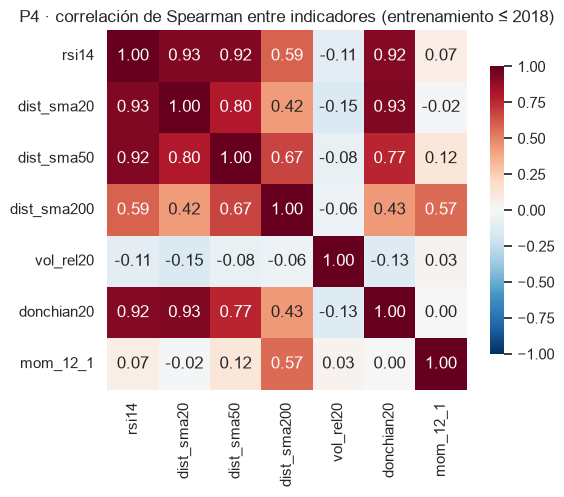

Pares con |ρ| ≥ 0.80 (regla fijada antes de estimar):
  rsi14  vs  dist_sma20:   ρ = +0.926
  rsi14  vs  dist_sma50:   ρ = +0.924
  rsi14  vs  donchian20:   ρ = +0.918
  dist_sma20  vs  dist_sma50:   ρ = +0.802
  dist_sma20  vs  donchian20:   ρ = +0.929


In [42]:
# --- 5.7 Redundancia: matriz de Spearman entre los 7 indicadores (en el entrenamiento) ---
rho = sub_tr[list(INDICADORES_7)].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("P4 · correlación de Spearman entre indicadores (entrenamiento ≤ 2018)")
plt.tight_layout()
plt.savefig(ASSETS / "nb04_spearman_indicadores.png", dpi=130)
plt.show()

# Pares con |ρ| ≥ RHO_REDUNDANCIA
pares_altos = []
nn = list(INDICADORES_7)
for i in range(len(nn)):
    for j in range(i+1, len(nn)):
        r = float(rho.iloc[i, j])
        if abs(r) >= RHO_REDUNDANCIA:
            pares_altos.append((nn[i], nn[j], r))
print(f"Pares con |ρ| ≥ {RHO_REDUNDANCIA:.2f} (regla fijada antes de estimar):")
for a, b, r in pares_altos:
    print(f"  {a}  vs  {b}:   ρ = {r:+.3f}")
if not pares_altos:
    print("  (ningún par supera el umbral)")


**Lectura.** Cinco pares superan |ρ| = 0,80 en el entrenamiento: RSI con la distancia a la media de 20 días (0,93), con la de 50 días (0,92) y con Donchian (0,92); distancia a la media de 20 días con la de 50 (0,80) y con Donchian (0,93). Los cuatro indicadores de "posición del precio reciente" son casi intercambiables; la media de 200 días, el volumen relativo y el momentum no son redundantes con ninguno.

**Justificación:** cuando dos indicadores tienen |ρ| ≥ 0,80, uno de los dos aporta esencialmente la misma información que el otro: dejar ambos en el SVM infla la colinealidad sin ganancia. La regla de exclusión se fija **antes** de estimar y se aplica en §5.9 cuando se arme la lista `variables_svm`: entre un par redundante, se conserva el que tenga mayor `ΔAUC` observado en §5.3; si empatan, el más simple de interpretar (RSI y Donchian son `[0,1]`; las distancias a medias y el momentum son retornos).

PCA sobre los 7 indicadores (entrenamiento ≤ 2018):
  varianza explicada por componente: PC1=0.574, PC2=0.201, PC3=0.140, PC4=0.046, PC5=0.020
  varianza acumulada en PC1+PC2: 0.775

Cargas (correlación aproximada entre variable y componente):
                PC1     PC2     PC3     PC4     PC5
rsi14        0.4820 -0.1210  0.0600  0.0290  0.0380
dist_sma20   0.4580 -0.2170  0.0610  0.1900 -0.5340
dist_sma50   0.4670  0.0160  0.0800 -0.4780 -0.3290
dist_sma200  0.3590  0.5130 -0.0490 -0.4430  0.4640
vol_rel20   -0.0770  0.1420  0.9850  0.0500  0.0340
donchian20   0.4410 -0.2360  0.0250  0.5240  0.5560
mom_12_1     0.1050  0.7740 -0.1150  0.5120 -0.2810


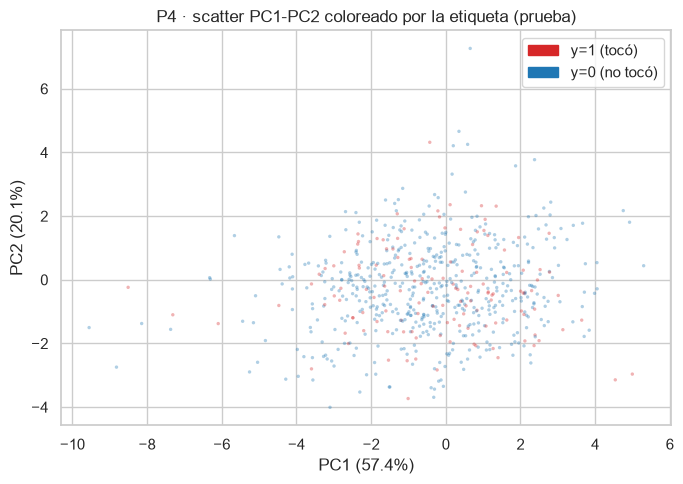

In [43]:
# --- 5.8 PCA de los 7 indicadores en el entrenamiento (varianza, cargas y scatter PC1-PC2 por etiqueta) ---
from sklearn.decomposition import PCA

sc_i = StandardScaler().fit(sub_tr[list(INDICADORES_7)])
pca = PCA(n_components=min(5, len(INDICADORES_7))).fit(sc_i.transform(sub_tr[list(INDICADORES_7)]))

varianza_exp = pca.explained_variance_ratio_
print("PCA sobre los 7 indicadores (entrenamiento ≤ 2018):")
print("  varianza explicada por componente: " + ", ".join(f"PC{i+1}={v:.3f}" for i,v in enumerate(varianza_exp)))
print(f"  varianza acumulada en PC1+PC2: {varianza_exp[:2].sum():.3f}")

cargas = pd.DataFrame(pca.components_, columns=list(INDICADORES_7),
                      index=[f"PC{i+1}" for i in range(len(varianza_exp))]).T
print("\nCargas (correlación aproximada entre variable y componente):")
print(cargas.round(3).to_string())

# Scatter PC1-PC2 coloreado por la etiqueta (prueba, para no sobreexponer el entrenamiento)
Xte = sc_i.transform(sub_te[list(INDICADORES_7)])
Zte = pca.transform(Xte)[:, :2]
fig, ax = plt.subplots(figsize=(7, 5))
colores = np.where(sub_te["y"].to_numpy() == 1, "#d62728", "#1f77b4")
ax.scatter(Zte[:, 0], Zte[:, 1], s=6, alpha=0.35, c=colores, linewidth=0)
ax.set_xlabel(f"PC1 ({varianza_exp[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({varianza_exp[1]*100:.1f}%)")
ax.set_title("P4 · scatter PC1-PC2 coloreado por la etiqueta (prueba)")
import matplotlib.patches as mpatches
ax.legend(handles=[mpatches.Patch(color="#d62728", label="y=1 (tocó)"),
                   mpatches.Patch(color="#1f77b4", label="y=0 (no tocó)")], loc="upper right")
plt.tight_layout()
plt.savefig(ASSETS / "nb04_pca_indicadores.png", dpi=130)
plt.show()


**Lectura.** Las dos primeras componentes resumen el 77,5 % de la variación conjunta de los 7 indicadores (57,4 % y 20,1 %). La primera pesa casi por igual al RSI, a las distancias a las medias de 20 y 50 días y a la posición en el canal de Donchian (cargas de 0,44 a 0,48): todas miden lo mismo, "dónde está el precio respecto de su pasado reciente". La segunda la dominan el momentum de 12 meses (0,77) y la distancia a la media de 200 días (0,51), es decir, la tendencia larga, y la tercera es casi solo el volumen relativo (0,99). Esto confirma la redundancia de §5.7. El scatter muestra cómo se reparten las dos clases de la etiqueta en ese plano; cuánto separan se cuantifica con la ΔAUC de §5.3, donde ningún indicador resultó accionable.

### 5.9 Variables del SVM: magnitud siempre + indicadores accionables (sin redundantes)

**Regla (fijada antes):**
- la **magnitud** (`|r_t|`, `σ20/σ252`, `σ252`) entra siempre: es la línea base de magnitud, no "aporta algo extra", es la referencia;
- un **indicador** entra si su `ΔAUC` es **accionable** (límite inferior del IC Bonferroni > 0,01);
- entre un par redundante (|ρ| ≥ 0,80 en §5.7), se conserva el de mayor `ΔAUC`; en empate, el más simple (RSI y Donchian son `[0,1]`; las distancias a medias y el momentum son retornos).

**Resultado en esta corrida:** `len(indicadores accionables) = 0`; `variables_svm` queda solo con las 3 variables de magnitud.

**Fuga de selección (declarada).** La lista `variables_svm` sale del tramo **2019+**; para que el SVM de la entrega 2 no se evalúe sobre las mismas fechas, se evaluará en un tramo posterior o con validación cronológica sobre ≤ 2018 ([§4.4 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md)).

**Por qué `σ20/σ252` y no `σ20` sola.** La ratio mide la volatilidad corta **relativa** a la larga (régimen tranquilo/agitado), no la absoluta; usar `σ20` y `σ252` por separado introduce colinealidad entre ellas.

In [44]:
# --- 5.9 Lista variables_svm aplicando la regla de redundancia + accionable ---
accionables = tabla_p4.index[tabla_p4["decision_negocio"] == "accionable"].tolist()
# Si quedan dos accionables con |ρ|≥RHO, descartar el de menor ΔAUC
descartados_por_redundancia = []
accionables_filtrados = list(accionables)
if len(accionables_filtrados) > 1:
    cambios = True
    while cambios:
        cambios = False
        for i in range(len(accionables_filtrados)):
            for j in range(i+1, len(accionables_filtrados)):
                a, b = accionables_filtrados[i], accionables_filtrados[j]
                if abs(float(rho.loc[a, b])) >= RHO_REDUNDANCIA:
                    perdedor = a if tabla_p4.loc[a, "delta_auc"] < tabla_p4.loc[b, "delta_auc"] else b
                    descartados_por_redundancia.append((perdedor, a, b, float(rho.loc[a, b])))
                    accionables_filtrados.remove(perdedor)
                    cambios = True
                    break
            if cambios: break

variables_magnitud = list(VARS_A)
variables_svm = variables_magnitud + accionables_filtrados
print("Justificación: la magnitud entra siempre (es la línea base de magnitud); cada indicador entra solo si su")
print("ΔAUC es accionable (límite inferior del IC Bonferroni > 0,01); entre un par con |Spearman| ≥ 0,80 se")
print("conserva el de mayor ΔAUC. La fuga de selección (la lista se construye en 2019+) se declara en §5.10.")
print()
print("variables_svm (= magnitud fija + indicadores accionables, sin redundantes):")
for v in variables_svm:
    tag = "magnitud (siempre)" if v in VARS_A else (
          f"indicador accionable (ΔAUC={tabla_p4.loc[v,'delta_auc']:+.4f}, IC=[{tabla_p4.loc[v,'ic_lo']:+.4f}, {tabla_p4.loc[v,'ic_hi']:+.4f}])")
    print(f"  {v:<22}  {tag}")
if descartados_por_redundancia:
    print("\nDescartados por redundancia (|ρ|≥0,80 con otro accionable mejor):")
    for perdedor, a, b, r in descartados_por_redundancia:
        print(f"  {perdedor} eliminado del par ({a},{b}) con ρ={r:+.3f}")

# --- Serializamos tabla_p4 y variables_svm en data/resultados/nb04_p4.json ---
# Estructura (fuente única para la tarea 8b, documentada en comentarios):
#   N_elegido:                int, horizonte en días hábiles
#   auc_base_decil_prueba:    float, AUC de la línea base por decil de σ252 en la prueba
#   auc_modelo_A_prueba:      float, AUC del modelo A (magnitud) en la prueba, submuestra sin solapamiento
#   nivel_bonferroni:         float, nivel del IC (≈ 0,993)
#   umbral_p4:                float, ΔAUC mínima accionable
#   bloque_fechas:            int, tamaño del bloque del bootstrap en fechas de la submuestra
#   reps:                     int, réplicas
#   tabla_p4:                 lista[dict] con indicador, delta_auc, ic_lo, ic_hi, decision_estadistica, decision_negocio
#   variables_svm:            lista[str] con el orden final de variables
#   descartados_por_redundancia: lista con (perdedor, a, b, rho)
JSON_OUT = cm.RAIZ / "data" / "resultados" / "nb04_p4.json"
JSON_OUT.parent.mkdir(parents=True, exist_ok=True)
payload = {
    "N_elegido": int(N_ELEGIDO),
    "k_sigma": int(K_SIGMA),
    "auc_base_decil_prueba": float(auc_base_prueba),
    "auc_modelo_A_prueba": float(auc_A_te),
    "nivel_bonferroni": float(NIVEL_P4),
    "umbral_p4": float(UMBRAL_P4),
    "bloque_fechas": int(BLOQUE_P4_FECHAS),
    "reps": int(REPS_P4),
    "tabla_p4": tabla_p4.reset_index().to_dict(orient="records"),
    "variables_svm": list(variables_svm),
    "descartados_por_redundancia": [{"perdedor": p, "a": a, "b": b, "rho": r}
                                     for p, a, b, r in descartados_por_redundancia],
    "subperiodos_delta_auc": tabla_subp.reset_index().to_dict(orient="records"),
    "sensibilidad_bloque": tabla_sens_bloque.to_dict(orient="records"),
    "sensibilidad_todas_filas": tabla_todas_filas.reset_index().to_dict(orient="records"),
}
with open(JSON_OUT, "w") as f:
    json.dump(payload, f, indent=1, ensure_ascii=False)
print(f"\nGuardado: {JSON_OUT.relative_to(cm.RAIZ)}  (tabla_p4 + variables_svm; fuente única para la tarea 8b)")


Justificación: la magnitud entra siempre (es la línea base de magnitud); cada indicador entra solo si su
ΔAUC es accionable (límite inferior del IC Bonferroni > 0,01); entre un par con |Spearman| ≥ 0,80 se
conserva el de mayor ΔAUC. La fuga de selección (la lista se construye en 2019+) se declara en §5.10.

variables_svm (= magnitud fija + indicadores accionables, sin redundantes):
  abs_r                   magnitud (siempre)
  sigma20_sigma252        magnitud (siempre)
  sigma252                magnitud (siempre)

Guardado: data/resultados/nb04_p4.json  (tabla_p4 + variables_svm; fuente única para la tarea 8b)


### 5.10 Decisión final de P4 e implicación para el producto

**Decisión por indicador** (estadística y de negocio) imprimida en la tabla `tabla_p4` de §5.3. La **estadística** usa el IC Bonferroni al ≈ 99,3 % frente a 0; la **de negocio** usa la misma regla única del nb03 §4.9 contra el umbral `0,01`.

**Implicación.** La lista `variables_svm` es el aporte a la entrega 2: la magnitud entra siempre y un indicador entraría solo si su ΔAUC fuera accionable; en esta corrida ninguno lo es, así que la lista queda solo con la magnitud. Se declara la **fuga de selección** (la lista se construyó en 2019+; el SVM se validará en un tramo posterior o con validación cronológica sobre ≤ 2018). Las métricas del SVM se mencionan como lo que se evalúa en la entrega 2:

- **AUC** y **Brier** sobre la **línea base por decil de σ252 diaria** (§4.5), con corte cronológico y un espacio de ≥ `N_ELEGIDO` sesiones hábiles;
- regla: el SVM es **accionable** si el límite inferior del IC de `ΔAUC` supera **0,03** ([§4.4 del enfoque analítico](../docs/entrega_1/04_enfoque_analitico.md)).

**Limitaciones.** (i) El umbral de 0,01 y las variables de magnitud se fijaron después de la exploración previa; no se cambiaron para acercarse al resultado. (ii) La submuestra sin solapamiento tiene **n relativamente pequeño** (~1 fila cada `N_ELEGIDO` sesiones por ticker), por eso usamos nivel 99,3 % para controlar la multiplicidad sin inflar la varianza. (iii) Fuga de selección por período: la lista `variables_svm` sale del tramo 2019+. (iv) La censura (filas sin resultado futuro) y las filas de calentamiento se excluyen; se contaron antes. (v) Industria piloto; la lista podría ser otra en otra industria.

---

**Continúa en §6 (tarea 8b):** P5 (¿cuánto del movimiento viene del sector?), PCA de los 21 retornos y síntesis.

## 6. P5 — ¿cuánto del movimiento viene del sector?

**Pregunta de negocio.** Cuando una acción de consumo defensivo se mueve en una semana, ¿cuánto de ese movimiento lo explica su sector (el XLP) por encima de lo que ya explica el mercado (el SPY)? Si el sector agrega poco, la simulación de la lectura probabilística puede usar solo el mercado; si agrega mucho, debe incluir el sector.

**Herramientas aplicadas.** Regresión lineal múltiple por empresa, el [R²](../docs/entrega_1/glosario.md) (proporción de la varianza del retorno que explica el modelo) y su aumento **ΔR²** al agregar el XLP: ΔR² = R²(r ~ r_SPY + r_XLP) − R²(r ~ r_SPY). La [prueba F de modelos anidados](../docs/entrega_1/glosario.md) compara los dos modelos; aquí solo es referencia porque supone residuos normales e independientes.

**Paso 0 (umbral práctico, fijado antes de estimar).** ΔR² mediano de las empresas ≥ `UMBRAL_P5` = 0,05: el sector debe explicar al menos 5 % más de la varianza semanal que el mercado solo. Por debajo de eso, el sector casi no cambia la simulación.

**H0:** ΔR² mediano = 0 (el XLP no agrega nada sobre el SPY). **H1:** ΔR² mediano > 0. α = 0,05.

**Advertencia sobre esta H0.** ΔR² ≥ 0 por construcción (agregar una variable nunca baja el R² dentro de la muestra), así que el IC de la mediana casi nunca incluye 0: la decisión estadística se reporta solo por completitud. **La decisión que responde la pregunta es la de negocio** (límite inferior del IC frente a 0,05).

**Circularidad (limitación declarada).** La industria piloto se eligió, entre otras razones, por su ΔR² exploratorio; P5 confirma una propiedad usada para elegirla y **no es evidencia independiente**. Es descriptiva y confirmatoria, y se mantiene en la lista de 15 pruebas porque esa lista se fijó antes de ejecutar.

In [45]:
# --- 6.1 Retornos semanales (precio ajustado por dividendos) y dos regresiones por empresa ---
from statsmodels.stats.anova import anova_lm
sem_p5 = cm.cargar_snapshot("precios_semanales")
sem_p5 = sem_p5[sem_p5.ticker.isin(acciones + ["SPY", "XLP"])].copy()
R5 = np.log(cm.a_ancho(sem_p5)).diff()          # log-retorno semanal, filas = semanas, columnas = tickers
print(f"semanas: {len(R5)} ({R5.index.min().date()} a {R5.index.max().date()}); tickers: {R5.shape[1]}")

filas_p5, modelos_p5 = [], {}
for t in acciones:
    d = R5[[t, "SPY", "XLP"]].dropna().rename(columns={t: "r", "SPY": "r_spy", "XLP": "r_xlp"})
    m1 = smf.ols("r ~ r_spy", data=d).fit()               # solo mercado
    m2 = smf.ols("r ~ r_spy + r_xlp", data=d).fit()       # mercado + sector
    f = anova_lm(m1, m2)                                  # F de modelos anidados (solo referencia)
    modelos_p5[t] = (m1, m2, d)
    filas_p5.append({"ticker": t, "n_semanas": len(d), "r2_spy": m1.rsquared, "r2_spy_xlp": m2.rsquared,
                     "delta_r2": m2.rsquared - m1.rsquared, "F": float(f["F"].iloc[1]), "p_F": float(f["Pr(>F)"].iloc[1])})
df_p5 = pd.DataFrame(filas_p5).sort_values("delta_r2").reset_index(drop=True)
print(df_p5.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nΔR² — mínimo {df_p5.delta_r2.min():.4f} | mediana {df_p5.delta_r2.median():.4f} | máximo {df_p5.delta_r2.max():.4f}")
print(f"empresas con ΔR² ≥ {UMBRAL_P5}: {(df_p5.delta_r2 >= UMBRAL_P5).sum()} de {len(df_p5)}")

semanas: 928 (2009-01-05 a 2026-10-12); tickers: 23


ticker  n_semanas  r2_spy  r2_spy_xlp  delta_r2        F    p_F
   ADM        927  0.2457      0.2905    0.0447  58.2654 0.0000
   TSN        927  0.1548      0.2107    0.0558  65.3604 0.0000
   STZ        927  0.2596      0.3186    0.0590  79.9738 0.0000
   SYY        927  0.3252      0.3943    0.0690 105.3034 0.0000
  COST        927  0.3072      0.4114    0.1042 163.6027 0.0000
    KR        927  0.0498      0.1824    0.1327 149.9285 0.0000
   CLX        927  0.0933      0.2685    0.1752 221.2927 0.0000
   WMT        927  0.1525      0.3376    0.1851 258.1652 0.0000
   MKC        927  0.1432      0.3554    0.2123 304.2925 0.0000
   HSY        927  0.1330      0.3571    0.2241 322.1394 0.0000
   CHD        927  0.1089      0.3335    0.2246 311.3600 0.0000
    PM        927  0.2132      0.4426    0.2294 380.3700 0.0000
    MO        927  0.1603      0.4068    0.2466 384.0761 0.0000
   CAG        927  0.0985      0.3473    0.2488 352.1650 0.0000
    KO        927  0.3190      0.6101   

**Lectura.** Con 927 semanas por empresa, el ΔR² va de 0,045 (ADM) a 0,371 (PG), con mediana 0,225; 20 de las 21 empresas superan el umbral de 0,05. El mercado solo explica poco de estas acciones (R² con el SPY de 0,05 en KR a 0,33 en SYY), y el sector agrega mucho en la mayoría: KO pasa de 0,32 a 0,61 y PG de 0,26 a 0,63. La F de modelos anidados da p < 0,0001 en las 21, pero es solo referencia porque los residuos tienen colas pesadas (abajo).

### 6.2 Matriz de supuestos de P5

| Supuesto | Por qué importa | Verificación ejecutada (abajo) | Acción si falla |
|---|---|---|---|
| Colinealidad SPY–XLP | Si el mercado y el sector se mueven casi igual, los coeficientes son inestables (el ΔR² no se ve afectado) | Correlación de los retornos y [VIF](../docs/entrega_1/glosario.md) = 1 / (1 − ρ²) | Se leen el R² y el ΔR², no los coeficientes |
| Residuos con colas pesadas | La F supone residuos normales | QQ-plot de los residuos de 3 empresas y su exceso de curtosis | La F queda como referencia; decide el IC por bootstrap |
| Independencia en el tiempo | La F supone residuos independientes | Correlación de cada residuo con su valor de la semana anterior (mediana de las 21) | Decide el IC por empresa, que no supone independencia semanal |
| El XLP contiene a la propia acción | Una empresa grande "se explica a sí misma" a través del XLP | Participación de cada empresa en la capitalización de las 21 (aproxima su peso en el XLP, que pondera por capitalización) | Se señalan las de mayor peso y se repite la mediana sin ellas |
| Número de empresas | El bootstrap por empresa tiene solo 21 grupos | Se imprime n | Limitación declarada |

correlación semanal SPY–XLP: 0.715  →  VIF = 1/(1−ρ²) = 2.05 (umbral habitual 10)
autocorrelación a 1 semana de los residuos: mediana -0.037 (mín -0.153, máx +0.026)
exceso de curtosis de los residuos: mediana 4.99 (mín 1.58, máx 18.11)

participación en la capitalización de las 21 (las 5 mayores):
ticker
WMT     29.4 %
COST    13.6 %
KO      12.4 %
PG      11.4 %
PM       9.8 %
ΔR² de las 4 de mayor peso: WMT 0.185, COST 0.104, KO 0.291, PG 0.371


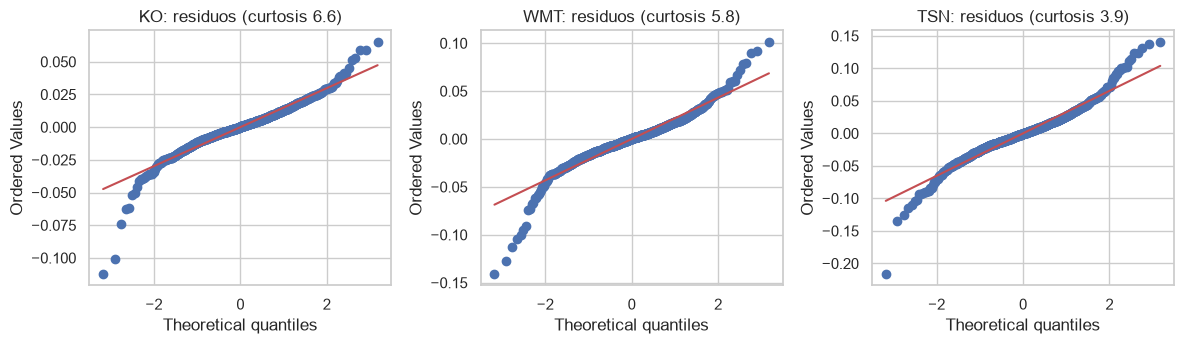

In [46]:
# --- 6.2 Verificaciones de la matriz de supuestos ---
rho_mx = float(R5[["SPY", "XLP"]].dropna().corr().iloc[0, 1])
print(f"correlación semanal SPY–XLP: {rho_mx:.3f}  →  VIF = 1/(1−ρ²) = {1/(1-rho_mx**2):.2f} (umbral habitual {VIF_UMBRAL})")

# Independencia: autocorrelación a 1 semana de los residuos del modelo completo
ac_res = pd.Series({t: modelos_p5[t][1].resid.autocorr(1) for t in acciones})
print(f"autocorrelación a 1 semana de los residuos: mediana {ac_res.median():+.3f} (mín {ac_res.min():+.3f}, máx {ac_res.max():+.3f})")
curt_res = pd.Series({t: float(stats.kurtosis(modelos_p5[t][1].resid)) for t in acciones})
print(f"exceso de curtosis de los residuos: mediana {curt_res.median():.2f} (mín {curt_res.min():.2f}, máx {curt_res.max():.2f})")

# Peso aproximado en el XLP: participación en la capitalización de las 21 (info de yfinance, instantánea)
info5 = cm.cargar_snapshot("info_yf").set_index("ticker")
peso = (info5.loc[acciones, "marketCap"] / info5.loc[acciones, "marketCap"].sum()).sort_values(ascending=False)
print("\nparticipación en la capitalización de las 21 (las 5 mayores):")
print((peso.head(5) * 100).round(1).astype(str).add(" %").to_string())
grandes = peso.head(4).index.tolist()
print(f"ΔR² de las 4 de mayor peso: " + ", ".join(f"{t} {df_p5.set_index('ticker').delta_r2[t]:.3f}" for t in grandes))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, t in zip(axs, ["KO", "WMT", "TSN"]):
    stats.probplot(modelos_p5[t][1].resid, dist="norm", plot=ax)
    ax.set_title(f"{t}: residuos (curtosis {curt_res[t]:.1f})")
plt.tight_layout(); plt.show()

**Lectura.** La correlación semanal SPY–XLP es 0,715 y el VIF 2,05, muy por debajo de 10: la colinealidad no impide leer el ΔR². Los residuos casi no se correlacionan con los de la semana anterior (mediana −0,037; de −0,153 a +0,026), pero tienen colas pesadas (exceso de curtosis mediano 4,99, hasta 18,11), como muestran los QQ-plots de KO, WMT y TSN; por eso la F no decide. WMT, COST, KO y PG suman el 66,8 % de la capitalización de las 21 (WMT sola, 29,4 %) y por eso pesan más en el XLP. Sus ΔR² están repartidos: PG (0,371) y KO (0,291) en el tercio superior, WMT (0,185) y COST (0,104) en la mitad inferior.

### 6.3 Estimación con IC (antes del p-value) y decisiones

El estimando es la **mediana de ΔR² de las 21 empresas** (la empresa típica). El IC sale del bootstrap **por empresa** (`cm.ic_bootstrap_grupos`, 1000 réplicas): cada réplica sortea 21 empresas con reemplazo y recalcula la mediana. Como sensibilidad, la mediana se repite sin las 4 empresas de mayor peso en el XLP.

In [47]:
# --- 6.3 Mediana de ΔR² con IC por empresa, p-value bootstrap y decisiones ---
med = lambda d: float(d["delta_r2"].median())
est_p5, lo_p5, hi_p5, reps_p5 = cm.ic_bootstrap_grupos(df_p5, med, col_grupo="ticker", reps=REPS_BOOT,
                                                        semilla=RNG_SEMILLA, devolver_reps=True)
p_boot_p5 = float((1 + int((reps_p5 <= 0).sum())) / (1 + len(reps_p5)))   # H1 "mayor": réplicas ≤ 0
rechaza_p5 = lo_p5 > 0
dec_est_p5 = "se rechaza H0" if rechaza_p5 else "no se rechaza H0"
dec_neg_p5 = decision_negocio(lo_p5, hi_p5, UMBRAL_P5, rechaza_p5)
print(f"P5 — ΔR² mediano: {est_p5:.4f}   IC95 por empresa: [{lo_p5:.4f}, {hi_p5:.4f}]   (n = {len(df_p5)} empresas)")
print(f"p-value bootstrap unilateral (nulo = 0): {p_boot_p5:.4f}")
print(f"umbral de negocio: {UMBRAL_P5}")
print(f"decisión estadística: {dec_est_p5}   |   decisión de negocio: {dec_neg_p5}")

sin_grandes = df_p5[~df_p5.ticker.isin(grandes)]
e_sg, lo_sg, hi_sg = cm.ic_bootstrap_grupos(sin_grandes, med, col_grupo="ticker", reps=REPS_BOOT, semilla=RNG_SEMILLA)
print(f"\nsensibilidad sin {', '.join(grandes)}: ΔR² mediano {e_sg:.4f}  IC95 [{lo_sg:.4f}, {hi_sg:.4f}]  (no decide)")

P5 — ΔR² mediano: 0.2246   IC95 por empresa: [0.1752, 0.2911]   (n = 21 empresas)
p-value bootstrap unilateral (nulo = 0): 0.0010
umbral de negocio: 0.05
decisión estadística: se rechaza H0   |   decisión de negocio: accionable



sensibilidad sin WMT, COST, KO, PG: ΔR² mediano 0.2246  IC95 [0.1327, 0.3001]  (no decide)


**Lectura.** El ΔR² mediano es 0,225, con IC95 por empresa [0,175; 0,291] y p bootstrap de 0,001. **Decisión estadística: se rechaza H0**, algo esperable porque el ΔR² nunca es negativo. **Decisión de negocio: accionable**, porque el límite inferior (0,175) supera el umbral de 0,05: para la empresa típica de la industria, el sector explica unos 22 puntos porcentuales más de la varianza semanal que el mercado solo. Sin las 4 empresas de mayor peso en el XLP (WMT, COST, KO, PG) la mediana vuelve a 0,2246 (**CHD** es la empresa mediana tanto en el universo completo —posición 11 de 21— como en el subconjunto —posición 9 de 17—; el valor exacto coincide porque la empresa típica no cambia); el IC se amplía a [0,133; 0,300] por el menor número de empresas en el bootstrap. El resultado no depende de que el XLP contenga a las más grandes. Es una confirmación y no evidencia independiente (circularidad declarada arriba). **Implicación para el producto:** la simulación de la lectura probabilística usa el XLP además del SPY.

In [48]:
# --- 6.4 ΔR² mediano por subperíodo (¿el sector pesa más en las crisis?) ---
filas_sp = []
for nombre, (a, b) in SUBPERIODOS_P5.items():
    vals = []
    for t in acciones:
        d = modelos_p5[t][2].loc[a:b]
        if len(d) < 52:                       # menos de un año de semanas: no se estima
            continue
        r1 = smf.ols("r ~ r_spy", data=d).fit().rsquared
        r2 = smf.ols("r ~ r_spy + r_xlp", data=d).fit().rsquared
        vals.append(r2 - r1)
    filas_sp.append({"subperíodo": nombre, "empresas": len(vals), "ΔR² mediano": float(np.median(vals)),
                     "mínimo": float(np.min(vals)), "máximo": float(np.max(vals))})
print(pd.DataFrame(filas_sp).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

subperíodo  empresas  ΔR² mediano  mínimo  máximo
 2009–2012        21       0.0968  0.0041  0.2671
 2013–2019        21       0.2274  0.0260  0.3889
 2020–2021        21       0.1845  0.0015  0.4594
     2022+        21       0.3065  0.0593  0.5375


**Lectura.** El ΔR² mediano es positivo en los cuatro tramos, pero no es estable: es menor en los tramos de choque general (0,097 en 2009–2012 y 0,185 en 2020–2021) que en los demás (0,227 en 2013–2019 y 0,307 desde 2022). El sector no pesa más en las crisis: cuando todo el mercado cae junto, el SPY ya explica buena parte del movimiento y el XLP agrega menos. Es una asociación por tramos; con 21 empresas por tramo no se prueba una diferencia entre ellos.

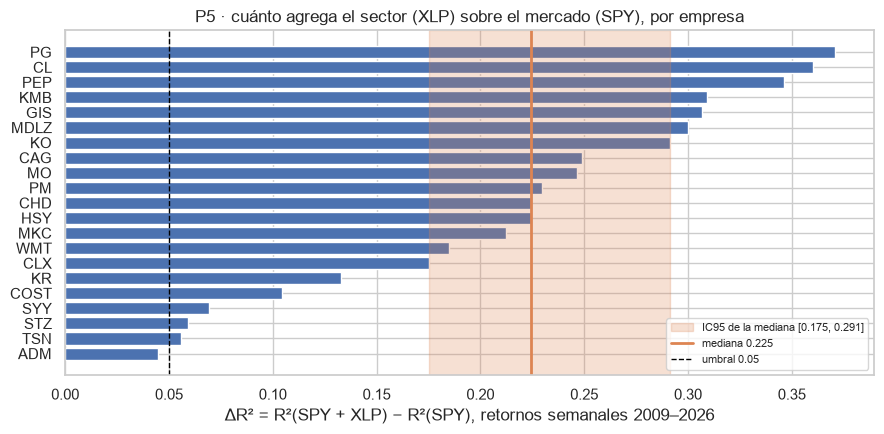

In [49]:
# --- 6.5 Figura: ΔR² por empresa, ordenado, con la mediana, su IC y el umbral ---
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(df_p5.ticker, df_p5.delta_r2, color="#4c72b0")
ax.axvspan(lo_p5, hi_p5, color="#dd8452", alpha=0.25, label=f"IC95 de la mediana [{lo_p5:.3f}, {hi_p5:.3f}]")
ax.axvline(est_p5, color="#dd8452", lw=2, label=f"mediana {est_p5:.3f}")
ax.axvline(UMBRAL_P5, color="black", ls="--", lw=1, label=f"umbral {UMBRAL_P5}")
ax.set_xlabel("ΔR² = R²(SPY + XLP) − R²(SPY), retornos semanales 2009–2026")
ax.set_title("P5 · cuánto agrega el sector (XLP) sobre el mercado (SPY), por empresa")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(ASSETS / "nb04_p5_delta_r2.png", dpi=130); plt.show()

**Lectura.** Solo ADM (0,045) queda por debajo del umbral de 0,05; las otras 20 lo superan, y el IC de la mediana [0,175; 0,291] queda entero a la derecha del umbral. Tres de las cuatro empresas con menor ΔR² (ADM, STZ y SYY) están también en el extremo negativo de la segunda componente del PCA de §6.6, es decir, son las que menos se mueven con el resto de la industria.

### 6.6 PCA de los 21 retornos semanales y clustermap (descriptivo, no decide)

El [PCA](../docs/entrega_1/glosario.md) resume los 21 retornos estandarizados en unas pocas direcciones: la primera componente (PC1) suele ser "todas suben o bajan juntas" (el mercado y el sector), y las siguientes muestran **subgrupos** que se mueven entre sí. El [clustermap](../docs/entrega_1/glosario.md) ordena la matriz de correlaciones para que las empresas que se mueven parecido queden juntas. La pregunta es descriptiva: ¿hay subgrupos dentro de la industria piloto (por ejemplo, minoristas frente a fabricantes, o tabaco)?

semanas con las 21 empresas: 927
varianza explicada: PC1 = 0.413, PC2 = 0.073, PC3 = 0.060
PC2: extremo negativo SYY, ADM, PM, STZ | extremo positivo KR, GIS, CHD, CLX
PC3: extremo negativo HSY, GIS, MKC, KMB | extremo positivo ADM, KR, COST, WMT

cargas (signo arbitrario por componente):
        PC1     PC2     PC3
SYY  0.2020 -0.3550  0.0430
ADM  0.1640 -0.3210  0.1820
PM   0.2120 -0.2730  0.0220
STZ  0.1880 -0.2530  0.0170
MO   0.2150 -0.2410  0.0230
KO   0.2580 -0.2350 -0.0100
TSN  0.1690 -0.1930 -0.0340
PEP  0.2650 -0.1060 -0.0640
MDLZ 0.2560 -0.0420 -0.1150
HSY  0.2270 -0.0230 -0.1710
PG   0.2610  0.0780 -0.0280
CL   0.2690  0.0800 -0.1310
MKC  0.2290  0.1000 -0.1390
COST 0.1930  0.1030  0.5070
CAG  0.2170  0.1430 -0.1140
KMB  0.2510  0.1770 -0.1370
WMT  0.1730  0.1770  0.5520
KR   0.1400  0.2240  0.4790
GIS  0.2160  0.2640 -0.1710
CHD  0.2170  0.3070 -0.0950
CLX  0.1990  0.3710 -0.1340


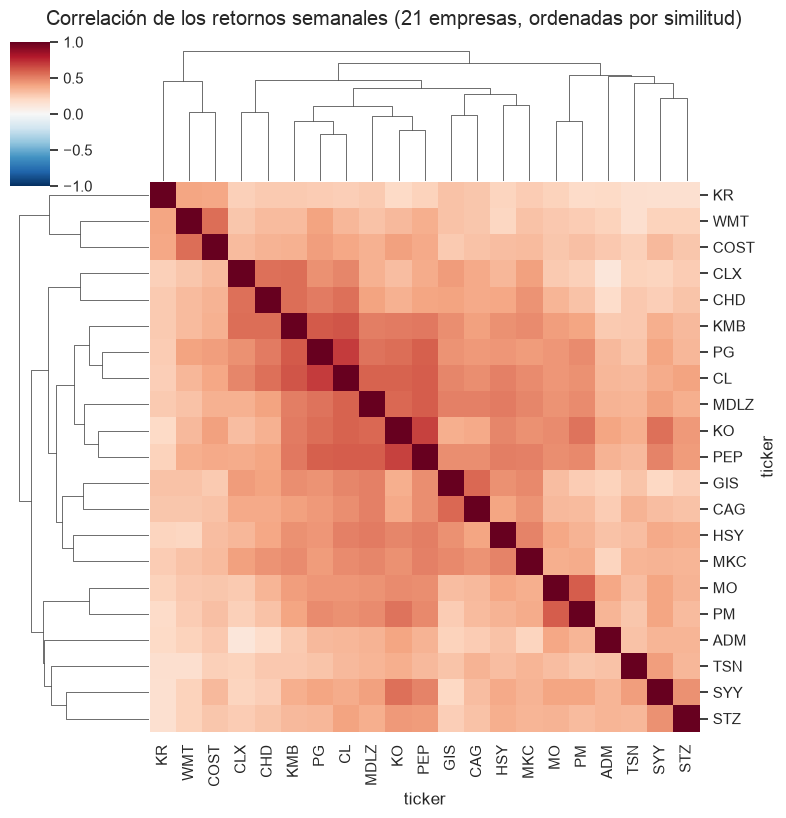

correlación entre pares: mediana 0.36; par más alto ('PG', 'CL') 0.70; más bajo ('ADM', 'CLX') 0.12


In [50]:
# --- 6.6 PCA de los retornos semanales (semanas con las 21 empresas) y clustermap ---
X5 = R5[acciones].dropna()
pca5 = PCA(n_components=PCA_COMPONENTES).fit(StandardScaler().fit_transform(X5))
print(f"semanas con las 21 empresas: {len(X5)}")
print("varianza explicada: " + ", ".join(f"PC{i+1} = {v:.3f}" for i, v in enumerate(pca5.explained_variance_ratio_)))
cargas5 = pd.DataFrame(pca5.components_.T, index=acciones, columns=[f"PC{i+1}" for i in range(PCA_COMPONENTES)])
for pc in ["PC2", "PC3"]:
    s = cargas5[pc].sort_values()
    print(f"{pc}: extremo negativo {', '.join(s.index[:4])} | extremo positivo {', '.join(s.index[-4:])}")
print("\ncargas (signo arbitrario por componente):")
print(cargas5.round(3).sort_values("PC2").to_string())

corr5 = X5.corr()
g = sns.clustermap(corr5, cmap="RdBu_r", center=0, vmin=-1, vmax=1, figsize=(8, 8), annot=False)
g.fig.suptitle("Correlación de los retornos semanales (21 empresas, ordenadas por similitud)", y=1.02)
g.savefig(ASSETS / "nb04_clustermap_retornos.png", dpi=110, bbox_inches="tight"); plt.show()
tri = corr5.where(np.triu(np.ones(corr5.shape, dtype=bool), k=1)).stack()
print(f"correlación entre pares: mediana {tri.median():.2f}; par más alto {tri.idxmax()} {tri.max():.2f}; más bajo {tri.idxmin()} {tri.min():.2f}")

**Lectura.** La primera componente explica el 41,3 % de la varianza de los 21 retornos y todas sus cargas son positivas (de 0,14 a 0,27): es el movimiento común de la industria y del mercado. La segunda (7,3 %) separa a SYY, ADM, PM y STZ (cargas negativas) de KR, GIS, CHD y CLX (positivas), una división que no corresponde a un subgrupo de negocio evidente. La tercera (6,0 %) sí aísla a los tres minoristas, WMT, COST y KR (cargas de 0,48 a 0,55), frente a fabricantes como HSY, GIS, MKC y KMB. En el clustermap, la correlación mediana entre pares es 0,36 (la más alta, PG–CL, 0,70; la más baja, ADM–CLX, 0,12). Hay subgrupos, pero débiles frente al factor común; es descriptivo y no decide.

## 7. Matriz de técnicas del EDA (los cuatro tipos: univariado/multivariado × gráfico/no gráfico)

Cada técnica se clasifica con dos ejes: cuántas variables mira (univariada o multivariada) y cómo presenta el resultado (gráfica o no gráfica). La tabla dice dónde se ejecutó.

| | **No gráfica** | **Gráfica** |
|---|---|---|
| **Univariada** | Media, desviación, asimetría, curtosis, IQR, MAD y percentil 5 por activo (nb03 §2); conteo de atípicos ±3σ e IQR con sensibilidad (nb03 §2); exceso de curtosis y % de \|z\| > 3 por frecuencia (nb03 §0); tasa de caídas fuertes con IC por bloques (nb03 §4, P1); completitud, duplicados, ceros y vacíos por campo (nb02) | Precio, retorno, volatilidad móvil y caída máxima (nb03 §1); boxplots por subperíodo (nb03 §0); histogramas en la misma escala (nb03 §0); histograma con KDE y QQ-plot (nb03 §3); tasa de caídas fuertes por empresa (nb03 §4); QQ-plot por quintil (nb04 §2 y §3) |
| **Multivariada** | Tablas 2×2 con chi-cuadrado, V de Cramér y residuos (nb03 §5, P6); Spearman de \|z_t\| frente a \|z_{t−1}\| (nb03 §5); diferencia de medias por quintil con Welch, Mann-Whitney e IC por empresa y por fechas (nb04 §2 y §3, P2 y P3); descomposiciones en log (nb04 §2 y §3); regresión con errores agrupados por empresa (nb04 §3); regresión logística, AUC y ΔAUC con IC por bloques (nb04 §5, P4); tasa de toque por decil de σ (nb04 §4); regresiones anidadas, ΔR², F y VIF (nb04 §6, P5); triangulación de fuentes (nb02) | Scatter de r_t frente a r_{t−1} (nb03 §0); percentil propio y en la industria en el tiempo (nb04 §2); descomposición por quintil (nb04 §2 y §3); tasa de toque por zona del indicador (nb04 §5); matriz de Spearman de los indicadores (nb04 §5); PCA de los indicadores (nb04 §5); ΔR² por empresa (nb04 §6); PCA y clustermap de los retornos (nb04 §6) |

## 8. Estado de las hipótesis y de las 15 pruebas declaradas

P1 y P6 se leen de `data/resultados/nb03.json` (nb04 no las recalcula); P2–P5 salen de este notebook. La tabla muestra dos IC: el de la **decisión estadística** (frente al nulo) y el de la **decisión de negocio** (frente al umbral). En P1, P2, P3 y P5 son el mismo; en P6 el estadístico es el de la diferencia P(T|T) − P(T|calma) y el de negocio el de P(T|T); en P2 y P3 se muestran anualizados (÷ 3).

**Multiplicidad.** La lista de 15 pruebas se fijó antes de ejecutar. Se reportan sin corrección global, salvo P4, que ya usa [Bonferroni](../docs/entrega_1/glosario.md) (α / 7 por indicador). Como sensibilidad se aplica **Holm** al 0,05 sobre las 13 pruebas con decisión de negocio: se ordenan sus p-values de menor a mayor y el i-ésimo se compara con 0,05 / (13 − i + 1); se rechaza mientras se cumpla y se para en la primera que no. Es como Bonferroni, pero menos estricto con las pruebas que siguen a las primeras. El p-value de cada prueba es el **p bootstrap unilateral de percentil**: la fracción de réplicas del bootstrap que caen del lado del nulo, p = (1 + réplicas del lado del nulo) / (1 + réplicas). Como todas las decisiones del proyecto usan el IC95 bilateral, que equivale a una prueba unilateral al 2,5 %, Holm compara en la misma escala: usa el p bilateral equivalente, 2 · p, frente a 0,05. Así, sin corrección, "2 · p ≤ 0,05" coincide exactamente con "el IC95 excluye el nulo". Por eso P1, con p unilateral de 0,049 (p bilateral equivalente 0,098), no rechaza H0. Ejemplos: para **P2**, p unilateral = 0,001; bilateral = 0,002; límite de Holm en su posición = 0,0038 → **sigue rechazando**. Para **P4 dist_sma200**, p = 0,247; bilateral = 0,494; límite = 0,0063 → **no rechaza**. Ninguna decisión del proyecto cambia con la corrección.

In [51]:
# --- 8.1 Tabla de las 15 pruebas (P1 y P6 desde nb03.json) y sensibilidad de Holm sobre las 13 con decisión ---
nb03 = json.loads((cm.RAIZ / "data" / "resultados" / "nb03.json").read_text(encoding="utf-8"))
def fila(prueba, e, ic_est, ic_neg, umbral, d_est, d_neg, p, e_est=None):
    return {"prueba": prueba, "estimado (negocio)": e, "estimado estadístico": e if e_est is None else e_est, "IC estadístico": ic_est, "IC de negocio": ic_neg, "umbral": umbral,
            "decisión estadística": d_est, "decisión de negocio": d_neg, "p_boot": p}
r = lambda a, b, k=4: f"[{a:.{k}f}; {b:.{k}f}]"
filas15 = [fila("P1 caídas fuertes (semanal)", nb03["P1"]["estimado"], r(*nb03["P1"]["ic_estadistico"]), r(*nb03["P1"]["ic"]),
                nb03["P1"]["umbral"], nb03["P1"]["decision_estadistica"], nb03["P1"]["decision_negocio"], nb03["P1"]["p_boot"], nb03["P1"]["estimado_estadistico"]),
           fila("P2 Δlog P/E normalizado, anual", est_p2_a, r(lo_p2_a, hi_p2_a), r(lo_p2_a, hi_p2_a), UMBRAL_P2, dec_est_p2, dec_neg_p2,
                float((1 + int((reps_p2[~np.isnan(reps_p2)] <= 0).sum())) / (1 + int((~np.isnan(reps_p2)).sum())))),
           fila("P3 exceso sobre el XLP, anual", est_p3_a, r(lo_p3_a, hi_p3_a), r(lo_p3_a, hi_p3_a), UMBRAL_P3, dec_est_p3, dec_neg_p3,
                float((1 + int((reps_p3[~np.isnan(reps_p3)] <= 0).sum())) / (1 + int((~np.isnan(reps_p3)).sum()))))]
for ind in INDICADORES_7:
    rp = reps_p4[ind][~np.isnan(reps_p4[ind])]
    t4 = tabla_p4.loc[ind]
    filas15.append(fila(f"P4 ΔAUC {ind} (IC 99,3 %)", t4.delta_auc, r(t4.ic_lo, t4.ic_hi), r(t4.ic_lo, t4.ic_hi), UMBRAL_P4,
                        t4.decision_estadistica, t4.decision_negocio, float((1 + int((rp <= 0).sum())) / (1 + len(rp)))))
filas15.append(fila("P5 ΔR² mediano (XLP sobre SPY)", est_p5, r(lo_p5, hi_p5), r(lo_p5, hi_p5), UMBRAL_P5, dec_est_p5, dec_neg_p5, p_boot_p5))
for k, nom in [("P6_diaria", "P6 P(T|T) diaria"), ("P6_semanal", "P6 P(T|T) semanal"),
               ("P6_dir_diaria", "P6 control de dirección diario"), ("P6_dir_semanal", "P6 control de dirección semanal")]:
    v = nb03[k]
    filas15.append(fila(nom, v["estimado"], r(*v["ic_estadistico"]), r(*v["ic"]), v["umbral"],
                        v["decision_estadistica"], v["decision_negocio"] or "— (solo estadística)", v["p_boot"], v["estimado_estadistico"]))
t15 = pd.DataFrame(filas15)

# Holm sobre las 13 con decisión de negocio (los 2 controles de dirección quedan fuera)
con_neg = t15[~t15.prueba.str.contains("control")].copy()
assert len(con_neg) == HOLM_M
# escala bilateral (2 · p unilateral): así "p ≤ 0,05" equivale a "el IC95 excluye el nulo", el criterio de todo el proyecto
t15["p_holm"] = np.minimum(1.0, 2 * t15["p_boot"])
con_neg = t15[~t15.prueba.str.contains("control")].copy()
orden = con_neg.sort_values("p_holm").index
holm = pd.Series("no", index=t15.index); sigue = True
for i, idx in enumerate(orden, start=1):
    limite = HOLM_ALFA / (HOLM_M - i + 1)
    if sigue and t15.loc[idx, "p_holm"] <= limite:
        holm[idx] = "sí"
    else:
        sigue = False
    t15.loc[idx, "límite de Holm"] = limite
t15["sigue rechazando H0 con Holm"] = np.where(t15.prueba.str.contains("control"), "— (fuera de Holm)", holm)
print(f"pruebas declaradas: {len(t15)} (con decisión de negocio: {len(con_neg)}; controles: {len(t15) - len(con_neg)})")
print(t15.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nrechazan H0 sin corrección global: {(t15['decisión estadística'] == 'se rechaza H0').sum()} de 15; "
      f"siguen rechazando con Holm: {(t15['sigue rechazando H0 con Holm'] == 'sí').sum()} de 13")

pruebas declaradas: 15 (con decisión de negocio: 13; controles: 2)
                         prueba  estimado (negocio)  estimado estadístico     IC estadístico     IC de negocio  umbral decisión estadística                    decisión de negocio  p_boot  p_holm  límite de Holm sigue rechazando H0 con Holm
    P1 caídas fuertes (semanal)              0.0308                0.0308   [0.0246; 0.0392]  [0.0246; 0.0392]  0.0383     no se rechaza H0                          no accionable  0.0490  0.0979          0.0056                           no
 P2 Δlog P/E normalizado, anual              0.1527                0.1527   [0.0907; 0.2206]  [0.0907; 0.2206]  0.0300        se rechaza H0                             accionable  0.0010  0.0020          0.0038                           sí
  P3 exceso sobre el XLP, anual              0.0061                0.0061  [-0.0321; 0.0490] [-0.0321; 0.0490]  0.0500     no se rechaza H0                          no accionable  0.3636  0.7273          0.0071   

**Lectura.** De las 15 pruebas, 6 rechazan H0 sin corrección global: P2, P5, P6 diaria y semanal, y los 2 controles de dirección. Con Holm sobre las 13 con decisión de negocio, siguen rechazando las 4 que ya lo hacían (P2, P5 y P6 en las dos frecuencias), todas con p bilateral equivalente de 0,002 frente a límites de 0,0038 a 0,0050. P1, con p bilateral equivalente de 0,098, no rechazaba H0 y tampoco con Holm. **La corrección no cambia ninguna decisión.** El p más pequeño posible con 1000 réplicas es 1/1001 (unilateral), por eso varias pruebas empatan en 0,001.

In [52]:
# --- 8.2 data/resultados/nb04.json: P2–P5 con las mismas claves de nb03.json (+ p_boot) para los documentos ---
def entrada(e, lo, hi, umbral, d_est, d_neg, p):
    return {"estimado": e, "ic": [lo, hi], "umbral": umbral, "estimado_estadistico": e, "ic_estadistico": [lo, hi],
            "decision_estadistica": d_est, "decision_negocio": d_neg, "p_boot": p}
res04 = {"P2": entrada(est_p2_a, lo_p2_a, hi_p2_a, UMBRAL_P2, dec_est_p2, dec_neg_p2, float(t15.p_boot[1])),
         "P3": entrada(est_p3_a, lo_p3_a, hi_p3_a, UMBRAL_P3, dec_est_p3, dec_neg_p3, float(t15.p_boot[2])),
         "P5": entrada(est_p5, lo_p5, hi_p5, UMBRAL_P5, dec_est_p5, dec_neg_p5, p_boot_p5)}
for j, ind in enumerate(INDICADORES_7):
    t4 = tabla_p4.loc[ind]
    res04[f"P4_{ind}"] = entrada(float(t4.delta_auc), float(t4.ic_lo), float(t4.ic_hi), UMBRAL_P4,
                                 t4.decision_estadistica, t4.decision_negocio, float(t15.p_boot[3 + j]))
destino04 = cm.RAIZ / "data" / "resultados" / "nb04.json"
destino04.write_text(json.dumps(res04, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Escrito: {destino04} — {len(res04)} entradas: {sorted(res04)}")
print("claves por entrada:", sorted(res04["P2"]))

Escrito: /Users/lgualtero/Projects/Personal/uniandes/data-science-applied/proyecto_final/data/resultados/nb04.json — 10 entradas: ['P2', 'P3', 'P4_dist_sma20', 'P4_dist_sma200', 'P4_dist_sma50', 'P4_donchian20', 'P4_mom_12_1', 'P4_rsi14', 'P4_vol_rel20', 'P5']
claves por entrada: ['decision_estadistica', 'decision_negocio', 'estimado', 'estimado_estadistico', 'ic', 'ic_estadistico', 'p_boot', 'umbral']


## 9. Síntesis general: qué alimenta cada lectura del producto

**Lectura fundamental (P2 y P3; comparativa).** En consumo defensivo, las acciones baratas frente a su propia historia suben su P/E normalizado más que las caras en los 3 años siguientes (+0,153 en log por año, IC [0,091; 0,221]; **se rechaza H0; accionable**), y su retorno en exceso sobre el XLP no es mayor (+0,006 por año, IC [−0,032; 0,049]; no se rechaza H0; no accionable). La descomposición (§2.8) estima dos contribuciones de magnitud similar: precio +0,15 (IC excluye 0) y EPS promedio −0,15 (IC cruza 0); la lectura de deterioro de utilidades (trampa de valor) es **compatible, no afirmada**. Para cada nivel fundamental, el producto muestra (a) el **percentil propio** del P/E normalizado como lectura principal y (b) el **percentil en la industria** (dentro de las 21 empresas por fecha; §2.11) como contexto, con la advertencia descriptiva de posible deterioro de utilidades (ROE y margen operativo); no promete un mejor retorno por comprar barato.

**Lectura técnica (P4 y P6).** La etiqueta es "toca el nivel a 1 volatilidad diaria · √N antes de N = 60 días hábiles". Ninguno de los 7 indicadores mejora la AUC sobre la magnitud de la volatilidad (los 7 IC al 99,3 % de la ΔAUC cruzan 0; no se rechaza H0; no accionables). **Implicación de P4 para la entrega 2.** Con `variables_svm = {|r_t|, σ20/σ252, σ252}` (solo magnitud) el SVM lineal competirá contra una línea base que también usa σ (deciles de σ252); el margen de mejora exigido por el umbral de 0,03 de AUC es **estrecho** y se declara como riesgo. La **línea base por decil de σ252** da una AUC de 0,591 en la prueba (todas las filas; §4.5), que es la que el SVM debe superar en la entrega 2 (métricas en 04_enfoque_analitico.md §4.4). Si la industria piloto cambia, P4 se vuelve a correr y la lista `variables_svm` podría incluir indicadores. La turbulencia diaria se agrupa (P6: P(T\|T) = 0,305, IC [0,275; 0,340]; efecto real, pero de magnitud incierta), lo que respalda medir los niveles en volatilidades recientes.

**Lectura probabilística (P1, P5 y P6).** No hay evidencia de que las caídas semanales de más de 2 volatilidades sean más frecuentes que con una normal medida de la misma forma (P1: 3,08 %, IC [2,46 %; 3,92 %], frente a un nulo de 2,55 %; no accionable). Eso no niega las colas pesadas que nb03 §0 muestra en los extremos: solo dice que el corte de 2 volatilidades no las distingue con esta muestra. La turbulencia semanal también se agrupa (P6: P(T|T) = 0,282; efecto real, pero de magnitud incierta), así que la simulación remuestrea bloques de semanas en lugar de semanas sueltas. El sector agrega un ΔR² mediano de 0,225 sobre el mercado (P5, accionable), así que la simulación incluye el XLP además del SPY.

**Multiplicidad.** 6 de las 15 pruebas rechazan H0 sin corrección global: **P2, P5, P6 diaria, P6 semanal y los 2 controles de dirección** (los controles no entran a Holm, §8). Con Holm sobre las 13 pruebas con decisión de negocio, las 4 que rechazaban (P2, P5 y P6 en sus dos frecuencias) **siguen rechazando**; P1 no rechazaba y tampoco con Holm. La corrección no cambia ninguna decisión.

**Limitaciones comunes.** Una sola industria piloto; supervivencia (las 21 empresas existen hoy); historia desde 2009; umbrales fijados después de una exploración previa en P1, P2 y P4, y el horizonte de P2 y P3; y la circularidad de P5. Todos los resultados se leen como asociaciones, no como causas.